# KelpAdam – UTS Pembelajaran Mesin
## Data Preparation & EDA: Preferensi Gaya Belajar (Gasal 2026/2027)

Notebook ini mengolah dataset survei gaya belajar dari dosen sampai bersih, terdokumentasi, dan siap untuk tahap modelling (UAS).
**Aturan scoring** mengikuti Panduan UAS Klasifikasi dari dosen, sesuai arahan Pak Sigit dan asisten dosen (13 November 2026), agar UTS dan UAS memakai satu jalur aturan. Struktur dimensi mengikuti teori tiap framework. Cut-off, norma, atau klasifikasi resmi tidak dipakai, karena instrumen kelas bukan versi resmi (*Catatan untuk Peneliti* di instrumen).


---
# Bagian 0 – Setup

**Aturan yang dipegang di seluruh notebook** (dari spesifikasi proyek):
1. File Excel asli **tidak pernah diubah**. Semua perubahan dilakukan pada salinan di memori lewat kode.
2. Dataset tidak berisi identitas langsung (nama, NPM, email). Kolom `ID` hanya nomor urut.
3. Setiap penghapusan atau perubahan data dicatat di **cleaning log**, beserta jumlah sebelum/sesudah dan alasannya.
4. Outlier **tidak** dihapus otomatis.

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# --- Path relatif: notebook ada di UTS/notebook/, data di UTS/dataset/ ---
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW_FILE    = PROJECT_DIR / "dataset" / "raw" / "Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx"
OUT_DIR     = PROJECT_DIR                       # folder output: dataset/, dictionary/, figures/
REPORT_DIR  = PROJECT_DIR / "report"
DICT_DIR    = OUT_DIR / "dictionary"
PREFIX      = "KelpAdam"

print("Folder proyek :", PROJECT_DIR)
print("File data     :", RAW_FILE.name, "| ada?", RAW_FILE.exists())


Folder proyek : d:\Kuliah\Semester 5\Machine Learning\UTS
File data     : Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx | ada? True


---
# Bagian 1 – Data Understanding

Tujuan bagian ini: **mengenal data sebelum mengubah apa pun**. Pertanyaan yang dijawab:
- Seberapa besar datanya dan dari mana asalnya?
- Kolom apa saja yang ada, dan masuk kelompok apa?
- Apa tipe datanya, berapa nilai uniknya, dan berapa rentangnya?
- Di mana ada data kosong atau format yang aneh?

## 1.1 Membaca data & bukti asal-usul (provenance)
Hash MD5 adalah "sidik jari" file. Kalau file Excel berubah sedikit saja, hash-nya ikut berubah. Ini bukti bahwa kita bekerja dengan file asli dari dosen.

In [2]:
raw = pd.read_excel(RAW_FILE)
md5 = hashlib.md5(RAW_FILE.read_bytes()).hexdigest()

print(f"Ukuran data : {raw.shape[0]} baris x {raw.shape[1]} kolom")
print(f"Jumlah sheet: {len(pd.ExcelFile(RAW_FILE).sheet_names)}")
print(f"MD5         : {md5}")

Ukuran data : 194 baris x 116 kolom
Jumlah sheet: 1
MD5         : 390ab027d2a950f63a72684d795caa72


**Asal-usul & batas penggunaan data (data governance):**
- **Sumber:** respons survei resmi mata kuliah (formulir dari dosen). Setelah periode pengisian ditutup, dosen membagikannya sebagai `Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx`. Kelompok tidak mengunduh atau menggabungkan respons sendiri.
- **Privasi:** file sudah tanpa identitas pribadi (*NO_PII*: tanpa nama, NPM, email). Kolom `ID` hanya nomor urut untuk menelusuri baris dan **tidak dipakai sebagai variabel analisis**.
- **Batas penggunaan:** hanya untuk tugas mata kuliah ini. File mentah disimpan di `dataset/raw/`, tidak pernah ditimpa, dikecualikan dari repository lewat `.gitignore`, dan tidak dipublikasikan.


## 1.2 Kelompok kolom
Header kolom berupa teks pertanyaan yang panjang, jadi kolom dikelompokkan berdasarkan **posisinya**. Pengelompokan ini disusun dari urutan kolom dan isi pernyataan (lihat dokumen *Aturan Scoring*, Lampiran 2).

In [3]:
cols = list(raw.columns)
assert len(cols) == 116, "Struktur kolom berbeda dari yang diharapkan"

# (nama kelompok, framework, posisi awal, posisi akhir, kode singkat)
GROUPS = [
    ("ID",                  "Identifier",       0,   0,   "ID"),
    ("VARK 16 pertanyaan",  "VARK",             1,   16,  "VARK_Q"),
    ("Activist",            "Honey-Mumford",    17,  24,  "HM_ACT"),
    ("Reflector",           "Honey-Mumford",    25,  32,  "HM_REF"),
    ("Theorist",            "Honey-Mumford",    33,  40,  "HM_THE"),
    ("Pragmatist",          "Honey-Mumford",    41,  48,  "HM_PRA"),
    ("Active",              "Felder-Silverman", 49,  52,  "FS_ACT"),
    ("Reflective",          "Felder-Silverman", 53,  56,  "FS_REF"),
    ("Sensing",             "Felder-Silverman", 57,  60,  "FS_SEN"),
    ("Intuitive",           "Felder-Silverman", 61,  64,  "FS_INT"),
    ("Visual",              "Felder-Silverman", 65,  68,  "FS_VIS"),
    ("Verbal",              "Felder-Silverman", 69,  72,  "FS_VRB"),
    ("Sequential",          "Felder-Silverman", 73,  76,  "FS_SEQ"),
    ("Global",              "Felder-Silverman", 77,  80,  "FS_GLO"),
    ("CE",                  "Kolb",             81,  86,  "KOLB_CE"),
    ("RO",                  "Kolb",             87,  92,  "KOLB_RO"),
    ("AC",                  "Kolb",             93,  98,  "KOLB_AC"),
    ("AE",                  "Kolb",             99,  104, "KOLB_AE"),
    ("IPS per semester",    "Nilai akademik",   105, 114, "IPS"),
    ("IPK",                 "Nilai akademik",   115, 115, "IPK"),
]

ringkas = pd.DataFrame(
    [(fw, nama, f"{a}–{b}", b - a + 1, cols[a][:70]) for nama, fw, a, b, _ in GROUPS],
    columns=["Framework", "Kelompok", "Posisi kolom", "Jumlah kolom", "Contoh header (dipotong)"],
)
display(ringkas)

VARK_COLS   = cols[1:17]
LIKERT_COLS = cols[17:105]
IPS_COLS    = cols[105:115]
IPK_COL     = cols[115]
SURVEY_COLS = VARK_COLS + LIKERT_COLS

# Kode pendek untuk setiap kolom (dipakai untuk tampilan, lalu untuk rename di C1)
nama_baru = {}
for nama, fw, a, b, kode in GROUPS:
    for k, pos in enumerate(range(a, b + 1), 1):
        asli = cols[pos]
        if kode in ("ID", "IPK"):
            baru = kode
        elif kode == "IPS":
            tahun, smt = asli.split()[1], asli.split()[-1]      # "IPS 2025 Semester 2" -> IPS_2025_S2
            baru = f"IPS_{tahun}_S{smt}"
        elif kode == "VARK_Q":
            baru = f"VARK_Q{k:02d}"
        else:
            baru = f"{kode}_{k:02d}"
        nama_baru[asli] = baru

,Framework,Kelompok,Posisi kolom,Jumlah kolom,Contoh header (dipotong)
0,Identifier,ID,0–0,1,ID
1,VARK,VARK 16 pertanyaan,1–16,16,"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbant"
2,Honey-Mumford,Activist,17–24,8,Saya menikmati aktivitas belajar baru meskipun belum sepenuhnya tahu b
3,Honey-Mumford,Reflector,25–32,8,Saya suka mengamati terlebih dahulu sebelum mengambil kesimpulan.
4,Honey-Mumford,Theorist,33–40,8,"Saya merasa nyaman jika suatu materi memiliki konsep, model, atau kera"
5,Honey-Mumford,Pragmatist,41–48,8,Saya tertarik pada ide yang dapat segera diterapkan untuk memecahkan m
6,Felder-Silverman,Active,49–52,4,Saya memahami materi lebih cepat ketika dapat mendiskusikannya atau me
7,Felder-Silverman,Reflective,53–56,4,Saya lebih suka memikirkan materi secara mendalam sebelum membicarakan
8,Felder-Silverman,Sensing,57–60,4,"Saya lebih menyukai fakta, data, contoh nyata, dan prosedur yang jelas"
9,Felder-Silverman,Intuitive,61–64,4,"Saya tertarik pada kemungkinan, pola, konsep baru, atau pendekatan yan"


## 1.3 Daftar lengkap nama kolom & tipe data
Seluruh 116 kolom beserta kode pendeknya, tipe data, jumlah sel terisi/kosong, dan jumlah nilai unik.

In [4]:
daftar_kolom = pd.DataFrame({
    "Posisi": range(len(cols)),
    "Kode pendek": [nama_baru[c] for c in cols],
    "Nama kolom asli": cols,
    "Tipe data": [str(raw[c].dtype) for c in cols],
    "Terisi": raw.notna().sum().values,
    "Kosong": raw.isna().sum().values,
    "Nilai unik": raw.nunique().values,
})
with pd.option_context("display.max_rows", None, "display.max_colwidth", 110):
    display(daftar_kolom)

,Posisi,Kode pendek,Nama kolom asli,Tipe data,Terisi,Kosong,Nilai unik
0,0,ID,ID,int64,194,0,194
1,1,VARK_Q01,"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbantu jika...",str,192,2,41
2,2,VARK_Q02,"Saat harus memahami prosedur penggunaan suatu perangkat atau aplikasi, saya cenderung...",str,192,2,35
3,3,VARK_Q03,"Untuk mengingat materi menjelang ujian, saya biasanya lebih suka...",str,192,2,30
4,4,VARK_Q04,"Ketika dosen menjelaskan konsep abstrak, saya lebih mudah memahami bila...",str,192,2,33
5,5,VARK_Q05,"Saat menerima tugas baru, saya biasanya ingin terlebih dahulu...",str,192,2,35
6,6,VARK_Q06,"Jika saya tersesat di tempat yang belum dikenal, saya lebih memilih...",str,192,2,39
7,7,VARK_Q07,"Saat mempelajari data atau hasil penelitian, saya paling terbantu oleh...",str,192,2,39
8,8,VARK_Q08,"Jika harus menjelaskan ide kepada teman, saya cenderung...",str,192,2,32
9,9,VARK_Q09,"Dalam kelas daring, saya paling tertarik ketika materi menyediakan...",str,192,2,31


**Cara membaca tipe data:**
- `int64` = bilangan bulat (ID).
- `str`/`object` = teks (jawaban VARK).
- `float64` = angka desimal. Pernyataan skala 1–5 tersimpan sebagai desimal karena ada sel kosong (pandas mengubah kolom berisi `NaN` menjadi float), padahal isinya bilangan bulat. Tipe ini diperbaiki di cleaning (C3).

## 1.4 Contoh baris
Lima baris pertama untuk beberapa kolom (ID, 2 pertanyaan VARK, 2 pernyataan skala 1–5, 2 kolom IPS, IPK). Header ditampilkan memakai kode pendek supaya terbaca; teks lengkapnya ada di tabel 1.3.

In [5]:
contoh_cols = [cols[0], cols[1], cols[2], cols[17], cols[18], cols[108], cols[113], cols[115]]
with pd.option_context("display.max_colwidth", 60):
    display(raw[contoh_cols].rename(columns=nama_baru).head(5))

,ID,VARK_Q01,VARK_Q02,HM_ACT_01,HM_ACT_02,IPS_2023_S2,IPS_2025_S3,IPK
0,1,"melihat diagram, bagan, peta konsep, atau ilustrasi hubu...",meminta seseorang menjelaskan langkah-langkahnya secara ...,3.0,4.0,NaN,NaN,3.78
1,2,"melihat diagram, bagan, peta konsep, atau ilustrasi hubu...",mengikuti gambar langkah demi langkah atau tangkapan lay...,4.0,3.0,NaN,NaN,3.83
2,3,"melihat diagram, bagan, peta konsep, atau ilustrasi hubu...",langsung mencoba sambil memperbaiki kesalahan yang muncu...,5.0,4.0,NaN,NaN,3.77
3,4,"mencoba contoh, simulasi, praktik, atau melihat penerapa...",langsung mencoba sambil memperbaiki kesalahan yang muncul.;,5.0,5.0,NaN,NaN,1.97
4,5,mendengar penjelasan dan dapat berdiskusi atau bertanya ...,mengikuti gambar langkah demi langkah atau tangkapan lay...,4.0,3.0,NaN,NaN,3.54


## 1.5 Data kosong (missing values)
Pertama dilihat per kelompok, lalu per kolom, lalu pola kekosongannya untuk mencari tahu **mengapa** datanya kosong.

In [6]:
def info_kelompok(nama, kolom):
    sub = raw[kolom]
    return {
        "Kelompok": nama,
        "Jumlah kolom": len(kolom),
        "Tipe data": ", ".join(sorted({str(t) for t in sub.dtypes})),
        "Sel kosong": int(sub.isna().sum().sum()),
        "Kolom yg punya sel kosong": int(sub.isna().any().sum()),
        "Nilai unik (min–maks per kolom)": f"{sub.nunique().min()}–{sub.nunique().max()}",
    }

tabel_info = pd.DataFrame([
    info_kelompok("ID", [cols[0]]),
    info_kelompok("VARK (16)", VARK_COLS),
    info_kelompok("Likert 1–5 (88)", LIKERT_COLS),
    info_kelompok("IPS (10)", IPS_COLS),
    info_kelompok("IPK", [IPK_COL]),
])
display(tabel_info)

print("ID unik?", raw[cols[0]].is_unique, "| rentang ID:", raw[cols[0]].min(), "–", raw[cols[0]].max())

,Kelompok,Jumlah kolom,Tipe data,Sel kosong,Kolom yg punya sel kosong,Nilai unik (min–maks per kolom)
0,ID,1,int64,0,0,194–194
1,VARK (16),16,str,32,16,30–41
2,Likert 1–5 (88),88,float64,176,88,4–5
3,IPS (10),10,float64,1118,10,1–139
4,IPK,1,float64,17,1,98–98


ID unik? True | rentang ID: 1 – 194


### a) Kolom survei: dari mana sel kosongnya?

In [7]:
kosong_survei = raw[SURVEY_COLS].isna().sum()
print("Jumlah sel kosong per kolom survei:", sorted(kosong_survei.unique().tolist()),
      f"(berlaku untuk {(kosong_survei > 0).sum()} dari {len(SURVEY_COLS)} kolom)")

baris_kosong_total = raw[SURVEY_COLS].isna().all(axis=1)
print("Baris yang SELURUH jawaban surveinya kosong:", raw.loc[baris_kosong_total, cols[0]].tolist())
print("Baris yang kosong SEBAGIAN:",
      int((raw[SURVEY_COLS].isna().any(axis=1) & ~baris_kosong_total).sum()))
display(raw.loc[baris_kosong_total, [cols[0]] + IPS_COLS + [IPK_COL]].rename(columns=nama_baru))

Jumlah sel kosong per kolom survei: [2] (berlaku untuk 104 dari 104 kolom)
Baris yang SELURUH jawaban surveinya kosong: [11, 133]
Baris yang kosong SEBAGIAN: 0


,ID,IPS_2022_S1,IPS_2022_S2,IPS_2023_S1,IPS_2023_S2,IPS_2024_S1,IPS_2024_S2,IPS_2025_S1,IPS_2025_S2,IPS_2025_S3,IPS_2026_S1,IPK
10,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
132,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Temuan:** setiap kolom survei kosong tepat 2 sel, dan semuanya berasal dari **2 baris yang kosong total** (ID 11 dan 133). IPS dan IPK keduanya juga kosong. Tidak ada responden yang mengisi sebagian lalu berhenti. Kedua baris ini dibuang di cleaning (C2).

### b) IPS dan IPK: kosong per kolom

In [8]:
kosong_akad = pd.DataFrame({
    "Terisi": raw[IPS_COLS + [IPK_COL]].notna().sum(),
    "Kosong": raw[IPS_COLS + [IPK_COL]].isna().sum(),
})
kosong_akad["% kosong"] = (kosong_akad["Kosong"] / len(raw) * 100).round(1)
display(kosong_akad.rename(index=nama_baru))

,Terisi,Kosong,% kosong
IPS_2022_S1,1,193,99.5
IPS_2022_S2,1,193,99.5
IPS_2023_S1,18,176,90.7
IPS_2023_S2,18,176,90.7
IPS_2024_S1,125,69,35.6
IPS_2024_S2,125,69,35.6
IPS_2025_S1,173,21,10.8
IPS_2025_S2,172,22,11.3
IPS_2025_S3,16,178,91.8
IPS_2026_S1,173,21,10.8


### c) Pola kekosongan IPS: missing struktural
Kalau kosongnya IPS disebabkan angkatan, polanya pasti teratur: mahasiswa angkatan 2024 punya IPS mulai 2024, angkatan 2025 mulai 2025, dan seterusnya. Tabel di bawah menghitung **tahun IPS pertama** setiap responden (IPS 2026 S1 tidak dihitung karena semester masih berjalan).

In [9]:
ips_selesai_raw = IPS_COLS[:-1]                                   # tanpa IPS 2026 Semester 1
punya_ips = raw[ips_selesai_raw].notna()
tahun_pertama = punya_ips.idxmax(axis=1).str.split().str[1].where(punya_ips.any(axis=1))
pengganti = pd.Series(np.where(raw[IPS_COLS[-1]].notna(), "2026 (hanya IPS semester berjalan)",
                               "tidak ada IPS sama sekali"), index=raw.index)
tahun_pertama = tahun_pertama.fillna(pengganti)
tahun_pertama[baris_kosong_total] = "baris kosong total"

def ada_celah(baris):
    idx = np.where(baris)[0]
    return len(idx) > 0 and (idx[-1] - idx[0] + 1) != len(idx)

pola = (pd.DataFrame({"Tahun IPS pertama": tahun_pertama, "IPK kosong": raw[IPK_COL].isna()})
        .groupby("Tahun IPS pertama").agg(Responden=("IPK kosong", "size"), IPK_kosong=("IPK kosong", "sum")))
display(pola)
print("Responden yang IPS-nya bolong di tengah (cuti?):",
      raw.loc[punya_ips.apply(lambda r: ada_celah(r.to_numpy()), axis=1), cols[0]].tolist())

,Responden,IPK_kosong
Tahun IPS pertama,,
2022,1,0
2023,17,0
2024,107,0
2025,48,0
2026 (hanya IPS semester berjalan),11,7
baris kosong total,2,2
tidak ada IPS sama sekali,8,8


Responden yang IPS-nya bolong di tengah (cuti?): []


**Temuan:** kekosongan IPS mengikuti pola angkatan, jadi termasuk **missing struktural**, bukan responden lupa mengisi. Konsekuensinya:
- IPS **tidak boleh diimputasi** (diisi tebakan), karena nilainya memang belum ada.
- Tahun IPS pertama bisa dipakai untuk **memperkirakan angkatan** (derived variable).
- Responden tanpa IPS sama sekali juga tidak punya IPK, sehingga analisis yang memakai IPK hanya menggunakan responden yang IPK-nya ada.

### d) Kolom yang kosong seluruhnya atau isinya hanya satu nilai
Kolom yang **seluruhnya kosong** tidak berguna sama sekali. Kolom **konstan** (hanya satu nilai) juga tidak memberi informasi, karena semua orang nilainya sama.

In [10]:
kolom_kosong_total = [nama_baru[c] for c in cols if raw[c].isna().all()]
kolom_konstan = pd.DataFrame(
    [(nama_baru[c], raw[c].dropna().unique()[0], int(raw[c].notna().sum())) for c in cols if raw[c].nunique() == 1],
    columns=["Kolom", "Satu-satunya nilai", "Jumlah terisi"],
)
print("Kolom yang seluruhnya kosong:", kolom_kosong_total if kolom_kosong_total else "tidak ada")
print("Kolom yang hanya punya 1 nilai unik:")
display(kolom_konstan)

Kolom yang seluruhnya kosong: tidak ada
Kolom yang hanya punya 1 nilai unik:


,Kolom,Satu-satunya nilai,Jumlah terisi
0,IPS_2022_S1,3.026315,1
1,IPS_2022_S2,3.133333,1
2,IPS_2026_S1,0.000000,173


**Temuan:**
- **Tidak ada kolom yang kosong seluruhnya.**
- **IPS 2026 Semester 1** hanya berisi angka 0 untuk semua yang terisi. Ini bukan IPS nol, tetapi "nilai belum ada" karena semester masih berjalan, sehingga kolom ini tidak informatif.
- **IPS 2022 Semester 1 & 2** hanya terisi oleh 1 orang (satu-satunya angkatan 2022), jadi wajar kalau nilainya hanya satu. Ini bukan masalah format.

## 1.6 Deteksi duplikat
Di tahap ini duplikat hanya **dideteksi**, belum dihapus. Ada empat tingkat pengecekan:
1. **ID ganda:** apakah ada nomor ID yang muncul dua kali?
2. **Duplikat persis:** semua kolom sama (selain ID).
3. **Jawaban survei identik:** ke-104 jawaban survei sama persis.
4. **Sangat mirip:** paling banyak 5 dari 88 jawaban skala 1–5 yang berbeda. Kalau ditemukan, IPS/IPK-nya dibandingkan. Nilai akademik berasal dari data kampus, jadi kalau IPS/IPK berbeda, hampir pasti orangnya berbeda.

In [11]:
id_col = cols[0]
print("1) ID ganda:", int(raw[id_col].duplicated().sum()))

dup_persis = raw.drop(columns=id_col).duplicated(keep=False)
print("2) Baris yang duplikat persis (selain ID):", raw.loc[dup_persis, id_col].tolist())

terisi = raw.loc[~baris_kosong_total]                     # abaikan 2 baris kosong total
dup_survei = terisi[SURVEY_COLS].duplicated(keep=False)
print("3) Jawaban survei identik (di antara baris yang terisi):", terisi.loc[dup_survei, id_col].tolist())

Lk = terisi[LIKERT_COLS].to_numpy(dtype=float)
id_t = terisi[id_col].to_numpy()
mirip = []
for i in range(len(Lk)):
    beda = (Lk[i] != Lk[i + 1:]).sum(axis=1)
    for j in np.where(beda <= 5)[0]:
        a, b = terisi.iloc[i], terisi.iloc[i + 1 + j]
        mirip.append({
            "ID a": id_t[i], "ID b": id_t[i + 1 + j],
            "Likert beda (dari 88)": int(beda[j]),
            "VARK beda (dari 16)": int((a[VARK_COLS] != b[VARK_COLS]).sum()),
            "IPS/IPK sama?": bool(pd.concat([a[IPS_COLS + [IPK_COL]], b[IPS_COLS + [IPK_COL]]], axis=1)
                                  .nunique(axis=1, dropna=False).max() == 1),
        })
tabel_mirip = pd.DataFrame(mirip)
print(f"4) Pasangan sangat mirip: {len(tabel_mirip)} pasang; yang IPS/IPK-nya juga sama: {int(tabel_mirip['IPS/IPK sama?'].sum())}")
display(tabel_mirip.sort_values(["VARK beda (dari 16)", "Likert beda (dari 88)"]).head(10))

1) ID ganda: 0
2) Baris yang duplikat persis (selain ID): [11, 133]
3) Jawaban survei identik (di antara baris yang terisi): []
4) Pasangan sangat mirip: 78 pasang; yang IPS/IPK-nya juga sama: 0


,ID a,ID b,Likert beda (dari 88),VARK beda (dari 16),IPS/IPK sama?
49,78,188,4,1,False
56,125,132,0,3,False
29,55,132,0,10,False
28,55,125,0,11,False
65,136,159,0,11,False
10,38,78,1,11,False
13,38,188,3,11,False
53,115,159,0,12,False
43,68,136,0,14,False
75,167,174,0,14,False


**Mengapa banyak pasangan yang "sangat mirip"?** Ternyata sebagian responden menjawab **angka yang sama untuk seluruh 88 pernyataan** (*straightlining*), atau hampir seluruhnya (84–87 dari 88). Kalau dua orang sama-sama menjawab "4" untuk hampir semua pernyataan, jawaban skala mereka otomatis sangat mirip walaupun orangnya berbeda.

In [12]:
jawaban_terbanyak = terisi[LIKERT_COLS].apply(lambda r: r.value_counts().iloc[0], axis=1)
seragam = terisi[LIKERT_COLS].nunique(axis=1).eq(1)            # 88 dari 88 sama
hampir  = ~seragam & (jawaban_terbanyak >= 84)                  # 84-87 dari 88 sama
ids_seragam = set(terisi.loc[seragam, id_col])
ids_hampir  = set(terisi.loc[hampir, id_col])
print("Straightliner (88 jawaban identik):", len(ids_seragam), "orang ->", sorted(ids_seragam))
print("  angka yang dipilih:", {int(k): int(v) for k, v in terisi.loc[seragam, LIKERT_COLS[0]].value_counts().sort_index().items()})
print("Hampir straightline (84-87 identik):", len(ids_hampir), "orang ->", sorted(ids_hampir))

def jenis_pasangan(r):
    grup = ids_seragam | ids_hampir
    if r["ID a"] in ids_seragam and r["ID b"] in ids_seragam:
        return "keduanya straightliner"
    if r["ID a"] in grup and r["ID b"] in grup:
        return "keduanya (hampir) seragam"
    if r["ID a"] in grup or r["ID b"] in grup:
        return "salah satu (hampir) seragam"
    return "keduanya menjawab bervariasi"

tabel_mirip["Jenis pasangan"] = tabel_mirip.apply(jenis_pasangan, axis=1)
rekap_pasangan = tabel_mirip.groupby("Jenis pasangan").agg(
    Pasangan=("ID a", "size"),
    VARK_beda_min=("VARK beda (dari 16)", "min"),
    IPS_IPK_sama=("IPS/IPK sama?", "sum"),
)
display(rekap_pasangan)

Straightliner (88 jawaban identik): 15 orang -> [9, 38, 55, 57, 64, 68, 115, 125, 132, 136, 159, 167, 171, 174, 194]
  angka yang dipilih: {3: 5, 4: 5, 5: 5}
Hampir straightline (84-87 identik): 8 orang -> [42, 44, 78, 126, 142, 166, 187, 188]


,Pasangan,VARK_beda_min,IPS_IPK_sama
Jenis pasangan,,,
keduanya (hampir) seragam,48,1,0
keduanya straightliner,30,3,0


**Temuan deteksi duplikat:**
- **Tidak ada ID ganda.**
- Duplikat persis hanya muncul pada **ID 11 dan 133**. Keduanya "kembar" karena sama-sama kosong total, bukan karena orang yang sama mengisi dua kali. Keduanya akan dibuang di cleaning sebagai respons kosong.
- **Tidak ada jawaban survei yang identik** di antara responden yang mengisi.
- Semua pasangan yang "sangat mirip" melibatkan responden yang jawabannya **seragam atau hampir seragam**. Tidak ada pasangan mirip di antara responden yang menjawab bervariasi.
- **IPS/IPK semua pasangan berbeda**, dan jawaban VARK-nya pun umumnya berbeda jauh. Pasangan paling mirip, ID 78 & 188 (Likert beda 4, VARK beda 1), tetap punya IPS/IPK berbeda. Kesimpulannya, **tidak ada duplikat responden**.
- Temuan **straightlining** (15 orang) dan **hampir straightline** (8 orang) adalah masalah kualitas jawaban, bukan duplikat. Penanganannya diputuskan di cleaning.

## 1.7 VARK: format jawaban & kategori yang muncul
Setiap jawaban VARK berupa teks opsi yang dipisah tanda `;`, karena responden boleh memilih lebih dari satu. Yang dicek: berapa opsi unik per pertanyaan, berapa opsi yang dipilih orang per pertanyaan, dan opsi apa saja yang muncul.

In [13]:
def pecah(sel):
    """'opsi a;opsi b;' -> ['opsi a', 'opsi b']"""
    return [p.strip() for p in str(sel).split(";") if p.strip()]

rekap_vark = []
for i, c in enumerate(VARK_COLS, 1):
    isi = raw[c].dropna()
    opsi_unik = {o for sel in isi for o in pecah(sel)}
    n_pilih = isi.apply(lambda s: len(pecah(s)))
    rekap_vark.append({
        "Pertanyaan": f"Q{i:02d}",
        "Opsi unik": len(opsi_unik),
        "Min dipilih": n_pilih.min(),
        "Maks dipilih": n_pilih.max(),
        "Rata-rata dipilih": round(n_pilih.mean(), 2),
        "Selalu diakhiri ';'?": bool(isi.str.endswith(";").all()),
    })
display(pd.DataFrame(rekap_vark))

,Pertanyaan,Opsi unik,Min dipilih,Maks dipilih,Rata-rata dipilih,Selalu diakhiri ';'?
0,Q01,4,1,4,2.11,True
1,Q02,4,1,4,1.89,True
2,Q03,4,1,4,1.92,True
3,Q04,4,1,4,1.98,True
4,Q05,4,1,4,1.92,True
5,Q06,4,1,4,2.03,True
6,Q07,4,1,4,2.06,True
7,Q08,4,1,4,1.87,True
8,Q09,4,1,4,1.79,True
9,Q10,4,1,4,1.91,True


**Kategori yang muncul:** semua opsi yang ada di setiap pertanyaan, beserta berapa responden yang memilihnya. Karena boleh memilih lebih dari satu, total persentase per pertanyaan bisa lebih dari 100%.

In [14]:
n_jawab = raw[VARK_COLS[0]].notna().sum()
frek = []
for i, c in enumerate(VARK_COLS, 1):
    hitung = pd.Series([o for s in raw[c].dropna() for o in pecah(s)]).value_counts()
    for opsi, n in hitung.items():
        frek.append({"Pertanyaan": f"Q{i:02d}", "Opsi": opsi.rstrip("."), "Dipilih": int(n),
                     "% responden": round(n / n_jawab * 100, 1)})
frek_vark = pd.DataFrame(frek)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100):
    display(frek_vark)

,Pertanyaan,Opsi,Dipilih,% responden
0,Q01,"mencoba contoh, simulasi, praktik, atau melihat penerapan nyata",121,63.0
1,Q01,mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan,113,58.9
2,Q01,"melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian",92,47.9
3,Q01,"membaca uraian tertulis, definisi, atau catatan yang terstruktur",80,41.7
4,Q02,mengikuti gambar langkah demi langkah atau tangkapan layar,107,55.7
5,Q02,membaca petunjuk tertulis dan daftar langkah,94,49.0
6,Q02,langsung mencoba sambil memperbaiki kesalahan yang muncul,89,46.4
7,Q02,meminta seseorang menjelaskan langkah-langkahnya secara lisan,72,37.5
8,Q03,"berlatih soal, mencoba contoh, atau menghubungkan materi dengan pengalaman",131,68.2
9,Q03,"menulis ulang ringkasan, membuat daftar, atau membaca catatan",128,66.7


**Temuan:** setiap pertanyaan punya **tepat 4 opsi**, masing-masing mewakili satu modalitas V/A/R/K (pemetaannya ditetapkan di C4). Tidak ada isian bebas atau typo, dan orang memilih 1 sampai 4 opsi per pertanyaan. Opsi yang paling sering dipilih di antaranya "menjelaskan secara lisan" (Q12) dan "berlatih soal/mencoba contoh" (Q03).

## 1.8 Pernyataan skala 1–5: rentang, distribusi, dan statistik ringkas

In [15]:
nilai = pd.Series(raw[LIKERT_COLS].values.ravel()).dropna()
print("Nilai minimum:", nilai.min(), "| maksimum:", nilai.max())
print("Ada nilai desimal?", bool((nilai % 1 != 0).any()))

dist = nilai.value_counts().sort_index().rename("jumlah").to_frame()
dist["persen"] = (dist["jumlah"] / dist["jumlah"].sum() * 100).round(1)
display(dist)

Nilai minimum: 1.0 | maksimum: 5.0
Ada nilai desimal? False


,jumlah,persen
1.0,166,1.0
2.0,710,4.2
3.0,4387,26.0
4.0,6862,40.6
5.0,4771,28.2


**Statistik ringkas per pernyataan** (88 item). Kolom `% setuju` = persentase jawaban 4 atau 5.

In [16]:
L = raw[LIKERT_COLS]
stat_likert = pd.DataFrame({
    "Kode": [nama_baru[c] for c in LIKERT_COLS],
    "Pernyataan": [c[:75] for c in LIKERT_COLS],
    "n": L.notna().sum().values,
    "Rata-rata": L.mean().round(2).values,
    "SD": L.std().round(2).values,
    "Median": L.median().values,
    "Min": L.min().values,
    "Maks": L.max().values,
    "Nilai unik": L.nunique().values,
    "% setuju": ((L >= 4).sum() / L.notna().sum() * 100).round(1).values,
})
with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(stat_likert)

print("Rata-rata item terendah :", stat_likert.nsmallest(1, "Rata-rata")[["Kode", "Rata-rata"]].values.tolist())
print("Rata-rata item tertinggi:", stat_likert.nlargest(1, "Rata-rata")[["Kode", "Rata-rata"]].values.tolist())
print("Rentang % setuju per item:", stat_likert["% setuju"].min(), "–", stat_likert["% setuju"].max())

,Kode,Pernyataan,n,Rata-rata,SD,Median,Min,Maks,Nilai unik,% setuju
0,HM_ACT_01,Saya menikmati aktivitas belajar baru meskipun belum sepenuhnya tahu bagaim,192,3.79,0.88,4.0,1.0,5.0,5,66.1
1,HM_ACT_02,Saya lebih bersemangat ketika dapat langsung terlibat dalam tugas atau tant,192,3.89,0.88,4.0,1.0,5.0,5,65.1
2,HM_ACT_03,Saya suka mencoba berbagai cara tanpa terlalu lama menunggu sebelum memulai,192,3.71,0.93,4.0,1.0,5.0,5,57.3
3,HM_ACT_04,"Diskusi, simulasi, atau aktivitas kelompok membuat saya lebih aktif belajar",192,3.85,0.87,4.0,1.0,5.0,5,67.7
4,HM_ACT_05,Saya tertarik pada pengalaman yang menuntut spontanitas dan keterlibatan la,192,3.94,0.89,4.0,1.0,5.0,5,70.3
5,HM_ACT_06,Saya cenderung menerima tantangan baru sebagai kesempatan untuk belajar.,192,3.83,0.91,4.0,1.0,5.0,5,64.1
6,HM_ACT_07,Saya merasa belajar paling hidup ketika banyak hal terjadi dan saya dapat i,192,3.98,0.88,4.0,1.0,5.0,5,70.3
7,HM_ACT_08,Saya mudah tertarik mencoba metode atau alat baru dalam pembelajaran.,192,3.93,0.84,4.0,1.0,5.0,5,71.4
8,HM_REF_01,Saya suka mengamati terlebih dahulu sebelum mengambil kesimpulan.,192,4.18,0.81,4.0,2.0,5.0,4,79.7
9,HM_REF_02,Saya mempertimbangkan pengalaman dari beberapa sudut pandang sebelum bertin,192,4.09,0.83,4.0,1.0,5.0,5,76.6


Rata-rata item terendah : [['HM_REF_06', 3.26]]
Rata-rata item tertinggi: [['HM_THE_03', 4.24]]
Rentang % setuju per item: 38.5 – 82.3


**Temuan:** semua jawaban bulat 1–5, tanpa nilai aneh. Sekitar **69% jawaban adalah 4 atau 5**, dan rata-rata setiap item berada di kisaran 3,3–4,2. Responden cenderung menjawab "setuju", dan ini penting saat menafsirkan skor nanti. Beberapa item tidak pernah dijawab 1 sehingga hanya punya 4 nilai unik. Itu wajar dan bukan error.

## 1.9 IPS dan IPK

In [17]:
display(raw[IPS_COLS + [IPK_COL]].describe().T.round(2))
print("Nilai IPS 2026 Semester 1 yang muncul:", raw[IPS_COLS[-1]].value_counts(dropna=False).to_dict())

,count,mean,std,min,25%,50%,75%,max
IPS 2022 Semester 1,1.0,3.03,NaN,3.03,3.03,3.03,3.03,3.03
IPS 2022 Semester 2,1.0,3.13,NaN,3.13,3.13,3.13,3.13,3.13
IPS 2023 Semester 1,18.0,3.49,0.38,2.68,3.20,3.62,3.73,3.97
IPS 2023 Semester 2,18.0,3.55,0.33,2.83,3.36,3.56,3.80,4.00
IPS 2024 Semester 1,125.0,3.33,0.37,2.26,3.13,3.34,3.59,4.00
IPS 2024 Semester 2,125.0,3.37,0.50,0.95,3.18,3.44,3.71,4.00
IPS 2025 Semester 1,173.0,3.29,0.56,0.87,3.01,3.40,3.72,4.00
IPS 2025 Semester 2,172.0,3.47,0.46,0.94,3.22,3.59,3.82,4.00
IPS 2025 Semester 3,16.0,3.47,0.43,3.00,3.00,3.50,3.89,4.00
IPS 2026 Semester 1,173.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Nilai IPS 2026 Semester 1 yang muncul: {0.0: 173, nan: 21}


**Temuan:**
- Semua nilai berada di rentang 0–4.
- **IPS 2026 Semester 1 bernilai 0 untuk semua orang** karena semester ini masih berjalan. Angka 0 di sini berarti "belum ada nilai", bukan IPS nol.
- Ada IPK = 0 pada mahasiswa baru yang belum punya IPS sama sekali.

Keduanya akan diperbaiki di tahap cleaning.

## 1.10 Ringkasan: variabel dikelompokkan berdasarkan peran
Spesifikasi (Bagian 7.1) meminta variabel dikelompokkan berdasarkan **peran/jenisnya**: metadata non-identifying, item survei, skor numerik, dan label/kategori. Tabel di bawah juga merangkum nilai unik, kategori yang muncul, rentang, dan konsistensi format setiap kelompok.

In [18]:
def rentang(kolom):
    v = raw[kolom].stack()
    return f"{v.min():g} – {v.max():g}"

def desimal_maks(kolom):
    v = raw[kolom].stack()
    return int(v.map(lambda x: len(f"{x}".split(".")[1].rstrip("0")) if "." in f"{x}" else 0).max())

opsi_per_soal = sorted({len({o for s in raw[c].dropna() for o in pecah(s)}) for c in VARK_COLS})
kombinasi = raw[VARK_COLS].nunique()

peran = pd.DataFrame([
    {
        "Peran": "Identifier (bukan PII)",
        "Kolom": "ID", "Jumlah": 1, "Tipe": "integer",
        "Nilai unik / kategori": f"{raw[cols[0]].nunique()} nilai unik (1 per baris)",
        "Rentang": rentang([cols[0]]),
        "Konsistensi format": "Unik, berurutan, tanpa celah; hanya nomor urut",
    },
    {
        "Peran": "Metadata non-identifying (konteks akademik)",
        "Kolom": "IPS per semester, IPK", "Jumlah": len(IPS_COLS) + 1, "Tipe": "numerik kontinu",
        "Nilai unik / kategori": f"IPS {raw[IPS_COLS].nunique().min()}–{raw[IPS_COLS].nunique().max()} per kolom; IPK {raw[IPK_COL].nunique()}",
        "Rentang": f"IPS {rentang(IPS_COLS)}; IPK {rentang([IPK_COL])}",
        "Konsistensi format": f"IPS sampai {desimal_maks(IPS_COLS)} desimal, IPK {desimal_maks([IPK_COL])} desimal; "
                              "IPS 2026 S1 semua 0 (semester berjalan); IPK 0 pada mhs baru",
    },
    {
        "Peran": "Item survei – kategorikal multi-jawab",
        "Kolom": "VARK_Q01–Q16", "Jumlah": len(VARK_COLS), "Tipe": "teks (opsi dipisah ';')",
        "Nilai unik / kategori": f"{opsi_per_soal[0]} opsi per soal (V/A/R/K); {kombinasi.min()}–{kombinasi.max()} kombinasi jawaban per kolom",
        "Rentang": "1–4 opsi dipilih per soal",
        "Konsistensi format": "Semua diakhiri ';', tanpa typo/isian bebas",
    },
    {
        "Peran": "Item survei – ordinal (Likert 1–5)",
        "Kolom": "HM/FS/KOLB (88 pernyataan)", "Jumlah": len(LIKERT_COLS), "Tipe": "ordinal (tersimpan float)",
        "Nilai unik / kategori": f"{raw[LIKERT_COLS].nunique().min()}–{raw[LIKERT_COLS].nunique().max()} nilai per kolom dari {{1,2,3,4,5}}",
        "Rentang": rentang(LIKERT_COLS),
        "Konsistensi format": "Semua bulat, tanpa nilai di luar 1–5",
    },
    {
        "Peran": "Skor numerik",
        "Kolom": "—", "Jumlah": 0, "Tipe": "—",
        "Nilai unik / kategori": "Belum ada di dataset asli",
        "Rentang": "—",
        "Konsistensi format": "Dibuat di Bagian 3 (scoring sesuai teori)",
    },
    {
        "Peran": "Label / kategori gaya belajar",
        "Kolom": "—", "Jumlah": 0, "Tipe": "—",
        "Nilai unik / kategori": "Belum ada di dataset asli",
        "Rentang": "—",
        "Konsistensi format": "Dibuat di Bagian 3 (scoring sesuai teori)",
    },
])
assert peran["Jumlah"].sum() == raw.shape[1]
display(peran)

,Peran,Kolom,Jumlah,Tipe,Nilai unik / kategori,Rentang,Konsistensi format
0,Identifier (bukan PII),ID,1,integer,194 nilai unik (1 per baris),1 – 194,"Unik, berurutan, tanpa celah; hanya nomor urut"
1,Metadata non-identifying (konteks akademik),"IPS per semester, IPK",11,numerik kontinu,IPS 1–139 per kolom; IPK 98,IPS 0 – 4; IPK 0 – 4,"IPS sampai 6 desimal, IPK 2 desimal; IPS 2026 S1 semua 0 (semester berjalan)..."
2,Item survei – kategorikal multi-jawab,VARK_Q01–Q16,16,teks (opsi dipisah ';'),4 opsi per soal (V/A/R/K); 30–41 kombinasi jawaban per kolom,1–4 opsi dipilih per soal,"Semua diakhiri ';', tanpa typo/isian bebas"
3,Item survei – ordinal (Likert 1–5),HM/FS/KOLB (88 pernyataan),88,ordinal (tersimpan float),"4–5 nilai per kolom dari {1,2,3,4,5}",1 – 5,"Semua bulat, tanpa nilai di luar 1–5"
4,Skor numerik,—,0,—,Belum ada di dataset asli,—,Dibuat di Bagian 3 (scoring sesuai teori)
5,Label / kategori gaya belajar,—,0,—,Belum ada di dataset asli,—,Dibuat di Bagian 3 (scoring sesuai teori)


**Kesimpulan data understanding:**
- Dataset berisi **item survei mentah** (16 VARK + 88 Likert) ditambah **metadata akademik** (IPS, IPK) dan **ID**. Totalnya 116 kolom.
- **Belum ada skor numerik maupun label.** Keduanya harus dibuat sendiri dengan aturan teori masing-masing framework (Bagian 3).
- **Tidak ada metadata demografis** seperti prodi, angkatan, atau waktu pengisian. Angkatan hanya bisa diperkirakan dari tahun IPS pertama, dan perkiraan ini akan diperlakukan sebagai *derived variable*.
- Formatnya konsisten. Masalah yang perlu dibersihkan hanya 2 baris kosong total dan angka 0 yang sebenarnya berarti "belum ada nilai" di IPS/IPK.

## 1.11 Ringkasan temuan & apa yang akan dilakukan di cleaning
Bagian ini hanya **mendeteksi**. Semua perbaikan dikerjakan di Bagian 2 (cleaning) dan dicatat di cleaning log.

| # | Temuan data understanding | Bagian | Rencana di cleaning |
|---|---|---|---|
| 1 | Header berupa teks pertanyaan yang panjang | 1.3 | Ganti nama ke kode pendek; teks asli disimpan untuk data dictionary |
| 2 | 2 baris kosong total (ID 11, 133), yang juga terdeteksi sebagai "duplikat" satu sama lain | 1.5, 1.6 | **Hapus** (respons kosong) |
| 3 | Pernyataan skala 1–5 tersimpan sebagai desimal | 1.3, 1.8 | Validasi nilai 1–5, ubah tipe ke bilangan bulat |
| 4 | Jawaban VARK diakhiri `;`, 4 opsi per soal | 1.7 | Validasi opsi terhadap daftar resmi, rapikan format |
| 5 | IPS 2026 S1 = 0 untuk semua (semester berjalan) | 1.5d, 1.9 | Ubah 0 → kosong (`NaN`) |
| 6 | IPK = 0 pada mahasiswa baru yang belum punya IPS | 1.9 | Ubah 0 → kosong agar konsisten |
| 7 | IPS banyak kosong karena angkatan (*missing struktural*) | 1.5c | **Tidak diimputasi**; tahun IPS pertama dipakai memperkirakan angkatan |
| 8 | Beberapa IPS/IPK sangat rendah | 1.9 | **Dipertahankan** (nilai valid yang ekstrem) |
| 9 | Tidak ada duplikat responden | 1.6 | Tidak ada aksi; hasil pengecekan dicatat |
| 10 | 15 responden menjawab 88 pernyataan dengan angka yang sama, 8 lainnya hampir sama | 1.6 | **Diberi tanda (flag)**, tidak dihapus |
| 11 | Belum ada skor maupun label gaya belajar | 1.10 | Dibuat di Bagian 3 (scoring sesuai teori) |

---
# Bagian 2 – Data Cleaning

Bagian ini menangani masalah yang sudah dideteksi di Bagian 1 (lihat tabel 1.11).
Setiap langkah cleaning:
1. dikerjakan lewat kode,
2. dicatat ke `cleaning_log`: langkah, alasan, jumlah baris sebelum/sesudah, dan data yang terdampak.

Data asli (`raw`) tidak diubah. Semua perubahan dilakukan pada salinannya (`df`).

In [19]:
cleaning_log = []

def catat(langkah, aksi, alasan, n_sebelum, n_sesudah, terdampak=""):
    """Mencatat satu langkah cleaning ke dalam cleaning_log."""
    cleaning_log.append({
        "Langkah": langkah,
        "Aksi": aksi,
        "Alasan": alasan,
        "Baris sebelum": n_sebelum,
        "Baris sesudah": n_sesudah,
        "Terdampak": terdampak,
    })

df = raw.copy()   # semua cleaning dikerjakan pada salinan; `raw` tetap asli

print("Salinan data dibuat:", df.shape[0], "baris x", df.shape[1], "kolom")

Salinan data dibuat: 194 baris x 116 kolom


## C1 – Ganti nama kolom
**Masalah (temuan 1.3):** header kolom berupa teks pertanyaan yang panjang, sehingga sulit dipakai di kode.

**Penanganan:** ganti ke kode pendek yang sudah disusun di Bagian 1.2. Teks aslinya disimpan di tabel `kolom_map` supaya setiap kolom tetap bisa dilacak ke pertanyaan aslinya (Spesifikasi 7.3).

| Pola nama | Contoh | Arti |
|---|---|---|
| `VARK_Qxx` | `VARK_Q01` | Pertanyaan VARK ke-1 |
| `<FRAMEWORK>_<TIPE>_xx` | `FS_SEN_03` | Felder-Silverman, Sensing, pernyataan ke-3 |
| `IPS_<tahun>_S<n>` | `IPS_2025_S2` | IPS tahun 2025 semester 2 |

In [20]:
# 1) Simpan pasangan nama baru <-> teks asli (dipakai nanti di data dictionary)
kolom_map = pd.DataFrame({
    "nama_kolom": [nama_baru[c] for c in cols],
    "teks_asli": cols,
    "framework": [fw for nama, fw, a, b, kode in GROUPS for _ in range(a, b + 1)],
})

# 2) Ganti nama kolom di salinan data
df = df.rename(columns=nama_baru)
assert df.columns.is_unique, "Ada nama kolom baru yang kembar!"

# 3) Perbarui daftar kolom per kelompok supaya memakai nama baru
VARK_COLS   = [c for c in df.columns if c.startswith("VARK_Q")]
LIKERT_COLS = [c for c in df.columns if c.startswith(("HM_", "FS_", "KOLB_"))]
IPS_COLS    = [c for c in df.columns if c.startswith("IPS_")]
SURVEY_COLS = VARK_COLS + LIKERT_COLS

# 4) Catat ke cleaning log
catat("C1", "Ganti nama 116 kolom ke kode pendek",
      "Header asli terlalu panjang; teks asli disimpan di kolom_map",
      len(df), len(df))

print("Jumlah kolom:", len(df.columns))
print(f"VARK: {len(VARK_COLS)} | Likert: {len(LIKERT_COLS)} | IPS: {len(IPS_COLS)}")
print("Kolom IPS:", IPS_COLS)
display(kolom_map.iloc[[0, 1, 17, 49, 81, 105, 115]])

Jumlah kolom: 116
VARK: 16 | Likert: 88 | IPS: 10
Kolom IPS: ['IPS_2022_S1', 'IPS_2022_S2', 'IPS_2023_S1', 'IPS_2023_S2', 'IPS_2024_S1', 'IPS_2024_S2', 'IPS_2025_S1', 'IPS_2025_S2', 'IPS_2025_S3', 'IPS_2026_S1']


,nama_kolom,teks_asli,framework
0,ID,ID,Identifier
1,VARK_Q01,"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbantu jika...",VARK
17,HM_ACT_01,Saya menikmati aktivitas belajar baru meskipun belum sepenuhnya tahu bagaima...,Honey-Mumford
49,FS_ACT_01,Saya memahami materi lebih cepat ketika dapat mendiskusikannya atau mengerja...,Felder-Silverman
81,KOLB_CE_01,Saya lebih mudah mulai belajar ketika memiliki pengalaman atau contoh konkre...,Kolb
105,IPS_2022_S1,IPS 2022 Semester 1,Nilai akademik
115,IPK,IPK,Nilai akademik


## C2 – Buang respons kosong total
**Masalah (temuan 1.5a dan 1.6):** ID 11 dan 133 tidak berisi jawaban survei sama sekali, dan IPS/IPK-nya juga kosong. Keduanya juga terdeteksi sebagai "duplikat persis" satu sama lain, padahal itu hanya karena sama-sama kosong.

**Penanganan:** kedua baris dibuang. Tidak ada data yang bisa dianalisis dari baris ini, dan Spesifikasi 7.2 menyebut "respons kosong" sebagai hal yang perlu ditangani. Jumlah sebelum/sesudah dan ID-nya dicatat di cleaning log.

In [21]:
n_sebelum = len(df)

# 1) Cari baris yang SELURUH 104 jawaban surveinya kosong
kosong_total = df[SURVEY_COLS].isna().all(axis=1)
id_kosong = df.loc[kosong_total, "ID"].tolist()

# 2) Tampilkan dulu baris yang akan dibuang (sebagai bukti)
print("Baris yang akan dibuang:")
display(df.loc[kosong_total, ["ID"] + IPS_COLS + ["IPK"]])

# 3) Buang, lalu rapikan nomor index
df = df.loc[~kosong_total].reset_index(drop=True)

# 4) Catat ke cleaning log
catat("C2", "Hapus baris yang seluruh jawaban surveinya kosong",
      "Respons kosong total (survei, IPS, dan IPK kosong); tidak ada data untuk dianalisis",
      n_sebelum, len(df), f"ID {id_kosong}")

print(f"\nJumlah baris: {n_sebelum} -> {len(df)} (dibuang: ID {id_kosong})")
print("Sisa sel kosong di kolom survei:", int(df[SURVEY_COLS].isna().sum().sum()))

Baris yang akan dibuang:


,ID,IPS_2022_S1,IPS_2022_S2,IPS_2023_S1,IPS_2023_S2,IPS_2024_S1,IPS_2024_S2,IPS_2025_S1,IPS_2025_S2,IPS_2025_S3,IPS_2026_S1,IPK
10,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
132,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Jumlah baris: 194 -> 192 (dibuang: ID [11, 133])
Sisa sel kosong di kolom survei: 0


## C3 – Validasi jawaban skala 1–5 & perbaiki tipe data
**Masalah (temuan 1.3 dan 1.8):** 88 pernyataan skala 1–5 tersimpan sebagai angka desimal (`float64`, misalnya `4.0`), padahal jawabannya bilangan bulat. Penyebabnya, pandas otomatis memakai desimal untuk kolom angka yang punya sel kosong.

**Penanganan:**
1. Validasi dulu bahwa semua jawaban adalah 1, 2, 3, 4, atau 5.
2. Ubah tipe data menjadi bilangan bulat (`Int64`).

Ini **hanya konversi format penyimpanan**. Nilai jawaban tidak berubah (`4.0` → `4`), sehingga makna jawaban asli tetap terjaga (Spesifikasi 7.3).

In [22]:
# 1) Validasi: semua jawaban harus salah satu dari 1, 2, 3, 4, 5
tidak_valid = ~df[LIKERT_COLS].isin([1, 2, 3, 4, 5])
n_tidak_valid = int(tidak_valid.sum().sum())
print("Jumlah jawaban di luar 1-5:", n_tidak_valid)
assert n_tidak_valid == 0, "Ada jawaban di luar 1-5, periksa dulu sebelum lanjut!"

# 2) Simpan salinan nilai sebelum konversi (untuk bukti bahwa nilainya tidak berubah)
sebelum = df[LIKERT_COLS].copy()

# 3) Ubah tipe data: desimal (float64) -> bilangan bulat (Int64)
print("Tipe data sebelum:", df[LIKERT_COLS].dtypes.unique())
df[LIKERT_COLS] = df[LIKERT_COLS].astype("Int64")
print("Tipe data sesudah:", df[LIKERT_COLS].dtypes.unique())

# 4) Bukti: nilai jawaban sama persis sebelum dan sesudah konversi
print("Nilai jawaban berubah?", not (sebelum == df[LIKERT_COLS].astype(float)).all().all())
display(pd.concat([sebelum.iloc[:3, :4].add_suffix(" (sebelum)"),
                   df[LIKERT_COLS].iloc[:3, :4].add_suffix(" (sesudah)")], axis=1))

# 5) Catat ke cleaning log
catat("C3", "Validasi 88 item Likert & ubah tipe float64 -> Int64",
      f"{n_tidak_valid} nilai di luar 1-5; konversi format saja, nilai jawaban tidak berubah",
      len(df), len(df))

Jumlah jawaban di luar 1-5: 0
Tipe data sebelum: [dtype('float64')]
Tipe data sesudah: [Int64Dtype()]
Nilai jawaban berubah? False


,HM_ACT_01 (sebelum),HM_ACT_02 (sebelum),HM_ACT_03 (sebelum),HM_ACT_04 (sebelum),HM_ACT_01 (sesudah),HM_ACT_02 (sesudah),HM_ACT_03 (sesudah),HM_ACT_04 (sesudah)
0,3.0,4.0,1.0,3.0,3,4,1,3
1,4.0,3.0,3.0,4.0,4,3,3,4
2,5.0,4.0,4.0,3.0,5,4,4,3


## C4 – Validasi & rapikan jawaban VARK
**Masalah (temuan 1.7):** jawaban VARK berupa teks opsi yang digabung dengan tanda `;` dan selalu diakhiri `;` (misalnya `"opsi a;opsi b;"`). Kita juga perlu memastikan tidak ada opsi asing: typo, isian bebas, atau beda huruf besar/kecil.

**Penanganan:**
1. Tetapkan **daftar opsi resmi** setiap pertanyaan beserta modalitasnya (V = Visual, A = Auditori, R = Read/Write, K = Kinestetik). Daftar ini sekaligus menjadi pemetaan yang dipakai saat scoring.
2. Cek setiap opsi yang dipilih responden terhadap daftar resmi.
3. Rapikan format menjadi `"opsi a; opsi b"`. Isi jawaban tidak berubah, hanya pemisahnya yang dirapikan (Spesifikasi 7.2: normalisasi teks secara hati-hati).

In [23]:
# 1) Daftar opsi resmi per pertanyaan dan modalitasnya (V/A/R/K)
VARK_MAP = {
    'VARK_Q01': {
        'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.': 'V',
        'mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.': 'A',
        'membaca uraian tertulis, definisi, atau catatan yang terstruktur.': 'R',
        'mencoba contoh, simulasi, praktik, atau melihat penerapan nyata.': 'K',
    },
    'VARK_Q02': {
        'mengikuti gambar langkah demi langkah atau tangkapan layar.': 'V',
        'meminta seseorang menjelaskan langkah-langkahnya secara lisan.': 'A',
        'membaca petunjuk tertulis dan daftar langkah.': 'R',
        'langsung mencoba sambil memperbaiki kesalahan yang muncul.': 'K',
    },
    'VARK_Q03': {
        'membuat peta konsep, skema, warna, atau diagram.': 'V',
        'menjelaskan materi dengan suara keras atau berdiskusi dengan teman.': 'A',
        'menulis ulang ringkasan, membuat daftar, atau membaca catatan.': 'R',
        'berlatih soal, mencoba contoh, atau menghubungkan materi dengan pengalaman.': 'K',
    },
    'VARK_Q04': {
        'ada visualisasi yang menunjukkan hubungan antar konsep.': 'V',
        'penjelasan disampaikan dengan contoh verbal dan tanya jawab.': 'A',
        'tersedia teks atau rumusan tertulis yang dapat saya baca kembali.': 'R',
        'ada demonstrasi, studi kasus, atau aktivitas langsung.': 'K',
    },
    'VARK_Q05': {
        'melihat contoh hasil akhir atau struktur visual tugas.': 'V',
        'mendengarkan penjelasan dosen tentang apa yang harus dilakukan.': 'A',
        'membaca instruksi dan rubrik secara rinci.': 'R',
        'mencoba bagian awal tugas untuk memahami apa yang diminta.': 'K',
    },
    'VARK_Q06': {
        'melihat peta atau petunjuk arah visual.': 'V',
        'bertanya kepada orang lain dan mendengarkan arahannya.': 'A',
        'membaca nama jalan, papan petunjuk, atau instruksi tertulis.': 'R',
        'berjalan mencoba rute sambil menyesuaikan arah.': 'K',
    },
    'VARK_Q07': {
        'grafik, diagram, dan visualisasi pola.': 'V',
        'penjelasan lisan tentang makna hasil.': 'A',
        'tabel, uraian tertulis, dan penjelasan metodologis.': 'R',
        'contoh penerapan data pada kasus nyata.': 'K',
    },
    'VARK_Q08': {
        'menggambar skema atau menunjukkan visual.': 'V',
        'menjelaskannya melalui percakapan.': 'A',
        'menuliskan poin-poin atau memberi bacaan singkat.': 'R',
        'menunjukkan bagaimana ide tersebut bekerja melalui contoh atau demonstrasi.': 'K',
    },
    'VARK_Q09': {
        'infografik, diagram, atau video dengan visual yang jelas.': 'V',
        'rekaman audio, diskusi sinkron, atau penjelasan verbal.': 'A',
        'modul teks, transkrip, dan catatan yang lengkap.': 'R',
        'simulasi, kuis interaktif, latihan, atau aktivitas berbasis kasus.': 'K',
    },
    'VARK_Q10': {
        'membuat sketsa atau memetakan masalah secara visual.': 'V',
        'membicarakan masalah dengan orang lain untuk memperoleh ide.': 'A',
        'menuliskan fakta, alternatif, dan langkah pemecahan.': 'R',
        'mencoba beberapa solusi dan belajar dari hasil percobaan.': 'K',
    },
    'VARK_Q11': {
        'video animasi, diagram interaktif, atau infografik.': 'V',
        'podcast, rekaman kuliah, atau diskusi kelompok.': 'A',
        'artikel, buku, modul, atau catatan tertulis.': 'R',
        'tutorial praktik, proyek, eksperimen, atau studi kasus.': 'K',
    },
    'VARK_Q12': {
        'dapat menggambarkan hubungan konsep tersebut dalam bentuk visual.': 'V',
        'dapat menjelaskannya secara lisan dengan kata-kata saya sendiri.': 'A',
        'dapat menuliskan definisi dan penjelasannya secara runtut.': 'R',
        'dapat menerapkannya untuk menyelesaikan masalah atau tugas nyata.': 'K',
    },
    'VARK_Q13': {
        'mencari bagian visual terlebih dahulu untuk memahami gambaran besar.': 'V',
        'mendengarkan penjelasan terkait sebelum atau sambil belajar.': 'A',
        'membaca dan membuat catatan secara sistematis.': 'R',
        'mencari latihan atau contoh penerapan setelah memahami pokok materi.': 'K',
    },
    'VARK_Q14': {
        'ditunjukkan bagian mana yang perlu diperbaiki secara visual atau dengan markup.': 'V',
        'dibicarakan secara langsung sehingga saya dapat bertanya.': 'A',
        'diberikan komentar tertulis yang rinci.': 'R',
        'diberi kesempatan mencoba revisi dan melihat dampaknya.': 'K',
    },
    'VARK_Q15': {
        'menyusun bagan, desain, atau struktur visual.': 'V',
        'berdiskusi, mempresentasikan, atau mengoordinasikan secara lisan.': 'A',
        'menulis dokumen, rangkuman, atau notulen.': 'R',
        'mengerjakan prototipe, praktik, atau implementasi.': 'K',
    },
    'VARK_Q16': {
        'melihat representasi visual tentang bagaimana hal itu bekerja.': 'V',
        'mendengar seseorang menjelaskannya dan berdialog.': 'A',
        'membaca penjelasan tertulis yang lengkap.': 'R',
        'mengalami atau mencoba secara langsung.': 'K',
    },
}

# Pengaman: setiap pertanyaan harus punya tepat 1 opsi untuk setiap modalitas
for q in VARK_COLS:
    assert sorted(VARK_MAP[q].values()) == ["A", "K", "R", "V"], f"Pemetaan {q} tidak lengkap"

# 2) Validasi: setiap opsi yang dipilih responden harus ada di daftar resmi
opsi_asing = []
for q in VARK_COLS:
    for idx, jawaban in df[q].items():
        for opsi in pecah(jawaban):
            if opsi not in VARK_MAP[q]:
                opsi_asing.append((df.at[idx, "ID"], q, opsi))
print("Jumlah opsi asing (typo / isian bebas / beda kapitalisasi):", len(opsi_asing))
assert not opsi_asing, f"Ada opsi asing, contoh: {opsi_asing[:3]}"

# 3) Rapikan format: buang ';' di akhir dan spasi berlebih -> "opsi a; opsi b"
contoh_sebelum = df.at[0, "VARK_Q01"]
df[VARK_COLS] = df[VARK_COLS].apply(lambda kolom: kolom.apply(lambda s: "; ".join(pecah(s))))
print("\nContoh sebelum:", repr(contoh_sebelum))
print("Contoh sesudah:", repr(df.at[0, "VARK_Q01"]))

# 4) Ringkasan pemetaan opsi -> modalitas untuk 2 pertanyaan pertama
peta = pd.DataFrame([(q, m, o.rstrip(".")) for q in VARK_COLS[:2] for o, m in VARK_MAP[q].items()],
                    columns=["Pertanyaan", "Modalitas", "Opsi"])
display(peta)

# 5) Catat ke cleaning log
catat("C4", "Validasi opsi VARK terhadap daftar resmi & rapikan format",
      f"{len(opsi_asing)} opsi asing; buang ';' di akhir dan spasi berlebih (isi jawaban tidak berubah)",
      len(df), len(df))

Jumlah opsi asing (typo / isian bebas / beda kapitalisasi): 0

Contoh sebelum: 'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.;'
Contoh sesudah: 'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.; mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.'


,Pertanyaan,Modalitas,Opsi
0,VARK_Q01,V,"melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian"
1,VARK_Q01,A,mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan
2,VARK_Q01,R,"membaca uraian tertulis, definisi, atau catatan yang terstruktur"
3,VARK_Q01,K,"mencoba contoh, simulasi, praktik, atau melihat penerapan nyata"
4,VARK_Q02,V,mengikuti gambar langkah demi langkah atau tangkapan layar
5,VARK_Q02,A,meminta seseorang menjelaskan langkah-langkahnya secara lisan
6,VARK_Q02,R,membaca petunjuk tertulis dan daftar langkah
7,VARK_Q02,K,langsung mencoba sambil memperbaiki kesalahan yang muncul


## C5 – IPS 2026 Semester 1: angka 0 diubah menjadi kosong
**Masalah (temuan 1.5d dan 1.9):** IPS 2026 Semester 1 bernilai 0 untuk semua yang terisi. Semester ini masih berjalan, jadi 0 di sini berarti "nilai belum ada", bukan IPS nol.

**Penanganan:** ubah 0 menjadi kosong (`NaN`). Kalau dibiarkan 0, rata-rata IPS akan anjlok dan seolah-olah ada mahasiswa yang IPS-nya nol.

Setelah itu kolom ini **kosong seluruhnya**, jadi kolomnya dibuang dari data hasil. Kolom tetap ada di data asli, dan penghapusannya dicatat di cleaning log (Spesifikasi 7.2 poin 4).

In [24]:
kolom = "IPS_2026_S1"

if kolom in df.columns:                      # pengaman: aman dijalankan ulang
    # 1) Lihat isi kolom sebelum diubah
    print("Isi IPS_2026_S1 sebelum:", df[kolom].value_counts(dropna=False).to_dict())

    # 2) Ubah angka 0 menjadi kosong (NaN)
    nol = df[kolom] == 0
    n_nol = int(nol.sum())
    df.loc[nol, kolom] = np.nan
    print("Isi IPS_2026_S1 sesudah:", df[kolom].value_counts(dropna=False).to_dict())
    catat("C5", f"IPS_2026_S1: nilai 0 -> NaN ({n_nol} sel)",
          "Semester 2026 S1 masih berjalan; angka 0 berarti nilai belum tersedia, bukan IPS nol",
          len(df), len(df), f"{n_nol} sel")

    # 3) Kolom sekarang kosong seluruhnya -> dibuang dari data hasil (tetap ada di data asli)
    assert df[kolom].isna().all()
    n_kolom = df.shape[1]
    df = df.drop(columns=kolom)
    IPS_COLS = [c for c in IPS_COLS if c != kolom]
    catat("C5", "Hapus kolom IPS_2026_S1",
          "Kosong seluruhnya setelah 0 -> NaN, tidak informatif; tetap ada di data asli dataset/raw/",
          len(df), len(df), f"kolom {n_kolom} -> {df.shape[1]}")
    print(f"Kolom IPS_2026_S1 dibuang: {n_kolom} -> {df.shape[1]} kolom")

Isi IPS_2026_S1 sebelum: {0.0: 173, nan: 19}
Isi IPS_2026_S1 sesudah: {nan: 192}
Kolom IPS_2026_S1 dibuang: 116 -> 115 kolom


## C6 – IPK = 0 pada mahasiswa baru diubah menjadi kosong
**Masalah (temuan 1.9):** mahasiswa yang belum punya IPS sama sekali tidak mungkin punya IPK. Sebagian dari mereka tercatat IPK = 0, sebagian lagi kosong, padahal kondisinya sama.

**Penanganan:** IPK = 0 pada responden tanpa IPS diubah menjadi kosong, supaya konsisten. IPK yang rendah tetapi punya IPS (misalnya 0,87) **tidak** diubah, karena itu nilai asli.

In [25]:
# Semester yang sudah selesai (tanpa IPS_2026_S1 yang masih berjalan)
IPS_SELESAI = [c for c in IPS_COLS if c != "IPS_2026_S1"]

# 1) Cari mahasiswa yang belum punya IPS sama sekali
tanpa_ips = df[IPS_SELESAI].isna().all(axis=1)
print("Responden tanpa IPS semester yang sudah selesai:", int(tanpa_ips.sum()))
print("  IPK mereka:", df.loc[tanpa_ips, "IPK"].value_counts(dropna=False).to_dict())

# 2) Di antara mereka, yang IPK-nya tercatat 0 -> ubah menjadi kosong
ubah = tanpa_ips & (df["IPK"] == 0)
id_ubah = df.loc[ubah, "ID"].tolist()
df.loc[ubah, "IPK"] = np.nan

# 3) Cek hasilnya
print("\nIPK diubah 0 -> NaN untuk ID:", id_ubah)
print("IPK mereka sekarang:", df.loc[tanpa_ips, "IPK"].value_counts(dropna=False).to_dict())
print("IPK terisi:", int(df["IPK"].notna().sum()), "| IPK kosong:", int(df["IPK"].isna().sum()), "dari", len(df))

# 4) Catat ke cleaning log
catat("C6", "IPK = 0 pada responden tanpa IPS -> NaN",
      "Belum punya IPS berarti belum punya IPK; disamakan dengan kasus serupa yang sudah kosong",
      len(df), len(df), f"ID {id_ubah}")

Responden tanpa IPS semester yang sudah selesai: 19
  IPK mereka: {nan: 15, 0.0: 4}

IPK diubah 0 -> NaN untuk ID: [20, 29, 59, 82]
IPK mereka sekarang: {nan: 19}
IPK terisi: 173 | IPK kosong: 19 dari 192


## C7 – Validasi rentang & konsistensi IPS/IPK
**Yang dicek:**
1. Semua IPS/IPK harus berada di rentang 0–4. Nilai di luar itu tidak mungkin.
2. IPK seharusnya mirip dengan rata-rata IPS. Selisih kecil itu wajar karena IPK dihitung dengan bobot SKS.
3. Nilai yang sangat rendah (IPS < 2) **tidak dihapus**. Nilai ini mungkin terjadi dan valid, hanya ekstrem (Spesifikasi 7.2: bedakan nilai ekstrem dari nilai yang tidak mungkin).

In [26]:
IPS_IPK = IPS_COLS + ["IPK"]

# 1) Validasi rentang: semua IPS/IPK harus 0-4 (yang kosong diabaikan)
di_luar = ((df[IPS_IPK] < 0) | (df[IPS_IPK] > 4)).sum().sum()
print("Nilai IPS/IPK di luar rentang 0-4:", int(di_luar))
assert di_luar == 0, "Ada nilai IPS/IPK yang tidak mungkin!"

# 2) Konsistensi: IPK seharusnya mirip dengan rata-rata IPS
rata_ips = df[IPS_SELESAI].mean(axis=1)
selisih = (df["IPK"] - rata_ips).dropna()
print(f"Selisih IPK - rata-rata IPS: rata-rata {selisih.mean():.3f}, terbesar {selisih.abs().max():.2f}")

# 3) Nilai ekstrem: IPS di bawah 2 -> ditampilkan, TIDAK dihapus
rendah = (df[IPS_SELESAI] < 2).any(axis=1)
print("\nResponden dengan IPS < 2 (dipertahankan):")
display(df.loc[rendah, ["ID"] + IPS_SELESAI + ["IPK"]].round(2))

# 4) Catat ke cleaning log
catat("C7", "Validasi rentang IPS/IPK (0-4) & konsistensi IPK vs rata-rata IPS",
      f"{int(di_luar)} nilai di luar rentang; selisih IPK-rata IPS maks {selisih.abs().max():.2f}; "
      "IPS rendah = nilai valid yang ekstrem, dipertahankan",
      len(df), len(df), f"IPS<2: ID {df.loc[rendah, 'ID'].tolist()}")

Nilai IPS/IPK di luar rentang 0-4: 0
Selisih IPK - rata-rata IPS: rata-rata 0.009, terbesar 0.21

Responden dengan IPS < 2 (dipertahankan):


,ID,IPS_2022_S1,IPS_2022_S2,IPS_2023_S1,IPS_2023_S2,IPS_2024_S1,IPS_2024_S2,IPS_2025_S1,IPS_2025_S2,IPS_2025_S3,IPK
3,4,NaN,NaN,NaN,NaN,3.03,0.95,0.90,2.79,NaN,1.97
6,7,NaN,NaN,NaN,NaN,NaN,NaN,1.95,2.39,NaN,2.17
28,30,NaN,NaN,NaN,NaN,NaN,NaN,0.87,NaN,NaN,0.87
110,112,NaN,NaN,NaN,NaN,2.97,2.74,1.63,2.42,NaN,2.43
126,128,NaN,NaN,NaN,NaN,3.07,3.38,1.96,2.98,NaN,2.95
131,134,NaN,NaN,NaN,NaN,3.31,2.88,2.03,0.94,3.0,2.24
172,175,NaN,NaN,NaN,NaN,2.76,1.28,2.86,2.03,3.0,2.38


## C8 – Cek ulang duplikat
**Temuan 1.6:** tidak ada duplikat responden. Satu-satunya "duplikat persis" adalah ID 11 dan 133, yang sudah dibuang di C2.

**Penanganan:** cek ulang setelah C2 untuk memastikan memang sudah tidak ada duplikat. Tidak ada baris yang dihapus di langkah ini; hasilnya hanya dicatat.

In [27]:
# 1) Cek ulang duplikat setelah 2 baris kosong dibuang
id_ganda   = int(df["ID"].duplicated().sum())
dup_persis = int(df.drop(columns="ID").duplicated().sum())
dup_survei = int(df[SURVEY_COLS].duplicated().sum())
print("ID ganda               :", id_ganda)
print("Duplikat persis        :", dup_persis)
print("Jawaban survei identik :", dup_survei)

# 2) Pasangan "sangat mirip" dari Bagian 1.6: apakah ada yang IPS/IPK-nya sama?
print(f"Pasangan sangat mirip (1.6): {len(tabel_mirip)}, "
      f"yang IPS/IPK-nya sama: {int(tabel_mirip['IPS/IPK sama?'].sum())}")

# 3) Catat ke cleaning log (tidak ada yang dihapus)
catat("C8", "Cek duplikat (ID, persis, survei identik, sangat mirip)",
      f"{id_ganda} ID ganda, {dup_persis} duplikat persis, {dup_survei} survei identik; "
      "pasangan mirip punya IPS/IPK berbeda -> orang berbeda, tidak ada yang dihapus",
      len(df), len(df))

ID ganda               : 0
Duplikat persis        : 0
Jawaban survei identik : 0
Pasangan sangat mirip (1.6): 78, yang IPS/IPK-nya sama: 0


## C9 – Tandai pola jawaban seragam (flag, tidak dihapus)
**Temuan 1.6:** 15 responden menjawab angka yang sama untuk ke-88 pernyataan (*straightlining*), dan 8 lainnya hampir sama (84–87 dari 88). Artinya mereka setuju penuh pada pernyataan yang saling bertolak belakang, misalnya *"suka langsung mencoba"* sekaligus *"suka mengamati dulu"*.

**Penanganan:** mereka **tidak dihapus** (Spesifikasi 7.2: tidak boleh menghapus otomatis), tetapi diberi kolom penanda:

| Kolom | Arti |
|---|---|
| `flag_straightline` | 88 jawaban skala identik |
| `flag_near_straight` | 84–87 dari 88 jawaban identik |
| `row_sd` | Simpangan baku jawaban satu orang (0 = semua sama) |
| `longstring_max` | Deretan jawaban sama berurutan yang paling panjang |

Bagaimana flag ini dipakai diputuskan di tahap scoring dan EDA.

In [28]:
def longstring(jawaban):
    """Panjang deretan jawaban sama yang berurutan paling panjang."""
    terpanjang = sekarang = 1
    for a, b in zip(jawaban[:-1], jawaban[1:]):
        sekarang = sekarang + 1 if a == b else 1
        terpanjang = max(terpanjang, sekarang)
    return terpanjang

L = df[LIKERT_COLS]

# 1) Indikator pola jawaban per responden
df["row_sd"]         = L.astype(float).std(axis=1).round(3)          # 0 = semua jawaban sama
df["longstring_max"] = L.apply(lambda r: longstring(r.to_numpy()), axis=1)
jawaban_terbanyak    = L.apply(lambda r: r.value_counts().iloc[0], axis=1)

# 2) Flag (tanda), bukan penghapusan
df["flag_straightline"]  = L.nunique(axis=1).eq(1)                    # 88 dari 88 sama
df["flag_near_straight"] = ~df["flag_straightline"] & (jawaban_terbanyak >= 84)   # 84-87 sama

sl   = df.loc[df["flag_straightline"]]
near = df.loc[df["flag_near_straight"]]
print("flag_straightline :", len(sl), "orang ->", sl["ID"].tolist())
print("   angka yang dipilih:", {int(k): int(v) for k, v in sl[LIKERT_COLS[0]].value_counts().sort_index().items()})
print("flag_near_straight:", len(near), "orang ->", near["ID"].tolist())

# 3) Bandingkan indikator: straightliner vs hampir vs lainnya
kelompok = np.select([df["flag_straightline"], df["flag_near_straight"]],
                     ["straightline", "hampir straightline"], "lainnya")
display(df.groupby(kelompok)[["row_sd", "longstring_max"]].agg(["min", "median", "max"]).round(2))

# 4) Catat ke cleaning log
catat("C9", "Tambah kolom flag kualitas jawaban (tidak menghapus)",
      "Straightlining = jawaban identik pada pernyataan yang saling berlawanan; dipertahankan dengan flag",
      len(df), len(df), f"flag_straightline: {len(sl)} | flag_near_straight: {len(near)}")

flag_straightline : 15 orang -> [9, 38, 55, 57, 64, 68, 115, 125, 132, 136, 159, 167, 171, 174, 194]
   angka yang dipilih: {3: 5, 4: 5, 5: 5}
flag_near_straight: 8 orang -> [42, 44, 78, 126, 142, 166, 187, 188]


row_sd              longstring_max           
                       min median   max            min median max
hampir straightline   0.11   0.15  0.79             40   65.0  86
lainnya               0.28   0.72  1.65              2    8.0  56
straightline          0.00   0.00  0.00             88   88.0  88

## C10 – Cleaning log & ringkasan
Rekap semua langkah cleaning. Tabel ini masuk ke laporan dan disimpan sebagai file CSV di folder `dictionary/`. Di bawahnya ada perbandingan kondisi data sebelum dan sesudah cleaning.

In [29]:
# 1) Tampilkan cleaning log
log_df = pd.DataFrame(cleaning_log)
with pd.option_context("display.max_colwidth", 120):
    display(log_df)

# 2) Simpan ke folder dictionary/
DICT_DIR.mkdir(exist_ok=True)
log_df.to_csv(DICT_DIR / f"{PREFIX}_cleaning_log.csv", index=False)
print(f"Tersimpan: dictionary/{PREFIX}_cleaning_log.csv")

# 3) Ringkasan sebelum vs sesudah cleaning
ringkasan_cleaning = pd.DataFrame({
    "Sebelum (raw)": [raw.shape[0], raw.shape[1], int(raw[cols[1:105]].isna().sum().sum()),
                      int((raw[cols[114]] == 0).sum()), int((raw[cols[115]] == 0).sum()), "-", "-"],
    "Sesudah (df)":  [df.shape[0], df.shape[1], int(df[SURVEY_COLS].isna().sum().sum()),
                      "kolom dibuang (C5)" if "IPS_2026_S1" not in df else int((df["IPS_2026_S1"] == 0).sum()),
                      int((df["IPK"] == 0).sum()),
                      int(df["flag_straightline"].sum()), int(df["flag_near_straight"].sum())],
}, index=["Jumlah baris", "Jumlah kolom", "Sel kosong di kolom survei",
          "IPS_2026_S1 bernilai 0", "IPK bernilai 0",
          "Diberi flag straightline", "Diberi flag hampir straightline"])
display(ringkasan_cleaning)

,Langkah,Aksi,Alasan,Baris sebelum,Baris sesudah,Terdampak
0,C1,Ganti nama 116 kolom ke kode pendek,Header asli terlalu panjang; teks asli disimpan di kolom_map,194,194,
1,C2,Hapus baris yang seluruh jawaban surveinya kosong,"Respons kosong total (survei, IPS, dan IPK kosong); tidak ada data untuk dianalisis",194,192,"ID [11, 133]"
2,C3,Validasi 88 item Likert & ubah tipe float64 -> Int64,"0 nilai di luar 1-5; konversi format saja, nilai jawaban tidak berubah",192,192,
3,C4,Validasi opsi VARK terhadap daftar resmi & rapikan format,0 opsi asing; buang ';' di akhir dan spasi berlebih (isi jawaban tidak berubah),192,192,
4,C5,IPS_2026_S1: nilai 0 -> NaN (173 sel),"Semester 2026 S1 masih berjalan; angka 0 berarti nilai belum tersedia, bukan IPS nol",192,192,173 sel
5,C5,Hapus kolom IPS_2026_S1,"Kosong seluruhnya setelah 0 -> NaN, tidak informatif; tetap ada di data asli dataset/raw/",192,192,kolom 116 -> 115
6,C6,IPK = 0 pada responden tanpa IPS -> NaN,Belum punya IPS berarti belum punya IPK; disamakan dengan kasus serupa yang sudah kosong,192,192,"ID [20, 29, 59, 82]"
7,C7,Validasi rentang IPS/IPK (0-4) & konsistensi IPK vs rata-rata IPS,"0 nilai di luar rentang; selisih IPK-rata IPS maks 0.21; IPS rendah = nilai valid yang ekstrem, dipertahankan",192,192,"IPS<2: ID [4, 7, 30, 112, 128, 134, 175]"
8,C8,"Cek duplikat (ID, persis, survei identik, sangat mirip)","0 ID ganda, 0 duplikat persis, 0 survei identik; pasangan mirip punya IPS/IPK berbeda -> orang berbeda, tidak ada ya...",192,192,
9,C9,Tambah kolom flag kualitas jawaban (tidak menghapus),Straightlining = jawaban identik pada pernyataan yang saling berlawanan; dipertahankan dengan flag,192,192,flag_straightline: 15 | flag_near_straight: 8


Tersimpan: dictionary/KelpAdam_cleaning_log.csv


,Sebelum (raw),Sesudah (df)
Jumlah baris,194,192
Jumlah kolom,116,119
Sel kosong di kolom survei,208,0
IPS_2026_S1 bernilai 0,173,kolom dibuang (C5)
IPK bernilai 0,4,0
Diberi flag straightline,-,15
Diberi flag hampir straightline,-,8


**Kesimpulan Bagian 2:** data sudah bersih. Tersisa **192 responden** dengan jawaban survei lengkap dan format yang konsisten. Nilai 0 yang sebenarnya berarti "belum ada nilai" sudah diubah menjadi kosong. Responden dengan pola jawaban seragam sudah ditandai tanpa dihapus. Tidak ada duplikat.

---
# Bagian 3 – Scoring
**Prinsip:** skor = **profil kecenderungan** per dimensi; label = **aturan dari panduan dosen** (Panduan UAS Klasifikasi Bagian 3–6). Sesuai arahan dosen dan asdos (13 Nov 2026), aturan UTS = aturan UAS agar satu jalur.
Sesuai *Catatan untuk Peneliti* di instrumen, **tidak** dipakai cut-off, norma, atau klasifikasi resmi (VARK, ILS, Kolb LSI, LSQ), karena instrumen kelas bukan versi resmi. Struktur dimensi tetap mengikuti teori tiap framework.
- Skor ditulis sebagai **jumlah** item. Rerata yang disarankan instrumen = jumlah ÷ banyak item, jadi urutan dan tanda selisihnya sama.
- **Seri / Setara / Batas** adalah kategori operasional, bukan gaya belajar tambahan.
- Straightliner: skor dan label tetap dihitung karena aturannya bisa menghitung; ditandai `flag_straightline` (C9).

## S1 – VARK (Panduan Bagian 6)
**Fitur:** 64 indikator 0/1 (16 soal × V/A/R/K; A=V, B=A, C=R, D=K). Sel kosong tetap kosong, bukan empat nol.
**Skor:** jumlah opsi V/A/R/K yang dipilih (0–16). **Label:** modalitas dengan skor tertinggi yang unik; kalau sama tinggi → Seri.


In [30]:
# 1) 64 indikator 0/1 per soal x modalitas. Sel kosong tetap kosong, BUKAN empat nol
def kosong(s):
    return pd.isna(s) or str(s).strip() == ""

indikator = {}
for q in VARK_COLS:
    dipilih = df[q].apply(lambda s: None if kosong(s) else {VARK_MAP[q][o] for o in pecah(s)})
    for m in "VARK":
        indikator[f"{q}_{m}"] = dipilih.apply(lambda p: pd.NA if p is None else int(m in p))
VARK_BIN = pd.DataFrame(indikator, index=df.index).astype("Int64")
VARK_BIN_COLS = list(VARK_BIN.columns)
df = pd.concat([df, VARK_BIN], axis=1)

# 2) Skor: jumlah indikator per modalitas (0-16) dan total pilihan (16-64)
for m in "VARK":
    df[f"VARK_{m}"] = VARK_BIN[[c for c in VARK_BIN_COLS if c.endswith(f"_{m}")]].sum(axis=1).astype(int)
df["VARK_total"] = df[["VARK_V", "VARK_A", "VARK_R", "VARK_K"]].sum(axis=1)

# 3) Label: modalitas dengan skor tertinggi yang unik; jika ada yang sama tinggi -> "Seri"
def maks_unik(skor, nama):
    """Nama kolom skor tertinggi jika unik; jika ada yang sama tinggi -> 'Seri'."""
    unik = skor.eq(skor.max(axis=1), axis=0).sum(axis=1) == 1
    return skor.idxmax(axis=1).map(nama).where(unik, "Seri")

VARK_NAMA = {"VARK_V": "Visual", "VARK_A": "Aural", "VARK_R": "Read/Write", "VARK_K": "Kinesthetic"}
df["VARK_label"] = maks_unik(df[list(VARK_NAMA)], VARK_NAMA)
df.loc[VARK_BIN.isna().any(axis=1), "VARK_label"] = np.nan          # ada soal kosong -> label tidak dipaksakan

# 4) Validasi: hitungan dari indikator = hitungan langsung dari teks jawaban
langsung = {m: df[VARK_COLS].apply(lambda kol: kol.apply(
                lambda s: sum(VARK_MAP[kol.name][o] == m for o in pecah(s)))).sum(axis=1) for m in "VARK"}
assert all((langsung[m] == df[f"VARK_{m}"]).all() for m in "VARK")
assert df["VARK_total"].between(16, 64).all()
print(f"Indikator VARK: {len(VARK_BIN_COLS)} kolom | sel kosong: {int(VARK_BIN.isna().sum().sum())} "
      f"| cocok dengan hitungan langsung dari teks: ya")

r = df.loc[df["ID"] == 4].iloc[0]
print(f"Contoh ID 4: V={r.VARK_V} A={r.VARK_A} R={r.VARK_R} K={r.VARK_K} -> {r.VARK_label}")
display(df[list(VARK_NAMA) + ["VARK_total"]].describe().loc[["mean", "min", "max"]].round(2))
print("VARK_label:", df["VARK_label"].value_counts().to_dict())


Indikator VARK: 64 kolom | sel kosong: 0 | cocok dengan hitungan langsung dari teks: ya
Contoh ID 4: V=4 A=3 R=4 K=15 -> Kinesthetic


,VARK_V,VARK_A,VARK_R,VARK_K,VARK_total
mean,7.66,8.14,7.28,8.07,31.14
min,0.00,0.00,0.00,0.00,16.00
max,16.00,16.00,16.00,16.00,64.00


VARK_label: {'Kinesthetic': 51, 'Aural': 42, 'Visual': 38, 'Read/Write': 31, 'Seri': 30}


## S2 – Felder-Silverman (Panduan Bagian 3)
**Skor:** jumlah 4 jawaban pada **setiap sisi** dari keempat pasangan (4–20), disimpan sebagai profil preferensi. Untuk eksplorasi juga disimpan selisihnya (sisi pertama − sisi kedua, −16…+16), sesuai catatan instrumen ("skor bipolar dari selisih pasangan sisi").
**Label (satu y):** hanya sumbu Active–Reflective: Active > Reflective → Active, lebih rendah → Reflective, sama → Setara. Tiga pasangan lain **tidak** dijadikan label (panduan: profil lengkap tidak direduksi menjadi satu tipe).


In [31]:
# Pasangan dimensi: (sisi pertama, sisi kedua)
FS_DIMS = {
    "FS_ACT_REF": ("ACT", "REF"),
    "FS_SEN_INT": ("SEN", "INT"),
    "FS_VIS_VRB": ("VIS", "VRB"),
    "FS_SEQ_GLO": ("SEQ", "GLO"),
}
FS_NAMA = {"ACT": "Active", "REF": "Reflective", "SEN": "Sensing", "INT": "Intuitive",
           "VIS": "Visual", "VRB": "Verbal", "SEQ": "Sequential", "GLO": "Global"}

# 1) Skor tiap sisi = jumlah 4 jawaban (rentang 4..20), untuk keempat pasangan
for sisi in FS_NAMA:
    item = [c for c in LIKERT_COLS if c.startswith(f"FS_{sisi}_")]
    df[f"FS_{sisi}_sum"] = df[item].sum(axis=1).astype(int)
FS_SUM = [f"FS_{s}_sum" for s in FS_NAMA]

# 2) Selisih tiap pasangan (rentang -16..+16) untuk eksplorasi
for dim, (a, b) in FS_DIMS.items():
    df[f"{dim}_score"] = df[f"FS_{a}_sum"] - df[f"FS_{b}_sum"]

# 3) Label (satu y): Active vs Reflective; sama -> Setara
df["FS_ACT_REF_label"] = np.select([df["FS_ACT_sum"] > df["FS_REF_sum"], df["FS_ACT_sum"] < df["FS_REF_sum"]],
                                   ["Active", "Reflective"], "Setara")

# 4) Validasi & contoh
assert all(df[c].between(4, 20).all() for c in FS_SUM)
print("Contoh ID 4:")
display(df.loc[df["ID"] == 4, ["ID"] + FS_SUM + ["FS_ACT_REF_label"]].set_index("ID"))
display(df[FS_SUM].describe().loc[["mean", "min", "max"]].round(2))
sl = df["flag_straightline"]
print("FS_ACT_REF_label:", df["FS_ACT_REF_label"].value_counts().to_dict(),
      "| Setara dari straightliner:", int((df.loc[sl, "FS_ACT_REF_label"] == "Setara").sum()))


Contoh ID 4:


,FS_ACT_sum,FS_REF_sum,FS_SEN_sum,FS_INT_sum,FS_VIS_sum,FS_VRB_sum,FS_SEQ_sum,FS_GLO_sum,FS_ACT_REF_label
ID,,,,,,,,,
4,16,8,20,8,12,11,20,12,Active


,FS_ACT_sum,FS_REF_sum,FS_SEN_sum,FS_INT_sum,FS_VIS_sum,FS_VRB_sum,FS_SEQ_sum,FS_GLO_sum
mean,15.79,15.71,16.15,14.42,15.76,14.96,16.03,15.03
min,6.00,4.00,10.00,6.00,8.00,6.00,7.00,9.00
max,20.00,20.00,20.00,20.00,20.00,20.00,20.00,20.00


FS_ACT_REF_label: {'Active': 67, 'Reflective': 64, 'Setara': 61} | Setara dari straightliner: 15


## S3 – Kolb (Panduan Bagian 5)
**Skor:** jumlah 6 item per tahap (CE, RO, AC, AE; 6–30), lalu d1 = AC − CE dan d2 = AE − RO (−24…+24).
**Label:** dari tanda d1 dan d2: (−,−) CE_RO, (+,−) AC_RO, (+,+) AC_AE, (−,+) CE_AE; salah satu = 0 → Batas. Kode netral dari panduan dosen, **bukan** klasifikasi resmi Kolb LSI.


In [32]:
# 1) Skor tiap tahap = jumlah 6 item (rentang 6..30)
for mode in ["CE", "RO", "AC", "AE"]:
    item = [c for c in LIKERT_COLS if c.startswith(f"KOLB_{mode}_")]
    df[f"KOLB_{mode}_sum"] = df[item].sum(axis=1).astype(int)

# 2) Dua selisih (rentang -24..+24)
df["KOLB_ACCE"] = df["KOLB_AC_sum"] - df["KOLB_CE_sum"]   # d1: + = konsep abstrak, - = pengalaman konkret
df["KOLB_AERO"] = df["KOLB_AE_sum"] - df["KOLB_RO_sum"]   # d2: + = mencoba,        - = mengamati

# 3) Label dari tanda d1 dan d2; salah satu nol -> Batas (tidak dipaksakan ke kuadran)
d1, d2 = df["KOLB_ACCE"], df["KOLB_AERO"]
df["KOLB_label"] = np.select(
    [(d1 == 0) | (d2 == 0), (d1 < 0) & (d2 < 0), (d1 > 0) & (d2 < 0), (d1 > 0) & (d2 > 0)],
    ["Batas", "CE_RO", "AC_RO", "AC_AE"], "CE_AE")

# 4) Validasi & contoh
assert df[["KOLB_ACCE", "KOLB_AERO"]].stack().between(-24, 24).all()
cols_kolb = ["KOLB_CE_sum", "KOLB_RO_sum", "KOLB_AC_sum", "KOLB_AE_sum", "KOLB_ACCE", "KOLB_AERO", "KOLB_label"]
print("Contoh ID 4:")
display(df.loc[df["ID"] == 4, ["ID"] + cols_kolb].set_index("ID"))
print(f"d1 = 0: {int((d1 == 0).sum())} | d2 = 0: {int((d2 == 0).sum())} | "
      f"Batas: {int((df['KOLB_label'] == 'Batas').sum())} (termasuk {int((df.loc[df['flag_straightline'], 'KOLB_label'] == 'Batas').sum())} straightliner)")
display(pd.crosstab(np.sign(d1).map({-1: "d1 < 0", 0: "d1 = 0", 1: "d1 > 0"}),
                    np.sign(d2).map({-1: "d2 < 0", 0: "d2 = 0", 1: "d2 > 0"}),
                    rownames=["AC - CE"], colnames=["AE - RO"]))
print("KOLB_label:", df["KOLB_label"].value_counts().to_dict())


Contoh ID 4:


,KOLB_CE_sum,KOLB_RO_sum,KOLB_AC_sum,KOLB_AE_sum,KOLB_ACCE,KOLB_AERO,KOLB_label
ID,,,,,,,
4,30,18,26,30,-4,12,CE_AE


d1 = 0: 57 | d2 = 0: 50 | Batas: 70 (termasuk 15 straightliner)


AE - RO,d2 < 0,d2 = 0,d2 > 0
AC - CE,,,
d1 < 0,42,5,32
d1 = 0,10,37,10
d1 > 0,30,8,18


KOLB_label: {'Batas': 70, 'CE_RO': 42, 'CE_AE': 32, 'AC_RO': 30, 'AC_AE': 18}


## S4 – Honey-Mumford (Panduan Bagian 4)
**Skor:** jumlah 8 item per gaya (8–40), dipakai sebagai **profil 4 angka** (catatan instrumen: profil kecenderungan, bukan tipe permanen).
**Label:** gaya dengan skor tertinggi yang unik; kalau dua atau lebih sama tinggi → Seri. Norma/pita LSQ tidak dipakai.


In [33]:
HM = {"HM_ACT": "Activist", "HM_REF": "Reflector", "HM_THE": "Theorist", "HM_PRA": "Pragmatist"}

# 1) Skor gaya = jumlah 8 item (rentang 8..40)
for g in HM:
    item = [c for c in LIKERT_COLS if c.startswith(f"{g}_")]
    df[f"{g}_sum"] = df[item].sum(axis=1).astype(int)

# 2) Label: gaya dengan skor tertinggi yang unik; jika sama tinggi -> "Seri"
HM_SUM = [f"{g}_sum" for g in HM]
df["HM_label"] = maks_unik(df[HM_SUM], {f"{g}_sum": n for g, n in HM.items()})

# 3) Validasi & contoh
assert all(df[c].between(8, 40).all() for c in HM_SUM)
r = df.loc[df["ID"] == 4].iloc[0]
print("Contoh ID 4:", {HM[g]: int(r[f"{g}_sum"]) for g in HM}, "->", r["HM_label"])
n_puncak = df[HM_SUM].eq(df[HM_SUM].max(axis=1), axis=0).sum(axis=1)
print("Jumlah gaya yang berbagi skor tertinggi:", n_puncak.value_counts().sort_index().to_dict(),
      "| Seri dari straightliner:", int((df.loc[df["flag_straightline"], "HM_label"] == "Seri").sum()))
print("HM_label:", df["HM_label"].value_counts().to_dict())


Contoh ID 4: {'Activist': 40, 'Reflector': 27, 'Theorist': 36, 'Pragmatist': 40} -> Seri
Jumlah gaya yang berbagi skor tertinggi: {1: 128, 2: 33, 3: 10, 4: 21} | Seri dari straightliner: 15
HM_label: {'Seri': 64, 'Pragmatist': 43, 'Reflector': 36, 'Theorist': 31, 'Activist': 18}


## S5 – Verifikasi manual skor → label
Beberapa responden dicek dengan aturan di atas, termasuk kasus Seri, Setara, dan Batas.


In [34]:
LABEL_UTAMA = ["VARK_label", "FS_ACT_REF_label", "HM_label", "KOLB_label"]

# 1) Pilih contoh: ID 4 + kasus Seri (VARK), Setara (Felder, bukan straightliner), Batas (Kolb)
normal = ~df["flag_straightline"]
contoh_id = list(dict.fromkeys([4, df.loc[df["VARK_label"] == "Seri", "ID"].iloc[0],
                                df.loc[(df["FS_ACT_REF_label"] == "Setara") & normal, "ID"].iloc[0],
                                df.loc[(df["KOLB_label"] == "Batas") & normal, "ID"].iloc[0]]))
bukti = []
for i in contoh_id:
    r = df.loc[df["ID"] == i].iloc[0]
    bukti.append({"ID": i,
        "VARK  V/A/R/K": f"{r.VARK_V}/{r.VARK_A}/{r.VARK_R}/{r.VARK_K} -> {r.VARK_label}",
        "FS  Active vs Reflective": f"{r.FS_ACT_sum} vs {r.FS_REF_sum} -> {r.FS_ACT_REF_label}",
        "HM  Act/Ref/The/Pra": f"{r.HM_ACT_sum}/{r.HM_REF_sum}/{r.HM_THE_sum}/{r.HM_PRA_sum} -> {r.HM_label}",
        "Kolb  d1, d2": f"{r.KOLB_ACCE}, {r.KOLB_AERO} -> {r.KOLB_label}"})
print("Verifikasi manual (skor -> label):")
display(pd.DataFrame(bukti).set_index("ID"))

# 2) Ringkasan semua label (n = 192) dan label para straightliner
print("Ringkasan label:")
for c in LABEL_UTAMA:
    print(f"  {c:17}", df[c].value_counts().to_dict())
print("15 straightliner ->", {c: df.loc[~normal, c].value_counts().to_dict() for c in LABEL_UTAMA[1:]})


Verifikasi manual (skor -> label):


,VARK V/A/R/K,FS Active vs Reflective,HM Act/Ref/The/Pra,"Kolb d1, d2"
ID,,,,
4,4/3/4/15 -> Kinesthetic,16 vs 8 -> Active,40/27/36/40 -> Seri,"-4, 12 -> CE_AE"
1,12/12/7/0 -> Seri,17 vs 20 -> Reflective,25/37/31/29 -> Reflector,"0, -9 -> Batas"
8,14/9/2/10 -> Visual,16 vs 16 -> Setara,31/34/28/28 -> Reflector,"0, 0 -> Batas"


Ringkasan label:
  VARK_label        {'Kinesthetic': 51, 'Aural': 42, 'Visual': 38, 'Read/Write': 31, 'Seri': 30}
  FS_ACT_REF_label  {'Active': 67, 'Reflective': 64, 'Setara': 61}
  HM_label          {'Seri': 64, 'Pragmatist': 43, 'Reflector': 36, 'Theorist': 31, 'Activist': 18}
  KOLB_label        {'Batas': 70, 'CE_RO': 42, 'CE_AE': 32, 'AC_RO': 30, 'AC_AE': 18}
15 straightliner -> {'FS_ACT_REF_label': {'Setara': 15}, 'HM_label': {'Seri': 15}, 'KOLB_label': {'Batas': 15}}


### Referensi aturan scoring
- **Aturan skor & label:** Panduan UAS Klasifikasi Preferensi Belajar (dosen pengampu, Gasal 2026/2027), Bagian 3–6 dan Lampiran opsi VARK.
- **Batasan instrumen:** Instrumen Survei Penelitian *Learning Analytics* UAJY v1.0 (September 2026), bagian *Catatan untuk Peneliti*: skor per dimensi sebagai profil; tidak memakai cut-off/norma/klasifikasi resmi VARK, ILS, Kolb LSI, dan LSQ.
- **Arahan:** Pak Sigit dan asisten dosen (13 Nov 2026): scoring UTS mengikuti panduan UAS agar satu jalur.
- **Contoh penelitian dengan komponen metode serupa:** Azzeh, Altamimi & Albashayreh (2022), *Predicting Students' Learning Styles Using Regression Techniques* (VARK 16 soal → indikator biner, label = skor tertinggi, SVM/RF) · Felder & Spurlin (2005), *Applications, Reliability and Validity of the Index of Learning Styles*, Int. J. Engng Ed. 21(1), 103–112 (skor = selisih kedua sisi; preferensi adalah kontinum) · Brower dkk. (2001), J. Athletic Training 36(2), 130–135 (AC−CE dan AE−RO diplot pada dua sumbu, empat kuadran).
- **Definisi dimensi (teori):** Fleming, N. D., & Mills, C. (1992). *Not another inventory, rather a catalyst for reflection.* To Improve the Academy, 11, 137–155. · Felder, R. M., & Silverman, L. K. (1988). *Learning and teaching styles in engineering education.* Engineering Education, 78(7), 674–681. · Kolb, D. A. (1984). *Experiential Learning.* Prentice-Hall. · Honey, P., & Mumford, A. (1992). *The Manual of Learning Styles.* Peter Honey.


---
# Bagian 4 – Data Preparation
## P1 – Variabel konteks: perkiraan angkatan
Dataset tidak punya prodi/angkatan, padahal EDA butuh variabel konteks. Angkatan diperkirakan dari **tahun IPS pertama** (temuan 1.5c). Ini **perkiraan (derived)**, bukan data resmi.
Angkatan 2022 hanya 1 orang, jadi digabung ke "<=2023" supaya tidak bisa dikenali.

In [35]:
# 1) Tahun IPS pertama dari semester yang sudah selesai (IPS_SELESAI dari C6)
punya_ips = df[IPS_SELESAI].notna()
tahun_pertama = punya_ips.idxmax(axis=1).str.split("_").str[1].where(punya_ips.any(axis=1))

# 2) Mahasiswa baru: belum punya IPS selesai, tapi tercatat di IPS 2026 S1 pada data asli
tercatat_2026 = df["ID"].map(raw.set_index(cols[0])[cols[114]].notna())
tahun_pertama = tahun_pertama.where(tahun_pertama.notna(), np.where(tercatat_2026, "2026", None))

# 3) Kelompokkan: angkatan 2022 hanya 1 orang -> digabung ke "<=2023" agar tidak bisa dikenali
df["angkatan_inferred"] = (tahun_pertama.replace({"2022": "<=2023", "2023": "<=2023"})
                           .fillna("Tidak diketahui"))
df["n_semester_ips"] = punya_ips.sum(axis=1)        # jumlah semester yang sudah ada IPS-nya

# 4) Cek hasil
urutan = ["<=2023", "2024", "2025", "2026", "Tidak diketahui"]
display(df.groupby("angkatan_inferred").agg(
            Responden=("ID", "size"),
            Semester_IPS=("n_semester_ips", "median"),
            IPK_terisi=("IPK", "count")).reindex(urutan))

,Responden,Semester_IPS,IPK_terisi
angkatan_inferred,,,
<=2023,18,6.0,18
2024,107,4.0,107
2025,48,2.0,48
2026,11,0.0,0
Tidak diketahui,8,0.0,0


## P2 – Dataset prepared
Kolom dikelompokkan per jenis (Spesifikasi 7.3): identifier, metadata non-identifying, raw survey item, score, label/profile, dan prepared variable. Hasilnya disimpan ke `dataset/KelpAdam_survey_prepared.csv`, **terpisah** dari file asli di `dataset/raw/`.
Item mentah tetap disertakan untuk audit, dan maknanya tidak diubah.

In [36]:
FS_D = list(FS_DIMS)
HM_G = list(HM)
KM   = ["CE", "RO", "AC", "AE"]

# 1) Kelompokkan kolom berdasarkan jenis (5 jenis di Spesifikasi 7.3, ditambah ID)
JENIS_KOLOM = {
    "Identifier":               ["ID"],
    "Metadata non-identifying": IPS_COLS + ["IPK"],
    "Raw survey item":          VARK_COLS + LIKERT_COLS,
    "Score":                    ["VARK_V", "VARK_A", "VARK_R", "VARK_K", "VARK_total"]
                                + FS_SUM + [f"{d}_score" for d in FS_D]
                                + [f"KOLB_{m}_sum" for m in KM] + ["KOLB_ACCE", "KOLB_AERO"]
                                + [f"{g}_sum" for g in HM_G],
    "Label/profile":            LABEL_UTAMA,
    "Prepared variable":        ["angkatan_inferred", "n_semester_ips",
                                 "row_sd", "longstring_max", "flag_straightline", "flag_near_straight"]
                                + VARK_BIN_COLS,                              # 64 indikator VARK 0/1 (S1)
}

# 2) Pastikan setiap kolom df masuk tepat satu jenis
semua = [c for kol in JENIS_KOLOM.values() for c in kol]
assert len(semua) == len(set(semua)), "Ada kolom yang masuk dua jenis"
assert set(semua) == set(df.columns), f"Kolom belum dikelompokkan: {set(df.columns) - set(semua)}"

# 3) Susun dataset prepared dengan urutan kolom per jenis
prepared = df[semua].copy()
display(pd.DataFrame({"Jumlah kolom": {j: len(k) for j, k in JENIS_KOLOM.items()}}))

# 4) Simpan (terpisah dari file asli di dataset/raw/)
PREPARED_FILE = OUT_DIR / "dataset" / f"{PREFIX}_survey_prepared.csv"
PREPARED_FILE.parent.mkdir(parents=True, exist_ok=True)
prepared.to_csv(PREPARED_FILE, index=False)

# 5) Cek: baca ulang file yang tersimpan
cek = pd.read_csv(PREPARED_FILE)
print(f"Tersimpan: {PREPARED_FILE.relative_to(PROJECT_DIR)} -> {cek.shape[0]} baris x {cek.shape[1]} kolom")
print("File asli tetap di:", RAW_FILE.relative_to(PROJECT_DIR))


,Jumlah kolom
Identifier,1
Metadata non-identifying,10
Raw survey item,104
Score,27
Label/profile,4
Prepared variable,70


Tersimpan: dataset\KelpAdam_survey_prepared.csv -> 192 baris x 216 kolom
File asli tetap di: dataset\raw\Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx


## P3 – Data dictionary
Setiap kolom dataset prepared dijelaskan (Spesifikasi 7.3): jenis, arti, tipe data, nilai valid vs teramati, jumlah terisi/kosong, dan raw/derived.
Agar **bisa ditelusuri**, setiap kolom juga dicatat: huruf kolom di Excel asli, dibentuk dari kolom apa, di langkah notebook mana, dasar teorinya, dan sumber aturannya. Rantainya: Excel → item → skor → label.


In [37]:
from openpyxl.utils import get_column_letter

TEKS_ASLI = dict(zip(kolom_map["nama_kolom"], kolom_map["teks_asli"]))
NAMA = {**FS_NAMA, "CE": "Concrete Experience", "RO": "Reflective Observation", "AC": "Abstract Conceptualization",
        "AE": "Active Experimentation", "V": "Visual", "A": "Aural", "R": "Read/Write", "K": "Kinesthetic"}
BATAS = "Instrumen bukan versi resmi -> tanpa cut-off/norma/klasifikasi resmi (catatan instrumen)"
TEORI = {"VARK": "Fleming & Mills (1992): 4 modalitas Visual, Aural, Read/Write, Kinesthetic; beberapa bisa sama kuat",
         "FS": "Felder & Silverman (1988): 4 pasangan dimensi bipolar; skor = selisih kedua sisi (Felder & Spurlin, 2005)",
         "KOLB": "Kolb (1984): siklus CE-RO-AC-AE; dua sumbu AC-CE (memahami) dan AE-RO (mengolah) membentuk 4 kuadran",
         "HM": "Honey & Mumford (1992): 4 gaya Activist, Reflector, Theorist, Pragmatist, turunan siklus Kolb"}
SUMBER = {"VARK": f"Panduan UAS Bagian 6: jumlah pilihan per modalitas; label = tertinggi unik / Seri. {BATAS}",
          "VARK_BIN": "Instrumen & Panduan UAS (Lampiran): opsi A=V, B=A, C=R, D=K; sel kosong tetap kosong",
          "FS": f"Panduan UAS Bagian 3: jumlah 4 item tiap sisi; label = Active vs Reflective (sama -> Setara). {BATAS}",
          "KOLB": f"Panduan UAS Bagian 5: d1 = AC-CE, d2 = AE-RO; label = tanda, nol -> Batas. {BATAS}",
          "HM": f"Catatan instrumen & Panduan UAS Bagian 4: skor per gaya; label = tertinggi unik / Seri. {BATAS}"}

def jelaskan(c):
    """Kembalikan (arti, nilai_valid, raw/derived, sumber_aturan) untuk satu kolom."""
    if c == "ID":
        return "Nomor urut responden (bukan identitas pribadi)", "1-194, unik", "Raw", "Dataset dosen"
    if c in VARK_BIN_COLS:                                   # cek sebelum VARK_Q (awalan sama)
        q, m = c.rsplit("_", 1)
        return (f"{q}: opsi {NAMA[m]} dipilih (1) atau tidak (0)", "0 atau 1; kosong = soal tidak dijawab",
                "Derived (pengodean instrumen)", SUMBER["VARK_BIN"])
    if c.startswith("IPS_"):
        _, th, sm = c.split("_")
        cat = {"IPS_2025_S3": "Kemungkinan semester pendek"}.get(c, "Kosong = belum kuliah di semester itu")
        return f"IPS tahun {th} semester {sm[1:]}. {cat}", "0-4 atau kosong", "Raw (dibersihkan)", "Dataset dosen"
    if c == "IPK":
        return "IPK kumulatif (target regresi UAS). IPK 0 tanpa IPS -> NaN (C6)", "0-4 atau kosong", "Raw (dibersihkan)", "Dataset dosen"
    if c in VARK_COLS:
        return TEKS_ASLI[c], "1-4 opsi dari 4 opsi resmi (VARK_MAP, C4), dipisah '; '", "Raw (format dirapikan)", "Kuesioner"
    if c in LIKERT_COLS:
        return TEKS_ASLI[c], "1, 2, 3, 4, 5", "Raw (tipe Int64)", "Kuesioner"
    if c in VARK_NAMA:
        return f"Jumlah opsi {NAMA[c[-1]]} yang dipilih di 16 soal", "0-16", "Derived", SUMBER["VARK"]
    if c == "VARK_total":
        return "Total opsi VARK yang dipilih", "16-64", "Derived", SUMBER["VARK"]
    if c == "VARK_label":
        return ("Label VARK: modalitas dengan skor tertinggi yang unik (target klasifikasi UAS)",
                "Visual, Aural, Read/Write, Kinesthetic, Seri", "Derived", SUMBER["VARK"])
    if c in FS_SUM:
        return f"Jumlah 4 item sisi {NAMA[c.split('_')[1]]}", "4-20", "Derived", SUMBER["FS"]
    if c.startswith("FS_") and c.endswith("_score"):
        _, a, b, _ = c.split("_")
        return f"Selisih: jumlah {NAMA[a]} - jumlah {NAMA[b]} (eksplorasi)", "-16 s.d. +16", "Derived", SUMBER["FS"]
    if c == "FS_ACT_REF_label":
        return ("Label Felder: Active vs Reflective (target klasifikasi UAS)", "Active, Reflective, Setara", "Derived", SUMBER["FS"])
    if c.startswith("KOLB_") and c.endswith("_sum"):
        m = c.split("_")[1]
        return f"Jumlah 6 item {NAMA[m]} ({m})", "6-30", "Derived", SUMBER["KOLB"]
    if c in ["KOLB_ACCE", "KOLB_AERO"]:
        arti = {"KOLB_ACCE": "d1 = AC - CE (+ konsep abstrak, - pengalaman konkret)",
                "KOLB_AERO": "d2 = AE - RO (+ mencoba, - mengamati)"}[c]
        return arti, "-24 s.d. +24", "Derived", SUMBER["KOLB"]
    if c == "KOLB_label":
        return ("Label Kolb dari tanda d1 dan d2 (kode netral panduan dosen; target klasifikasi UAS)",
                "CE_RO, AC_RO, AC_AE, CE_AE, Batas", "Derived", SUMBER["KOLB"])
    if c in HM_SUM:
        return f"Jumlah 8 item {HM[c[:-4]]}", "8-40", "Derived", SUMBER["HM"]
    if c == "HM_label":
        return ("Label Honey-Mumford: gaya dengan skor tertinggi yang unik (target klasifikasi UAS)",
                "Activist, Reflector, Theorist, Pragmatist, Seri", "Derived", SUMBER["HM"])
    lain = {
        "angkatan_inferred": ("Perkiraan angkatan dari tahun IPS pertama", "<=2023/2024/2025/2026/Tidak diketahui",
                              "Derived", "Inferensi kelompok"),
        "n_semester_ips":    ("Jumlah semester yang sudah ada IPS-nya (tanpa 2026 S1)", "0-9", "Derived", "Inferensi kelompok"),
        "row_sd":            ("Simpangan baku 88 jawaban Likert per responden", ">= 0 (0 = semua sama)", "Derived", "Pemeriksaan kualitas"),
        "longstring_max":    ("Deretan jawaban Likert sama terpanjang", "1-88", "Derived", "Pemeriksaan kualitas"),
        "flag_straightline": ("88 jawaban Likert identik", "True/False", "Derived", "Pemeriksaan kualitas"),
        "flag_near_straight":("84-87 dari 88 jawaban Likert identik", "True/False", "Derived", "Pemeriksaan kualitas"),
    }
    return lain[c]

# 1) Jejak tiap kolom: kolom Excel asli, dibentuk dari kolom apa, dan dibuat di langkah notebook mana
EXCEL = {n: get_column_letter(i + 1) for i, n in enumerate(kolom_map["nama_kolom"])}   # ID = A, ..., IPK = DL
def rentang(awalan, n):
    return f"{awalan}_01 - {awalan}_{n:02d}"
LIKERT_ASAL = f"88 item Likert ({LIKERT_COLS[0]} - {LIKERT_COLS[-1]})"

def jejak(c):
    """Kembalikan (kolom_excel_asli, dibentuk_dari, langkah_notebook) untuk satu kolom."""
    if c in EXCEL:                                           # kolom asli dari file dosen
        langkah = ("C1, C2" if c == "ID" else "C1, C7" if c.startswith("IPS_") else "C1, C6, C7" if c == "IPK"
                   else "C1, C4" if c in VARK_COLS else "C1, C3")
        return EXCEL[c], "- (kolom asli)", langkah
    if c in VARK_BIN_COLS:
        return "-", f"{c.rsplit('_', 1)[0]} lewat VARK_MAP", "S1"
    asal = {"VARK_total": ("VARK_V + VARK_A + VARK_R + VARK_K", "S1"),
            "VARK_label": ("VARK_V, VARK_A, VARK_R, VARK_K (+ cek soal kosong di indikator VARK)", "S1"),
            "KOLB_ACCE": ("KOLB_AC_sum - KOLB_CE_sum", "S3"),
            "KOLB_AERO": ("KOLB_AE_sum - KOLB_RO_sum", "S3"),
            "KOLB_label": ("KOLB_ACCE (d1), KOLB_AERO (d2)", "S3"),
            "HM_label": (", ".join(HM_SUM), "S4"),
            "angkatan_inferred": (f"{IPS_SELESAI[0]} - {IPS_SELESAI[-1]} (tahun IPS pertama) + IPS 2026 S1 di data asli", "P1"),
            "n_semester_ips": (f"{IPS_SELESAI[0]} - {IPS_SELESAI[-1]}", "P1"),
            "row_sd": (LIKERT_ASAL, "C9"), "longstring_max": (LIKERT_ASAL, "C9"),
            "flag_straightline": (LIKERT_ASAL, "C9"), "flag_near_straight": (LIKERT_ASAL, "C9")}
    if c in asal:
        return ("-",) + asal[c]
    if c in VARK_NAMA:
        return "-", f"{c[:4]}_Q01_{c[-1]} - VARK_Q16_{c[-1]} (indikator)", "S1"
    if c in FS_SUM:
        return "-", rentang(c[:-4], 4), "S2"
    if c == "FS_ACT_REF_label":
        return "-", "FS_ACT_sum, FS_REF_sum", "S2"
    if c.startswith("FS_"):
        _, a, b, _ = c.split("_")
        return "-", f"FS_{a}_sum - FS_{b}_sum", "S2"
    if c.startswith("KOLB_") and c.endswith("_sum"):
        return "-", rentang("KOLB_" + c.split("_")[1], 6), "S3"
    if c in HM_SUM:
        return "-", rentang(c[:-4], 8), "S4"
    raise KeyError(f"Jejak kolom {c} belum didefinisikan")

def dasar_teori(c):
    """Dasar teori untuk kolom item, skor, dan label; '-' untuk kolom non-gaya belajar."""
    for fw, awalan in [("VARK", "VARK_"), ("FS", "FS_"), ("KOLB", "KOLB_"), ("HM", "HM_")]:
        if c.startswith(awalan):
            return TEORI[fw]
    return "-"

# 2) Nilai yang benar-benar muncul di data (angka dibulatkan 2 desimal)
def teramati(s):
    s = s.dropna()
    if s.empty: return "kosong seluruhnya"
    if pd.api.types.is_bool_dtype(s) or not pd.api.types.is_numeric_dtype(s):
        return f"{s.nunique()} kategori" if s.nunique() > 6 else ", ".join(map(str, sorted(s.unique())))
    return f"{round(float(s.min()), 2):g} - {round(float(s.max()), 2):g}"

# 3) Susun data dictionary untuk semua kolom dataset prepared
jenis_of = {c: j for j, kol in JENIS_KOLOM.items() for c in kol}
baris = []
for no, c in enumerate(prepared.columns, 1):
    arti, valid, asal, sumber = jelaskan(c)
    excel, dari, langkah = jejak(c)
    baris.append({"no": no, "nama_kolom": c, "jenis": jenis_of[c], "arti": arti, "tipe_data": str(prepared[c].dtype),
                  "nilai_valid": valid, "nilai_teramati": teramati(prepared[c]),
                  "terisi": int(prepared[c].notna().sum()), "kosong": int(prepared[c].isna().sum()),
                  "raw_atau_derived": asal, "kolom_excel_asli": excel, "dibentuk_dari": dari,
                  "langkah_notebook": langkah, "dasar_teori": dasar_teori(c), "sumber_aturan": sumber})
data_dictionary = pd.DataFrame(baris)

# 4) Cek kelengkapan: setiap kolom terdokumentasi, tidak ada sel keterangan yang kosong
assert len(data_dictionary) == prepared.shape[1] and data_dictionary["nama_kolom"].is_unique
assert data_dictionary.drop(columns=["terisi", "kosong"]).replace("", np.nan).notna().all().all()
print(f"Data dictionary: {len(data_dictionary)} kolom x {data_dictionary.shape[1]} keterangan")

# 5) Contoh jejak satu rantai: item Excel -> skor -> label
contoh = ["FS_ACT_01", "FS_ACT_sum", "FS_ACT_REF_label", "KOLB_ACCE", "KOLB_label"]
with pd.option_context("display.max_colwidth", 60):
    display(data_dictionary.set_index("nama_kolom").loc[
        contoh, ["jenis", "kolom_excel_asli", "dibentuk_dari", "langkah_notebook", "nilai_valid"]])


Data dictionary: 216 kolom x 15 keterangan


,jenis,kolom_excel_asli,dibentuk_dari,langkah_notebook,nilai_valid
nama_kolom,,,,,
FS_ACT_01,Raw survey item,AX,- (kolom asli),"C1, C3","1, 2, 3, 4, 5"
FS_ACT_sum,Score,-,FS_ACT_01 - FS_ACT_04,S2,4-20
FS_ACT_REF_label,Label/profile,-,"FS_ACT_sum, FS_REF_sum",S2,"Active, Reflective, Setara"
KOLB_ACCE,Score,-,KOLB_AC_sum - KOLB_CE_sum,S3,-24 s.d. +24
KOLB_label,Label/profile,-,"KOLB_ACCE (d1), KOLB_AERO (d2)",S3,"CE_RO, AC_RO, AC_AE, CE_AE, Batas"


### P3 lanjutan – Simpan data dictionary ke Excel
Disimpan dengan 6 lembar: `cara_baca`, `data_dictionary`, `aturan_scoring` (dasar teori & langkah scoring tiap framework), `ringkasan_jenis`, `langkah_notebook` (arti kode C1–P1), dan `cleaning_log`. Header dikunci dan diberi filter agar nyaman dibaca.


In [38]:
from openpyxl.styles import Alignment, Font, PatternFill

# 1) Lembar pendukung: cara membaca, ringkasan jenis kolom, dan arti kode langkah notebook
cara_baca = pd.DataFrame([
    ("Isi file", f"Penjelasan setiap kolom di {PREPARED_FILE.relative_to(PROJECT_DIR).as_posix()} ({prepared.shape[0]} baris x {prepared.shape[1]} kolom)"),
    ("Sumber data", f"{RAW_FILE.name} dari dosen (MD5 {md5}), {raw.shape[0]} baris x {raw.shape[1]} kolom"),
    ("Dibuat oleh", "Kode notebook/KelpAdam_UTS_DataPreparation_EDA.ipynb, sel P3 (otomatis, bukan diketik manual)"),
    ("Aturan scoring", "Skor = profil per dimensi; label = aturan panduan dosen; tanpa cut-off/norma/klasifikasi resmi (catatan instrumen)"),
    ("Lembar data_dictionary", "Satu baris = satu kolom dataset prepared. Gunakan filter di header, misalnya jenis = Score"),
    ("no / nama_kolom", "Urutan dan nama kolom di dataset prepared"),
    ("jenis", "Kelompok kolom sesuai tabel Spesifikasi UTS 7.3 (lihat lembar ringkasan_jenis)"),
    ("arti", "Item survei: teks pertanyaan asli. Kolom lain: penjelasan isinya"),
    ("tipe_data", "Tipe data di pandas (Int64 = bilangan bulat yang boleh kosong)"),
    ("nilai_valid / nilai_teramati", "Rentang/kategori yang boleh menurut instrumen vs yang benar-benar muncul di data"),
    ("terisi / kosong", f"Jumlah baris yang terisi dan yang kosong (total {prepared.shape[0]})"),
    ("raw_atau_derived", "Raw = kolom asli (hanya format/tipe dirapikan); Derived = hasil hitungan"),
    ("kolom_excel_asli", "Huruf kolom di file Excel dosen (ID = A ... IPK = DL); '-' berarti kolom hasil hitungan"),
    ("dibentuk_dari", "Kolom dataset yang menjadi bahan hitungan kolom ini"),
    ("langkah_notebook", "Kode bagian notebook yang membuat atau mengubah kolom ini (lihat lembar langkah_notebook)"),
    ("dasar_teori", "Teori di balik dimensi framework tersebut (lihat juga lembar aturan_scoring)"),
    ("sumber_aturan", "Dasar aturan hitungannya (panduan dosen, catatan instrumen, atau pemeriksaan kualitas)"),
    ("Lembar aturan_scoring", "Langkah scoring tiap framework: dimensi teori, item, rumus skor, aturan label, dan referensi"),
    ("Kolom yang dibuang", "IPS_2026_S1 (Excel kolom DK): kosong seluruhnya setelah 0 -> NaN, dibuang di C5. Tetap ada di data asli"),
    ("Cara menelusuri", "Contoh: FS_ACT_REF_label (S2) <- FS_ACT_sum, FS_REF_sum (S2) <- FS_ACT_01 - FS_ACT_04 (C1, C3) <- Excel kolom AX - BA. Filter nama_kolom lalu ikuti dibentuk_dari"),
], columns=["Bagian", "Keterangan"])

KETENTUAN = {"Identifier": "Hanya untuk menelusuri baris, bukan variabel analisis",
             "Metadata non-identifying": "Aman dianalisis (7.3 no. 1)",
             "Raw survey item": "Dipertahankan untuk audit; makna jawaban tidak diubah (7.3 no. 2)",
             "Score": "Dihitung dengan aturan panduan dosen, tanpa cut-off resmi (7.3 no. 3)",
             "Label/profile": "Dapat ditelusuri ke aturan scoring; bukan cut-off arbitrer (7.3 no. 4)",
             "Prepared variable": "Transformasi dijelaskan di notebook & dictionary (7.3 no. 5)",
             "Eksplorasi teori": "Pembanding saja (E9); aturan resmi dilarang catatan instrumen -> bukan label resmi, tidak untuk modelling"}
ringkasan_jenis = pd.DataFrame([{"jenis": j, "jumlah_kolom": len(k), "ketentuan_spesifikasi": KETENTUAN[j],
                                 "contoh_kolom": ", ".join(k[:3]) + (", ..." if len(k) > 3 else "")}
                                for j, k in JENIS_KOLOM.items()])

langkah_c = (log_df.groupby("Langkah", sort=False)["Aksi"].agg("; ".join).reset_index()
             .rename(columns={"Langkah": "kode", "Aksi": "yang_dilakukan"}).assign(bagian="Bagian 2 - Cleaning"))
langkah_lain = pd.DataFrame([
    ("S1", "64 indikator VARK 0/1, skor V/A/R/K, dan label VARK (tertinggi unik / Seri)", "Bagian 3 - Scoring"),
    ("S2", "Skor tiap sisi (4-20) & selisih 4 pasangan Felder-Silverman, label Active/Reflective/Setara", "Bagian 3 - Scoring"),
    ("S3", "Skor tahap, d1 = AC-CE, d2 = AE-RO, dan label Kolb (kode netral / Batas)", "Bagian 3 - Scoring"),
    ("S4", "Skor 4 gaya dan label Honey-Mumford (tertinggi unik / Seri)", "Bagian 3 - Scoring"),
    ("S5", "Verifikasi manual skor -> label pada beberapa responden", "Bagian 3 - Scoring"),
    ("P1", "Perkiraan angkatan dari tahun IPS pertama", "Bagian 4 - Preparation"),
], columns=["kode", "yang_dilakukan", "bagian"])
langkah_notebook = pd.concat([langkah_c, langkah_lain], ignore_index=True)[["kode", "bagian", "yang_dilakukan"]]

# Langkah scoring per framework (sesuai Panduan UAS Klasifikasi Bagian 3-6)
TIDAK_DIPAKAI = "Cut-off/norma/klasifikasi resmi tidak dipakai: instrumen kelas bukan versi resmi (catatan instrumen)"
aturan_scoring = pd.DataFrame([
    {"framework": "VARK", "dasar_teori": TEORI["VARK"], "item_dan_kolom_excel": "16 skenario, kolom B-Q (VARK_Q01-Q16)",
     "langkah_1_pengodean": "Pecah teks per ';', cocokkan ke opsi A=V, B=A, C=R, D=K -> 4 indikator 0/1 per soal (64 fitur); sel kosong tetap kosong",
     "langkah_2_skor": "VARK_V/A/R/K = jumlah 16 indikator per modalitas (0-16)",
     "langkah_3_label": "VARK_label = modalitas dengan skor tertinggi yang unik; jika sama tinggi -> Seri",
     "kolom_hasil": "VARK_Q01_V ... VARK_Q16_K, VARK_V, VARK_A, VARK_R, VARK_K, VARK_total, VARK_label",
     "catatan": "Seri = aturan praktikum, bukan interpretasi multimodal resmi VARK. " + TIDAK_DIPAKAI,
     "referensi": "Panduan UAS Klasifikasi Bag. 6 & Lampiran; Fleming & Mills (1992); Azzeh dkk. (2022)"},
    {"framework": "Felder-Silverman", "dasar_teori": TEORI["FS"], "item_dan_kolom_excel": "32 item Likert, kolom AX-CC (4 item per sisi)",
     "langkah_1_pengodean": "Likert disimpan sebagai angka 1-5 (C3)",
     "langkah_2_skor": "FS_<sisi>_sum = jumlah 4 item tiap sisi (4-20) untuk 4 pasangan; selisih FS_<a>_<b>_score = sisi pertama - sisi kedua",
     "langkah_3_label": "FS_ACT_REF_label: Active > Reflective -> Active; lebih rendah -> Reflective; sama -> Setara",
     "kolom_hasil": "FS_ACT_sum ... FS_GLO_sum, FS_ACT_REF_score ... FS_SEQ_GLO_score, FS_ACT_REF_label",
     "catatan": "Tiga pasangan lain disimpan sebagai profil, tidak dijadikan label. " + TIDAK_DIPAKAI,
     "referensi": "Panduan UAS Klasifikasi Bag. 3; Felder & Silverman (1988); Felder & Spurlin (2005)"},
    {"framework": "Honey-Mumford", "dasar_teori": TEORI["HM"], "item_dan_kolom_excel": "32 item Likert, kolom R-AW (8 item per gaya)",
     "langkah_1_pengodean": "Likert disimpan sebagai angka 1-5 (C3)",
     "langkah_2_skor": "HM_<gaya>_sum = jumlah 8 item (8-40)",
     "langkah_3_label": "HM_label = gaya dengan skor tertinggi yang unik; jika dua atau lebih sama tinggi -> Seri",
     "kolom_hasil": "HM_ACT_sum, HM_REF_sum, HM_THE_sum, HM_PRA_sum, HM_label",
     "catatan": "Seri = keputusan teknis tugas, bukan gaya kelima. " + TIDAK_DIPAKAI,
     "referensi": "Panduan UAS Klasifikasi Bag. 4; Honey & Mumford (1992)"},
    {"framework": "Kolb", "dasar_teori": TEORI["KOLB"], "item_dan_kolom_excel": "24 item Likert, kolom CD-DA (6 item per tahap)",
     "langkah_1_pengodean": "Likert disimpan sebagai angka 1-5 (C3)",
     "langkah_2_skor": "KOLB_<tahap>_sum = jumlah 6 item (6-30); d1 = KOLB_ACCE = AC - CE; d2 = KOLB_AERO = AE - RO",
     "langkah_3_label": "(d1-, d2-) CE_RO; (d1+, d2-) AC_RO; (d1+, d2+) AC_AE; (d1-, d2+) CE_AE; salah satu = 0 -> Batas",
     "kolom_hasil": "KOLB_CE_sum, KOLB_RO_sum, KOLB_AC_sum, KOLB_AE_sum, KOLB_ACCE, KOLB_AERO, KOLB_label",
     "catatan": "Kode netral, bukan klasifikasi resmi Kolb LSI; Batas bukan tipe kelima. " + TIDAK_DIPAKAI,
     "referensi": "Panduan UAS Klasifikasi Bag. 5; Kolb (1984); Brower dkk. (2001)"},
])

# 2) Simpan semua lembar ke satu file Excel
LEMBAR = {"cara_baca": cara_baca, "data_dictionary": data_dictionary, "aturan_scoring": aturan_scoring,
          "ringkasan_jenis": ringkasan_jenis, "langkah_notebook": langkah_notebook, "cleaning_log": log_df}
DICT_FILE = DICT_DIR / f"{PREFIX}_data_dictionary.xlsx"
DICT_DIR.mkdir(parents=True, exist_ok=True)
with pd.ExcelWriter(DICT_FILE, engine="openpyxl") as writer:
    for nama, tabel in LEMBAR.items():
        tabel.to_excel(writer, sheet_name=nama, index=False)

    # 3) Rapikan tampilan: header berwarna & terkunci, filter, lebar kolom, teks panjang dibungkus
    WARNA_JENIS = {"Identifier": "EDEDED", "Metadata non-identifying": "FFF2CC", "Raw survey item": "DDEBF7",
                   "Score": "E2EFDA", "Label/profile": "FCE4D6", "Prepared variable": "EDE7F6", "Eksplorasi teori": "F2F2F2"}
    for nama, tabel in LEMBAR.items():
        ws = writer.sheets[nama]
        ws.freeze_panes = "C2" if nama == "data_dictionary" else "A2"
        ws.auto_filter.ref = ws.dimensions
        for j, kolom in enumerate(tabel.columns, 1):
            isi = tabel[kolom].astype(str)
            lebar = min(max(len(str(kolom)), int(isi.str.len().max())) + 2, 60)
            ws.column_dimensions[get_column_letter(j)].width = lebar
            for sel in ws[get_column_letter(j)][1:]:
                sel.alignment = Alignment(wrap_text=True, vertical="top")
        for sel in ws[1]:
            sel.font = Font(bold=True, color="FFFFFF")
            sel.fill = PatternFill("solid", fgColor="2A78D6")
            sel.alignment = Alignment(vertical="center", wrap_text=True)
        if nama == "data_dictionary":                    # warnai kolom 'jenis' agar kelompok mudah dibedakan
            kol_jenis = list(tabel.columns).index("jenis") + 1
            for i, j in enumerate(tabel["jenis"], 2):
                ws.cell(row=i, column=kol_jenis).fill = PatternFill("solid", fgColor=WARNA_JENIS[j])
    writer.book.active = 1                               # file dibuka langsung di lembar data_dictionary

# 4) Cek: baca ulang file yang tersimpan
cek = pd.read_excel(DICT_FILE, sheet_name=None)
assert len(cek["data_dictionary"]) == prepared.shape[1]
print(f"Tersimpan: {DICT_FILE.relative_to(PROJECT_DIR)}")
display(pd.DataFrame({"Lembar": list(cek), "Baris": [len(t) for t in cek.values()],
                      "Kolom": [t.shape[1] for t in cek.values()]}).set_index("Lembar"))


Tersimpan: dictionary\KelpAdam_data_dictionary.xlsx


,Baris,Kolom
Lembar,,
cara_baca,20,2
data_dictionary,216,15
aturan_scoring,4,9
ringkasan_jenis,6,4
langkah_notebook,15,3
cleaning_log,10,6


**Kesimpulan Bagian 4:** dataset prepared (192 baris × 216 kolom: 104 item mentah, 27 skor, 4 label, 64 indikator VARK) dan data dictionary sudah tersimpan. Setiap kolom tercatat jenis, arti, nilai valid, dasar teori, sumber aturan, serta jejaknya (kolom Excel asli, kolom bahan, dan langkah notebook). Langkah scoring tiap framework ada di lembar `aturan_scoring`.


---
# Bagian 5 – Exploratory Data Analysis (EDA)
Setiap tabel/grafik menjawab satu pertanyaan (Spesifikasi Bagian 8). Grafik disimpan ke `figures/`. EDA memakai dataset prepared.

In [39]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for lama in FIG_DIR.glob(f"{PREFIX}_E*.png"):    # hapus grafik lama agar folder hanya berisi hasil run ini
    lama.unlink()

# Palet warna (urutan tetap, aman untuk buta warna) & gaya grafik yang tenang
BIRU, ORANYE, HIJAU_TOSKA, KUNING = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
WARNA = [BIRU, ORANYE, HIJAU_TOSKA, KUNING]
TEKS, ABU = "#52514e", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.labelcolor": TEKS, "xtick.color": TEKS, "ytick.color": TEKS,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def simpan(fig, nama):
    """Rapikan, simpan ke figures/, lalu tampilkan."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{PREFIX}_{nama}.png", dpi=150, bbox_inches="tight")
    plt.show()

eda = prepared.copy()                    # EDA memakai dataset prepared (hasil Bagian 4)
ok = ~eda["flag_straightline"]           # bukan straightliner: dipakai untuk analisis skala 1-5
print(f"Data EDA: {eda.shape[0]} baris x {eda.shape[1]} kolom | non-straightliner: {int(ok.sum())}")

Data EDA: 192 baris x 216 kolom | non-straightliner: 177


## E1 – Ringkasan alur data
Menjelaskan berapa data awal, berapa yang dipakai di tiap analisis, dan kenapa jumlahnya berkurang

,Tahap,Responden,Alasan berkurang
0,Data awal dari dosen,194,-
1,Setelah cleaning,192,"2 respons kosong total dibuang (ID 11, 133)"
2,Bukan straightliner,177,"15 straightliner: skor & label tetap ada, tetapi tidak dipakai di analisis s..."
3,Punya IPK,173,19 belum punya IPK (mahasiswa baru / tanpa data nilai)


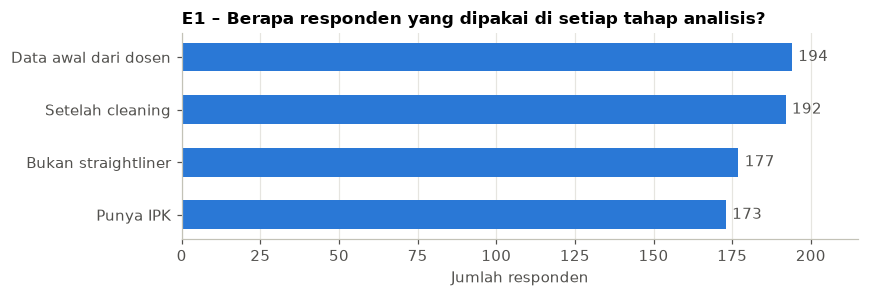

In [40]:
alur = pd.DataFrame({
    "Tahap": ["Data awal dari dosen", "Setelah cleaning", "Bukan straightliner", "Punya IPK"],
    "Responden": [len(raw), len(eda), int(ok.sum()), int(eda["IPK"].notna().sum())],
    "Alasan berkurang": ["-",
                         "2 respons kosong total dibuang (ID 11, 133)",
                         "15 straightliner: skor & label tetap ada, tetapi tidak dipakai di analisis skala 1-5",
                         "19 belum punya IPK (mahasiswa baru / tanpa data nilai)"],
})
display(alur)

fig, ax = plt.subplots(figsize=(8, 2.8))
y = alur["Tahap"][::-1]
x = alur["Responden"][::-1]
ax.barh(y, x, color=BIRU, height=0.55)
for yi, v in enumerate(x):
    ax.text(v + 2, yi, str(v), va="center", color=TEKS)
ax.set_xlim(0, 215)
ax.set_xlabel("Jumlah responden")
ax.grid(axis="y", visible=False)
ax.set_title("E1 – Berapa responden yang dipakai di setiap tahap analisis?")
simpan(fig, "E1_alur_data")

**Interpretasi:** hampir semua data bisa dipakai. Hanya 2 dari 194 respons (1%) yang dibuang karena kosong total. Semua 192 responden punya skor dan label. Analisis yang memakai skor skala 1–5 (Felder, Kolb, Honey-Mumford) memakai 177 orang, karena 15 straightliner menjawab angka yang sama untuk semua pernyataan sehingga tidak memberi informasi. Analisis yang melibatkan IPK memakai 173 orang.
**Yang tidak bisa disimpulkan:** grafik ini tidak menunjukkan kualitas jawaban; itu dibahas di E3.


## E2 – Variabel konteks: angkatan & IPK
**Pertanyaan:** siapa respondennya? Dataset tidak punya prodi/semester, jadi konteks yang tersedia adalah perkiraan angkatan (P1) dan IPK.

,Responden,IPK_terisi,IPK_median,IPK_min,IPK_maks
angkatan_inferred,,,,,
<=2023,18,18,3.60,3.03,3.98
2024,107,107,3.38,1.97,4.00
2025,48,48,3.42,0.87,3.93
2026,11,0,NaN,NaN,NaN
Tidak diketahui,8,0,NaN,NaN,NaN


IPK (n=173): median 3.42, Q1 3.19, Q3 3.67, min 0.87, skewness -1.64


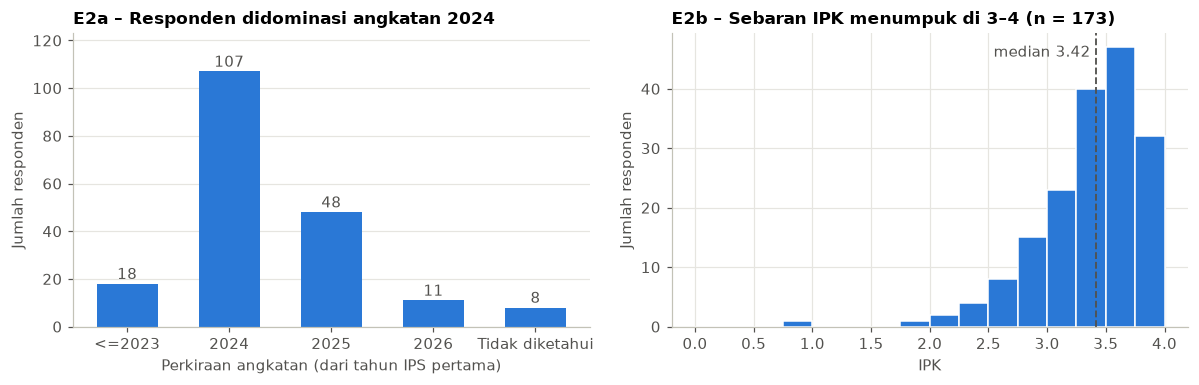

In [41]:
URUTAN_ANGKATAN = ["<=2023", "2024", "2025", "2026", "Tidak diketahui"]
angk = eda["angkatan_inferred"].value_counts().reindex(URUTAN_ANGKATAN)
ipk = eda["IPK"].dropna()

# 1) Ringkasan angka
display(eda.groupby("angkatan_inferred")["IPK"]
        .agg(Responden="size", IPK_terisi="count", IPK_median="median", IPK_min="min", IPK_maks="max")
        .reindex(URUTAN_ANGKATAN).round(2))
print(f"IPK (n={len(ipk)}): median {ipk.median():.2f}, Q1 {ipk.quantile(.25):.2f}, Q3 {ipk.quantile(.75):.2f}, "
      f"min {ipk.min():.2f}, skewness {ipk.skew():.2f}")

# 2) Grafik: kiri = jumlah per angkatan, kanan = sebaran IPK
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.bar(angk.index, angk.values, color=BIRU, width=0.6)
for xi, v in enumerate(angk.values):
    ax1.text(xi, v + 2, str(v), ha="center", color=TEKS)
ax1.set_ylim(0, angk.max() * 1.15)
ax1.set_ylabel("Jumlah responden")
ax1.set_xlabel("Perkiraan angkatan (dari tahun IPS pertama)")
ax1.grid(axis="x", visible=False)
ax1.set_title("E2a – Responden didominasi angkatan 2024")

ax2.hist(ipk, bins=[i / 4 for i in range(0, 17)], color=BIRU, edgecolor="white", linewidth=1)
ax2.axvline(ipk.median(), color=TEKS, linestyle="--", linewidth=1.2)
ax2.text(ipk.median() - 0.05, ax2.get_ylim()[1] * 0.92, f"median {ipk.median():.2f}", ha="right", color=TEKS)
ax2.set_xlabel("IPK")
ax2.set_ylabel("Jumlah responden")
ax2.set_title(f"E2b – Sebaran IPK menumpuk di 3–4 (n = {len(ipk)})")
simpan(fig, "E2_konteks_angkatan_ipk")

**Interpretasi:**
- Responden **didominasi angkatan 2024 (107 dari 192, 56%)**, jadi hasil EDA paling mewakili mahasiswa tahun kedua. Angkatan ≤2023 (18) dan 2026 (11) jumlahnya kecil, sehingga perbandingan antar-angkatan hanya bersifat deskriptif.
- IPK mayoritas tinggi: setengah responden ber-IPK 3,19–3,67 (median 3,42). Sebaran **miring ke kiri** (skewness −1,64) karena ada beberapa IPK sangat rendah (minimum 0,87). Karena itu analisis yang melibatkan IPK sebaiknya memakai median dan korelasi Spearman, bukan rata-rata dan Pearson.
- 19 responden (angkatan 2026 dan yang tidak diketahui angkatannya) belum punya IPK.

**Yang tidak bisa disimpulkan:** angkatan hanya **perkiraan** dari tahun IPS pertama, bukan data resmi. Dataset juga tidak berisi prodi, jadi sampel ini tidak bisa diklaim mewakili seluruh mahasiswa UAJY.

### E2 lanjutan – Apakah IPK berbeda antar-angkatan?
**Metode:** Kruskal-Wallis (membandingkan median beberapa kelompok tanpa asumsi normal), karena IPK miring.

Kruskal-Wallis IPK antar-angkatan: H = 5.25, p = 0.072


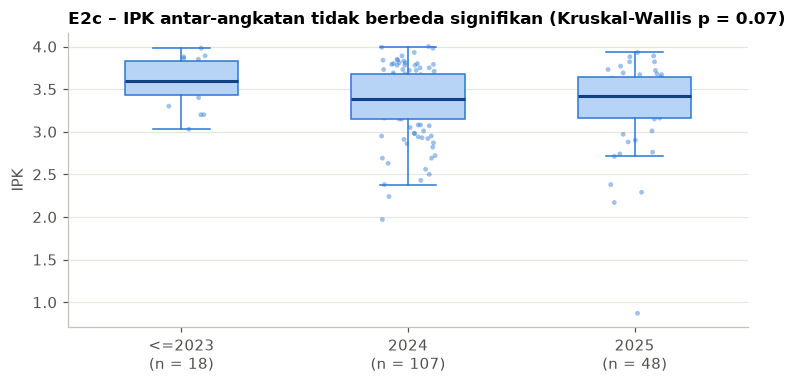

In [42]:
# E2 lanjutan: apakah IPK berbeda antar-angkatan? (hanya angkatan yang punya IPK)
grup_ipk = [a for a in URUTAN_ANGKATAN if eda.loc[eda["angkatan_inferred"] == a, "IPK"].notna().any()]
data_ipk = [eda.loc[eda["angkatan_inferred"] == a, "IPK"].dropna() for a in grup_ipk]
H, p_kw = stats.kruskal(*data_ipk)
print(f"Kruskal-Wallis IPK antar-angkatan: H = {H:.2f}, p = {p_kw:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.boxplot(data_ipk, tick_labels=[f"{a}\n(n = {len(d)})" for a, d in zip(grup_ipk, data_ipk)], widths=0.5,
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="#b7d3f6", edgecolor=BIRU), medianprops=dict(color="#104281", linewidth=2),
           whiskerprops=dict(color=BIRU), capprops=dict(color=BIRU))
rng = np.random.default_rng(0)
for i, d in enumerate(data_ipk, start=1):                 # titik individual (digeser acak agar tidak menumpuk)
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=10, color=BIRU, alpha=0.45, edgecolor="none")
ax.set_ylabel("IPK")
ax.grid(axis="x", visible=False)
ax.set_title(f"E2c – IPK antar-angkatan tidak berbeda signifikan (Kruskal-Wallis p = {p_kw:.2f})")
simpan(fig, "E2c_ipk_per_angkatan")

**Interpretasi:** median IPK angkatan ≤2023 (3,60) sedikit lebih tinggi dari 2024 (3,38) dan 2025 (3,42), tetapi perbedaannya **tidak signifikan** (p = 0,07). Kelompok ≤2023 juga kecil (18 orang).
**Yang tidak bisa disimpulkan:** tidak bisa dikatakan angkatan lama ber-IPK lebih tinggi; titik-titik individual menunjukkan sebaran yang tumpang tindih.

## E3 – Data kosong, pola jawaban, dan nilai ekstrem
**Pertanyaan:** di mana ada data kosong, apakah ada pola jawaban yang bisa mengganggu analisis, dan adakah nilai ekstrem?

,% kosong,Jumlah kosong,Alasan
IPS_2022_S1,99.5,191,Struktural: belum kuliah di semester itu
IPS_2022_S2,99.5,191,Struktural: belum kuliah di semester itu
IPS_2023_S1,90.6,174,Struktural: belum kuliah di semester itu
IPS_2023_S2,90.6,174,Struktural: belum kuliah di semester itu
IPS_2024_S1,34.9,67,Struktural: belum kuliah di semester itu
IPS_2024_S2,34.9,67,Struktural: belum kuliah di semester itu
IPS_2025_S1,9.9,19,Struktural: belum kuliah di semester itu
IPS_2025_S2,10.4,20,Struktural: belum kuliah di semester itu
IPS_2025_S3,91.7,176,Struktural: belum kuliah di semester itu
IPK,9.9,19,Belum punya IPK (mahasiswa baru / tanpa data)


Kolom survei (104 item) yang kosong: 0 sel
Kolom skor & label utama yang kosong: 0 sel


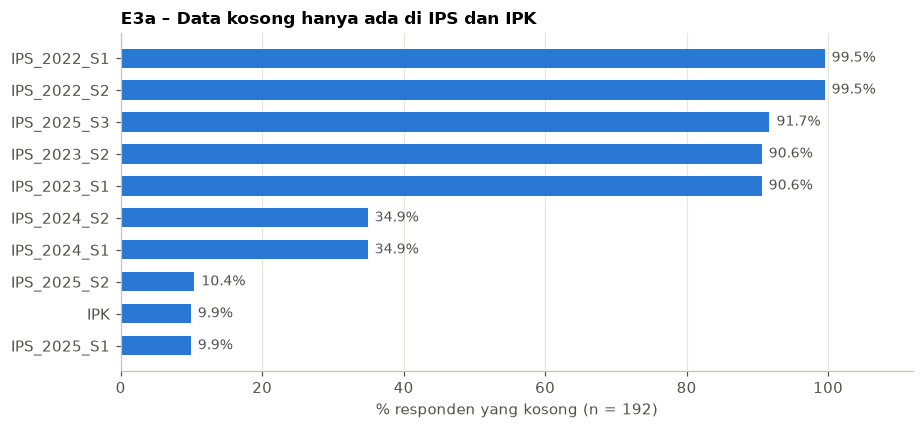

In [43]:
# ---------- a) Data kosong per kolom ----------
persen_kosong = eda.isna().mean().mul(100)
persen_kosong = persen_kosong[persen_kosong > 0]

def alasan_kosong(c):
    if c.startswith("IPS_"): return "Struktural: belum kuliah di semester itu"
    if c == "IPK":           return "Belum punya IPK (mahasiswa baru / tanpa data)"
    return "Straightliner: label teori (pembanding) sengaja dikosongkan"

tabel_kosong = (persen_kosong.round(1).rename("% kosong").to_frame()
                .assign(**{"Jumlah kosong": eda[persen_kosong.index].isna().sum(),
                           "Alasan": [alasan_kosong(c) for c in persen_kosong.index]}))
is_sl = tabel_kosong["Alasan"].str.startswith("Straightliner")
ringkas_kosong = tabel_kosong[~is_sl]
if is_sl.any():                          # kolom label teori yang kosong karena straightliner digabung jadi satu baris
    ringkas_kosong = pd.concat([ringkas_kosong, pd.DataFrame(
        {"% kosong": [tabel_kosong.loc[is_sl, "% kosong"].max()],
         "Jumlah kosong": [tabel_kosong.loc[is_sl, "Jumlah kosong"].max()],
         "Alasan": [f"Straightliner ({is_sl.sum()} kolom label teori)"]}, index=["Label teori (pembanding)"])])
display(ringkas_kosong)
print("Kolom survei (104 item) yang kosong:", int(eda[VARK_COLS + LIKERT_COLS].isna().sum().sum()), "sel")
print("Kolom skor & label utama yang kosong:",
      int(eda[JENIS_KOLOM["Score"] + JENIS_KOLOM["Label/profile"]].isna().sum().sum()), "sel")

fig, ax = plt.subplots(figsize=(8.5, 4))
data_plot = ringkas_kosong["% kosong"].sort_values()
ax.barh(data_plot.index, data_plot.values, color=BIRU, height=0.6)
for yi, v in enumerate(data_plot.values):
    ax.text(v + 1, yi, f"{v:.1f}%", va="center", color=TEKS, fontsize=9)
ax.set_xlim(0, 112)
ax.set_xlabel(f"% responden yang kosong (n = {len(eda)})")
ax.grid(axis="y", visible=False)
ax.set_title("E3a – Data kosong hanya ada di IPS dan IPK" + (" (dan label teori straightliner)" if is_sl.any() else ""))
simpan(fig, "E3a_data_kosong")


Rata-rata jawaban per responden: median 3.93 | % jawaban 4-5 seluruh data: 68.9%
Responden yang >= 80% jawabannya 4-5: 79 orang


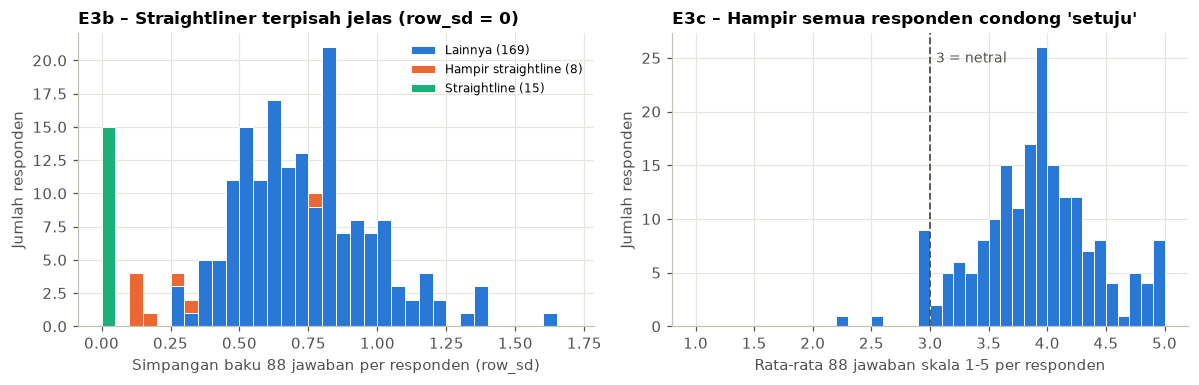

,n,Batas bawah,Batas atas,Di bawah,Di atas,Keputusan
IPK,173,2.47,4.39,8,0,Dipertahankan (nilai valid)
VARK_total,192,4.50,56.50,0,3,Dipertahankan (nilai valid)
FS_ACT_REF_score,177,-4.00,4.00,8,7,Dipertahankan (nilai valid)
FS_SEN_INT_score,177,-6.00,10.00,0,2,Dipertahankan (nilai valid)
FS_VIS_VRB_score,177,-5.50,6.50,5,6,Dipertahankan (nilai valid)
FS_SEQ_GLO_score,177,-4.50,7.50,3,8,Dipertahankan (nilai valid)
KOLB_ACCE,177,-6.50,5.50,8,4,Dipertahankan (nilai valid)
KOLB_AERO,177,-6.50,5.50,4,2,Dipertahankan (nilai valid)
HM_ACT_sum,177,19.00,43.00,1,0,Dipertahankan (nilai valid)
HM_REF_sum,177,21.50,41.50,1,0,Dipertahankan (nilai valid)


In [44]:
# ---------- b) Pola jawaban: variasi jawaban & kecenderungan setuju ----------
rata_jawaban = eda[LIKERT_COLS].astype(float).mean(axis=1)      # rata-rata 88 jawaban per orang
persen_setuju = (eda[LIKERT_COLS] >= 4).mean(axis=1) * 100
n_sl, n_near = int(eda["flag_straightline"].sum()), int(eda["flag_near_straight"].sum())
urut = [f"Lainnya ({len(eda) - n_sl - n_near})", f"Hampir straightline ({n_near})", f"Straightline ({n_sl})"]
kelompok = pd.Series(np.select([eda["flag_straightline"], eda["flag_near_straight"]], [urut[2], urut[1]], urut[0]),
                     index=eda.index)
print(f"Rata-rata jawaban per responden: median {rata_jawaban.median():.2f} | "
      f"% jawaban 4-5 seluruh data: {(eda[LIKERT_COLS] >= 4).to_numpy().mean() * 100:.1f}%")
print(f"Responden yang >= 80% jawabannya 4-5: {int((persen_setuju >= 80).sum())} orang")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.hist([eda.loc[kelompok == k, "row_sd"] for k in urut], bins=np.arange(0, 1.75, 0.05),
         stacked=True, color=[BIRU, ORANYE, HIJAU_TOSKA], label=urut, edgecolor="white", linewidth=0.6)
ax1.set_xlabel("Simpangan baku 88 jawaban per responden (row_sd)")
ax1.set_ylabel("Jumlah responden")
ax1.legend(frameon=False, fontsize=8)
ax1.set_title("E3b – Straightliner terpisah jelas (row_sd = 0)")

ax2.hist(rata_jawaban, bins=np.arange(1, 5.01, 0.1), color=BIRU, edgecolor="white", linewidth=0.6)
ax2.axvline(3, color=TEKS, linestyle="--", linewidth=1.2)
ax2.text(3.05, ax2.get_ylim()[1] * 0.9, "3 = netral", color=TEKS, fontsize=9)
ax2.set_xlabel("Rata-rata 88 jawaban skala 1-5 per responden")
ax2.set_ylabel("Jumlah responden")
ax2.set_title("E3c – Hampir semua responden condong 'setuju'")
simpan(fig, "E3b_pola_jawaban")

# ---------- c) Nilai ekstrem (aturan IQR, hanya ditandai) ----------
def ekstrem_iqr(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"n": len(s), "Batas bawah": round(bawah, 2), "Batas atas": round(atas, 2),
                      "Di bawah": int((s < bawah).sum()), "Di atas": int((s > atas).sum())})
kolom_numerik = (["IPK", "VARK_V", "VARK_A", "VARK_R", "VARK_K", "VARK_total"]
                 + [f"{d}_score" for d in FS_D] + ["KOLB_ACCE", "KOLB_AERO"] + [f"{g}_sum" for g in HM_G])
def subset(c):   # skor dari skala 1-5 dinilai tanpa straightliner (n = 177); VARK & IPK pakai semua
    return eda.loc[ok, c] if c.startswith(("FS_", "KOLB_", "HM_")) else eda[c]
tabel_ekstrem = pd.DataFrame({c: ekstrem_iqr(subset(c)) for c in kolom_numerik}).T.astype({"n": int, "Di bawah": int, "Di atas": int})
tabel_ekstrem = tabel_ekstrem[(tabel_ekstrem["Di bawah"] + tabel_ekstrem["Di atas"]) > 0]
tabel_ekstrem["Keputusan"] = "Dipertahankan (nilai valid)"
display(tabel_ekstrem)

**Interpretasi:**
- **Data kosong:** 104 item survei, semua skor, dan semua label utama tidak punya sel kosong. Kekosongan hanya ada di IPS (struktural, mengikuti angkatan) dan IPK (19 orang belum punya). Jadi kekosongan **tidak acak** dan **tidak diimputasi**.
- **Pola jawaban:** 15 straightliner (row_sd = 0) dan 8 hampir straightline terpisah jelas dari responden lain. Lebih penting lagi, **187 dari 192 responden rata-rata jawabannya ≥ 3**, dan 68,9% seluruh jawaban adalah 4/5. Ada kecenderungan menjawab "setuju" (*acquiescence*) yang membuat skor semua tipe sama-sama tinggi. Karena itu skor Felder dan Kolb memakai **selisih** antar-sisi, dan label HM/VARK hanya membandingkan skor di dalam diri responden sendiri.
- **Nilai ekstrem (aturan IQR):** misalnya 8 IPK di bawah 2,47. Semuanya nilai yang mungkin, jadi **dipertahankan** dan hanya ditandai.

**Yang tidak bisa disimpulkan:** aturan IQR hanya menandai nilai yang jauh dari mayoritas, bukan bukti nilai itu salah.


### E3 lanjutan – Bukti visual missing struktural pada IPS

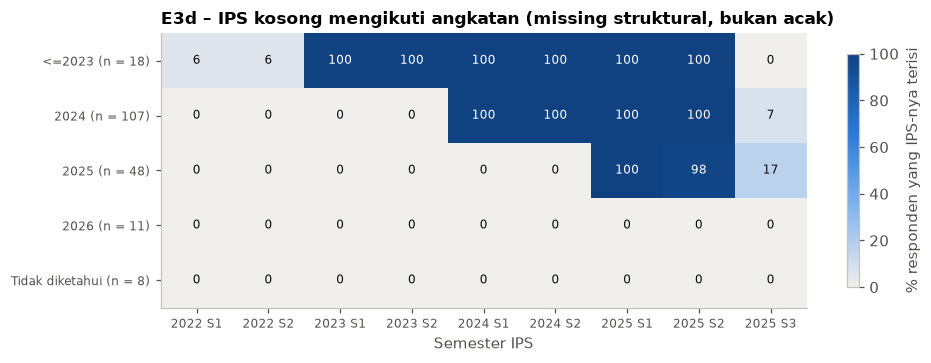

In [45]:
# E3 lanjutan: bukti visual bahwa IPS kosong mengikuti angkatan (missing struktural)
IPS_PLOT = [c for c in IPS_COLS if c in eda.columns]
terisi = (eda.groupby("angkatan_inferred")[IPS_PLOT].apply(lambda g: g.notna().mean() * 100)
          .reindex(URUTAN_ANGKATAN))
biru_seq = LinearSegmentedColormap.from_list("biru_seq", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(terisi, cmap=biru_seq, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(IPS_PLOT)), [c.replace("IPS_", "").replace("_", " ") for c in IPS_PLOT], fontsize=8)
ax.set_yticks(range(len(terisi)), [f"{a} (n = {(eda['angkatan_inferred'] == a).sum()})" for a in terisi.index], fontsize=8)
for i in range(terisi.shape[0]):
    for j in range(terisi.shape[1]):
        v = terisi.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "#0b0b0b")
ax.grid(False)
ax.set_xlabel("Semester IPS")
fig.colorbar(im, ax=ax, shrink=0.85, label="% responden yang IPS-nya terisi")
ax.set_title("E3d – IPS kosong mengikuti angkatan (missing struktural, bukan acak)")
simpan(fig, "E3d_pola_ips_per_angkatan")

**Interpretasi:** setiap angkatan punya IPS **100% terisi mulai semester pertamanya** dan 0% sebelumnya, seperti tangga. Ini membuktikan IPS kosong karena belum kuliah, bukan karena tidak diisi. IPS 2025 S3 hanya terisi 7–17% (kemungkinan semester pendek yang opsional), dan 6% di 2022 adalah 1 orang angkatan 2022.
**Yang tidak bisa disimpulkan:** angkatan sendiri diturunkan dari pola IPS ini, jadi grafik ini menunjukkan konsistensi datanya, bukan validasi independen terhadap angkatan resmi.

## E4 – Distribusi skor tiap framework
**Pertanyaan:** bagaimana sebaran skor di tiap framework, dan apakah item dalam satu tipe konsisten (Cronbach's alpha)?

n  Median    Q1    Q3  Min  Maks
Framework        Skor                                                
VARK             VARK_V            192     7.0   4.0  11.0    0    16
                 VARK_A            192     8.0   6.0  11.0    0    16
                 VARK_R            192     7.0   4.0  10.0    0    16
                 VARK_K            192     8.0   5.0  12.0    0    16
Felder-Silverman FS_ACT_REF_score  177     0.0  -1.0   1.0   -8    15
                 FS_SEN_INT_score  177     1.0   0.0   4.0   -5    12
                 FS_VIS_VRB_score  177     0.0  -1.0   2.0   -9    13
                 FS_SEQ_GLO_score  177     0.0   0.0   3.0   -6    11
Kolb             KOLB_CE_sum       177    24.0  22.0  27.0   10    30
                 KOLB_RO_sum       177    24.0  21.0  26.0   14    30
                 KOLB_AC_sum       177    24.0  21.0  26.0   11    30
                 KOLB_AE_sum       177    23.0  20.0  26.0   11    30
Honey-Mumford    HM_ACT_sum        177    31.0  28.0  34.0   18    40
                 HM_REF_sum        177    32.0  29.0  34.0   14    40
                 HM_THE_sum        177    32.0  29.0  35.0   14    40
                 HM_PRA_sum        177    32.0  29.0  36.0   19    40

Cronbach's alpha 16 subskala (n = 177): min 0.70 (FS_GLO), maks 0.86 (KOLB_CE); >= 0.70: 15 dari 16


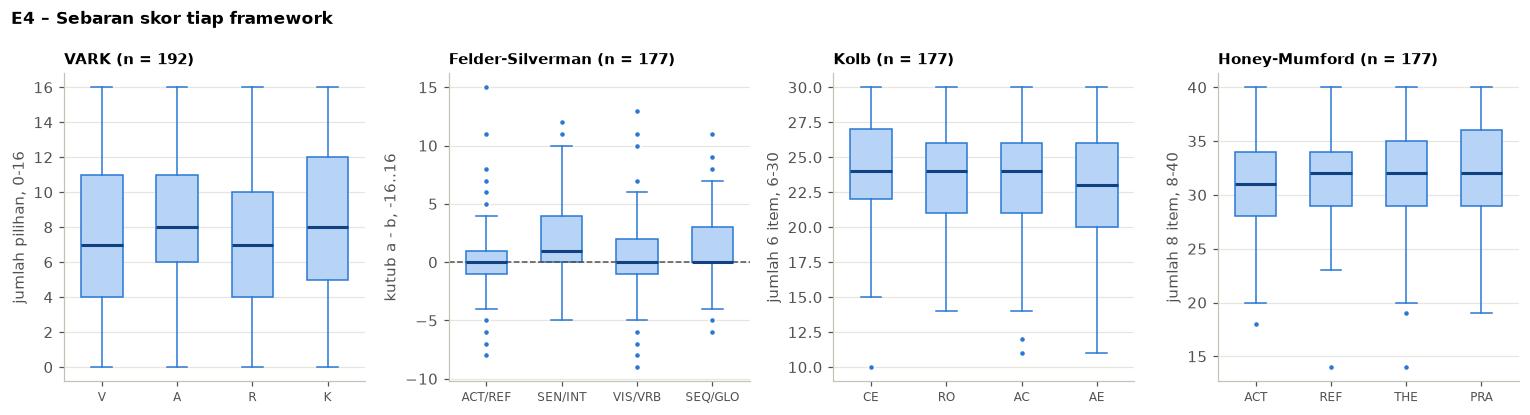

In [46]:
def cronbach_alpha(item):
    """Konsistensi internal sekelompok item (>= 0.70 dianggap memadai)."""
    item = item.astype(float).dropna()
    k = item.shape[1]
    return k / (k - 1) * (1 - item.var(ddof=1).sum() / item.sum(axis=1).var(ddof=1))

# 1) Ringkasan skor (VARK: n = 192; skor dari skala 1-5: n = 177 tanpa straightliner)
SKOR = {
    "VARK (jumlah pilihan, 0-16)":           ["VARK_V", "VARK_A", "VARK_R", "VARK_K"],
    "Felder-Silverman (kutub a - b, -16..16)": [f"{d}_score" for d in FS_D],
    "Kolb (jumlah 6 item, 6-30)":            [f"KOLB_{m}_sum" for m in KM],
    "Honey-Mumford (jumlah 8 item, 8-40)":   [f"{g}_sum" for g in HM_G],
}
baris = []
for fw, kol in SKOR.items():
    data = eda[kol] if fw.startswith("VARK") else eda.loc[ok, kol]
    for c in kol:
        s = data[c]
        baris.append({"Framework": fw.split(" (")[0], "Skor": c, "n": s.notna().sum(),
                      "Median": s.median(), "Q1": s.quantile(.25), "Q3": s.quantile(.75),
                      "Min": s.min(), "Maks": s.max()})
display(pd.DataFrame(baris).set_index(["Framework", "Skor"]).round(2))

# 2) Reliabilitas: apakah item dalam satu subskala konsisten? (n = 177)
subskala = {f"{g}": [c for c in LIKERT_COLS if c.startswith(f"{g}_")]
            for g in ["HM_ACT", "HM_REF", "HM_THE", "HM_PRA", "FS_ACT", "FS_REF", "FS_SEN", "FS_INT",
                      "FS_VIS", "FS_VRB", "FS_SEQ", "FS_GLO", "KOLB_CE", "KOLB_RO", "KOLB_AC", "KOLB_AE"]}
alpha = pd.Series({s: cronbach_alpha(eda.loc[ok, item]) for s, item in subskala.items()}).round(3)
print(f"Cronbach's alpha 16 subskala (n = {int(ok.sum())}): min {alpha.min():.2f} ({alpha.idxmin()}), "
      f"maks {alpha.max():.2f} ({alpha.idxmax()}); >= 0.70: {int((alpha >= 0.70).sum())} dari 16")

# 3) Grafik: boxplot per framework
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (fw, kol) in zip(axes, SKOR.items()):
    data = eda[kol] if fw.startswith("VARK") else eda.loc[ok, kol]
    label = [c.replace("VARK_", "").replace("_score", "").replace("FS_", "").replace("KOLB_", "")
              .replace("_sum", "").replace("HM_", "").replace("_", "/") for c in kol]
    ax.boxplot([data[c].dropna() for c in kol], tick_labels=label, widths=0.55, patch_artist=True,
               boxprops=dict(facecolor="#b7d3f6", edgecolor=BIRU), medianprops=dict(color="#104281", linewidth=2),
               whiskerprops=dict(color=BIRU), capprops=dict(color=BIRU),
               flierprops=dict(marker="o", markersize=4, markerfacecolor=BIRU, markeredgecolor="white"))
    if "Felder" in fw:
        ax.axhline(0, color=TEKS, linestyle="--", linewidth=1)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{fw.split(' (')[0]} (n = {len(data)})", fontsize=10)
    ax.set_ylabel(fw[fw.index("(") + 1:-1])
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("E4 – Sebaran skor tiap framework", x=0.01, ha="left", fontweight="bold", fontsize=11)
simpan(fig, "E4_distribusi_skor")

**Interpretasi:**
- **VARK:** median keempat modalitas mirip (7–8 dari 16), sebarannya lebar. Tidak ada modalitas yang mendominasi seluruh kelas.
- **Felder:** skor menumpuk di sekitar 0 (seimbang). Hanya SEN-INT yang condong positif (median +1), artinya responden sedikit lebih suka fakta/contoh konkret.
- **Kolb & Honey-Mumford:** median keempat tahap/gaya hampir sama (Kolb 23–24, HM 31–32). Skor mentah saja sulit membedakan tipe; ini sejalan dengan temuan *acquiescence* di E3.
- **Reliabilitas:** Cronbach's alpha 16 subskala berkisar 0,70–0,86 (terendah FS_GLO 0,699). Item dalam satu tipe cukup konsisten, sehingga pengelompokan item untuk scoring bisa dipertanggungjawabkan.

**Yang tidak bisa disimpulkan:** skor antar-framework tidak bisa dibandingkan langsung karena satuannya berbeda (VARK 0–16, Felder −16..16, Kolb 6–30, HM 8–40).

### E4 lanjutan – Peta dua selisih Kolb
Setiap responden ditempatkan pada d1 = AC − CE dan d2 = AE − RO. Label Kolb ditentukan dari **tanda** keduanya (garis 0), bukan dari batas norma.


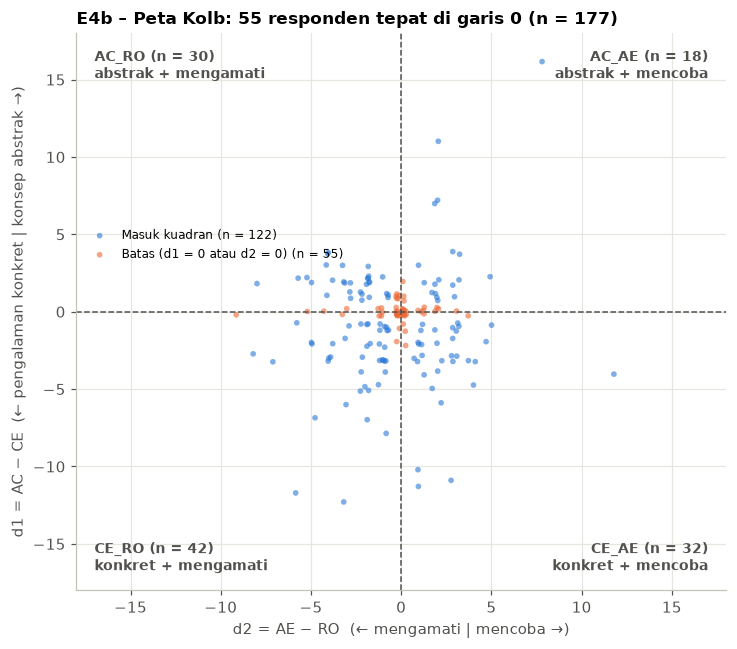

Tepat di garis: d1 = 0 -> 42, d2 = 0 -> 35, keduanya -> 22; 15 straightliner semuanya di titik (0, 0) -> Batas


In [47]:
# E4 lanjutan: peta d1 (AC-CE) vs d2 (AE-RO), garis batas = 0 (aturan panduan dosen); n = 177 tanpa straightliner
x_k = eda.loc[ok, "KOLB_AERO"]; y_k = eda.loc[ok, "KOLB_ACCE"]
di_batas = (x_k == 0) | (y_k == 0)
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(6.8, 6))
for maske, warna, nama in [(~di_batas, BIRU, "Masuk kuadran"), (di_batas, ORANYE, "Batas (d1 = 0 atau d2 = 0)")]:
    ax.scatter(x_k[maske] + rng.uniform(-0.3, 0.3, maske.sum()), y_k[maske] + rng.uniform(-0.3, 0.3, maske.sum()),
               s=14, color=warna, alpha=0.6, edgecolor="none", label=f"{nama} (n = {int(maske.sum())})")
ax.axvline(0, color=TEKS, linestyle="--", linewidth=1)
ax.axhline(0, color=TEKS, linestyle="--", linewidth=1)
batas = max(x_k.abs().max(), y_k.abs().max()) + 2
ax.set_xlim(-batas, batas); ax.set_ylim(-batas, batas)
jumlah = eda.loc[ok, "KOLB_label"].value_counts()
for kode, (xx, yy, ha, va, arti) in {"CE_AE": (batas - 1, -batas + 1, "right", "bottom", "konkret + mencoba"),
                                     "CE_RO": (-batas + 1, -batas + 1, "left", "bottom", "konkret + mengamati"),
                                     "AC_RO": (-batas + 1, batas - 1, "left", "top", "abstrak + mengamati"),
                                     "AC_AE": (batas - 1, batas - 1, "right", "top", "abstrak + mencoba")}.items():
    ax.text(xx, yy, f"{kode} (n = {jumlah.get(kode, 0)})\n{arti}", ha=ha, va=va, fontsize=9, color=TEKS, fontweight="bold")
ax.set_xlabel("d2 = AE − RO  (← mengamati | mencoba →)")
ax.set_ylabel("d1 = AC − CE  (← pengalaman konkret | konsep abstrak →)")
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(0, 0.62))
ax.set_title(f"E4b – Peta Kolb: {int(di_batas.sum())} responden tepat di garis 0 (n = {int(ok.sum())})")
simpan(fig, "E4b_peta_kolb")
print(f"Tepat di garis: d1 = 0 -> {int((y_k == 0).sum())}, d2 = 0 -> {int((x_k == 0).sum())}, keduanya -> {int(((x_k == 0) & (y_k == 0)).sum())}; "
      f"15 straightliner semuanya di titik (0, 0) -> Batas")


**Interpretasi:** sebagian besar responden mengumpul di dekat titik (0, 0), artinya preferensi Kolb mereka **tidak kuat ke arah mana pun**. Sebanyak 55 dari 177 orang (31%) tepat di garis 0 (d1 = 0: 42 orang, d2 = 0: 35 orang, keduanya: 22 orang), sehingga labelnya **Batas**. Ditambah 15 straightliner yang semuanya di (0, 0), Batas menjadi 70 orang. Di antara yang masuk kuadran, CE_RO (konkret + mengamati) paling banyak (42) dan AC_AE (abstrak + mencoba) paling sedikit (18).
**Yang tidak bisa disimpulkan:** titik di dekat garis 0 bisa pindah kuadran hanya karena beda satu jawaban; Batas menandai preferensi yang seimbang, bukan "tipe kelima".


## E5 – Distribusi label & ketidakseimbangan kelas
**Pertanyaan:** bagaimana sebaran label tiap framework, seberapa besar kategori operasional (Seri/Setara/Batas), dan apakah ada kelas yang terlalu kecil untuk modelling?


,n,Distribusi,% Seri/Setara/Batas,Kelas terkecil,Rasio terbesar:terkecil,Kira-kira di test 20%,15 straightliner masuk ke
Label,,,,,,,
VARK_label,192,"Visual=38, Aural=42, Read/Write=31, Kinesthetic=51, Seri=30",15.6,Seri = 30 (16%),1.7,6-10 per kelas,"Aural, Seri, Read/Write, Kinesthetic"
FS_ACT_REF_label,192,"Active=67, Reflective=64, Setara=61",31.8,Setara = 61 (32%),1.1,12-13 per kelas,Setara
HM_label,192,"Activist=18, Reflector=36, Theorist=31, Pragmatist=43, Seri=64",33.3,Activist = 18 (9%),3.6,4-13 per kelas,Seri
KOLB_label,192,"CE_RO=42, AC_RO=30, AC_AE=18, CE_AE=32, Batas=70",36.5,AC_AE = 18 (9%),3.9,4-14 per kelas,Batas


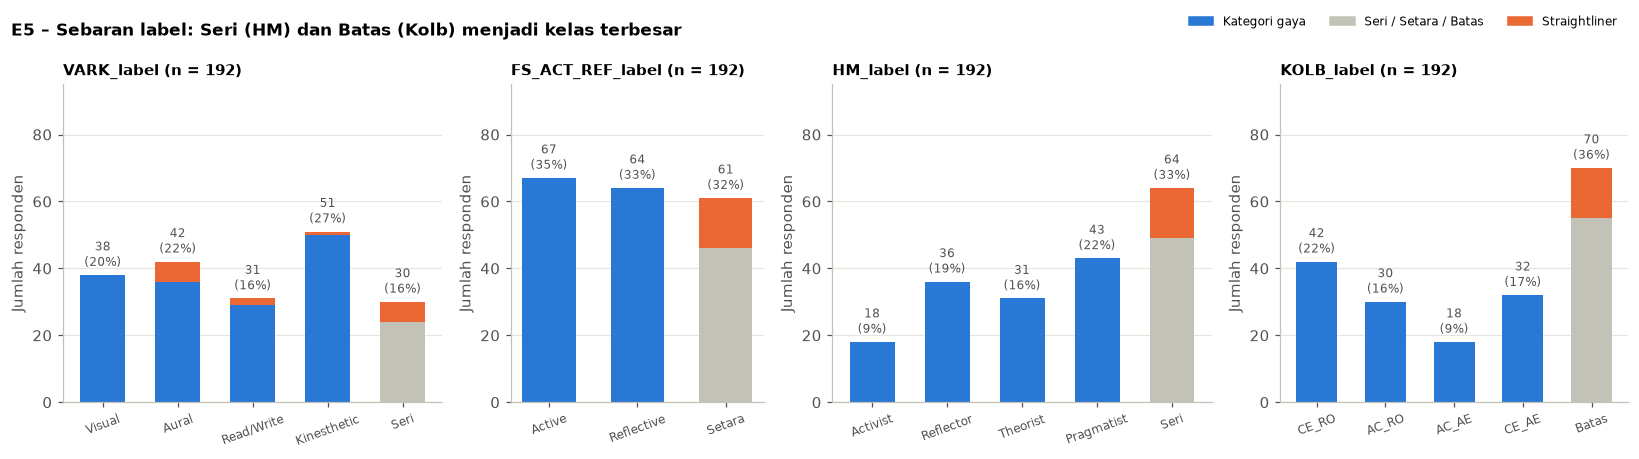

In [48]:
# 1) Tabel frekuensi tiap label (satu y per framework); kategori operasional = aturan tugas, bukan gaya belajar
URUT_LABEL = {
    "VARK_label":       ["Visual", "Aural", "Read/Write", "Kinesthetic", "Seri"],
    "FS_ACT_REF_label": ["Active", "Reflective", "Setara"],
    "HM_label":         ["Activist", "Reflector", "Theorist", "Pragmatist", "Seri"],
    "KOLB_label":       ["CE_RO", "AC_RO", "AC_AE", "CE_AE", "Batas"],
}
OPERASIONAL = ["Seri", "Setara", "Batas"]
sl = eda["flag_straightline"]

ringkas_label = []
for kol, urut in URUT_LABEL.items():
    n = eda[kol].value_counts().reindex(urut).fillna(0).astype(int)
    ringkas_label.append({"Label": kol, "n": int(n.sum()),
                          "Distribusi": ", ".join(f"{k}={v}" for k, v in n.items()),
                          "% Seri/Setara/Batas": round(n[n.index.isin(OPERASIONAL)].sum() / n.sum() * 100, 1),
                          "Kelas terkecil": f"{n.idxmin()} = {n.min()} ({n.min() / n.sum() * 100:.0f}%)",
                          "Rasio terbesar:terkecil": round(n.max() / n.min(), 1),
                          "Kira-kira di test 20%": f"{n.min() * 0.2:.0f}-{n.max() * 0.2:.0f} per kelas",
                          "15 straightliner masuk ke": ", ".join(eda.loc[sl, kol].value_counts().index)})
ringkas_label = pd.DataFrame(ringkas_label).set_index("Label")
display(ringkas_label)

# 2) Grafik: 4 label (satu y per framework); abu-abu = Seri/Setara/Batas, oranye = straightliner
from matplotlib.patches import Patch
fig, axes = plt.subplots(1, 4, figsize=(15, 4.1), gridspec_kw={"width_ratios": [1.2, 0.8, 1.2, 1.1]})
for ax, kol in zip(axes, URUT_LABEL):
    urut = URUT_LABEL[kol]
    n_ok = eda.loc[~sl, kol].value_counts().reindex(urut).fillna(0).astype(int)
    n_sl = eda.loc[sl, kol].value_counts().reindex(urut).fillna(0).astype(int)
    ax.bar(urut, n_ok.values, color=[ABU if k in OPERASIONAL else BIRU for k in urut], width=0.6)
    ax.bar(urut, n_sl.values, bottom=n_ok.values, color=ORANYE, width=0.6)
    total = n_ok + n_sl
    for xi, v in enumerate(total.values):
        ax.text(xi, v + 1.5, f"{v}\n({v / total.sum() * 100:.0f}%)", ha="center", va="bottom", fontsize=8, color=TEKS)
    ax.set_ylim(0, 95)
    ax.set_title(f"{kol} (n = {total.sum()})", fontsize=10)
    ax.set_ylabel("Jumlah responden")
    ax.tick_params(axis="x", labelsize=8, rotation=20)
    ax.grid(axis="x", visible=False)
fig.legend(handles=[Patch(color=BIRU, label="Kategori gaya"), Patch(color=ABU, label="Seri / Setara / Batas"),
                    Patch(color=ORANYE, label="Straightliner")], frameon=False, fontsize=8, ncol=3,
           loc="upper right", bbox_to_anchor=(0.99, 1.02))
fig.suptitle("E5 – Sebaran label: Seri (HM) dan Batas (Kolb) menjadi kelas terbesar", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
simpan(fig, "E5_distribusi_label")


**Interpretasi:**
- **FS_ACT_REF_label paling seimbang** (67 / 64 / 61, rasio 1,1), tetapi sepertiganya (32%) Setara, dan 15 dari 61 Setara berasal dari straightliner.
- **VARK_label cukup seimbang** (rasio 1,7); kelas terkecil Seri (30 orang, 16%). VARK tidak terpengaruh straightliner karena formatnya pilihan, bukan skala 1–5.
- **HM dan Kolb didominasi kategori operasional:** Seri 33% (HM) dan Batas 36% (Kolb) menjadi kelas terbesar, sementara Activist dan AC_AE hanya 18 orang (9%).
- **Ke-15 straightliner semuanya jatuh ke Setara/Seri/Batas** pada Felder, HM, dan Kolb. Keputusan memakai atau mengecualikan mereka saat modelling akan mengubah ukuran kelas tersebut.

**Dampak untuk modelling (UAS):** kelas 9% hanya sekitar 4 contoh di test set 20%, jadi split perlu **stratifikasi**, metrik utama sebaiknya **macro-F1** (bukan hanya accuracy), dan analisis kesalahan perlu melihat kelas minoritas serta kategori Seri/Setara/Batas yang skornya berdekatan.
**Yang tidak bisa disimpulkan:** Seri/Setara/Batas adalah aturan operasional tugas, bukan gaya belajar kelima. Karena label dihitung dari item yang sama dengan fitur X, model nanti hanya meniru aturan scoring, bukan membuktikan teori gaya belajar.


## E6 – Hubungan antar-skor (korelasi sesuai tipe data)
**Pertanyaan:** skor mana yang saling berhubungan, dan apakah gaya belajar berhubungan dengan IPK?
**Metode:** Spearman ρ, karena skor bersifat ordinal/hitungan dan IPK miring (tidak memakai Pearson). Uji ke IPK dikoreksi untuk uji berganda (FDR). Label kategorikal **tidak** dikorelasikan di sini (lihat E7).

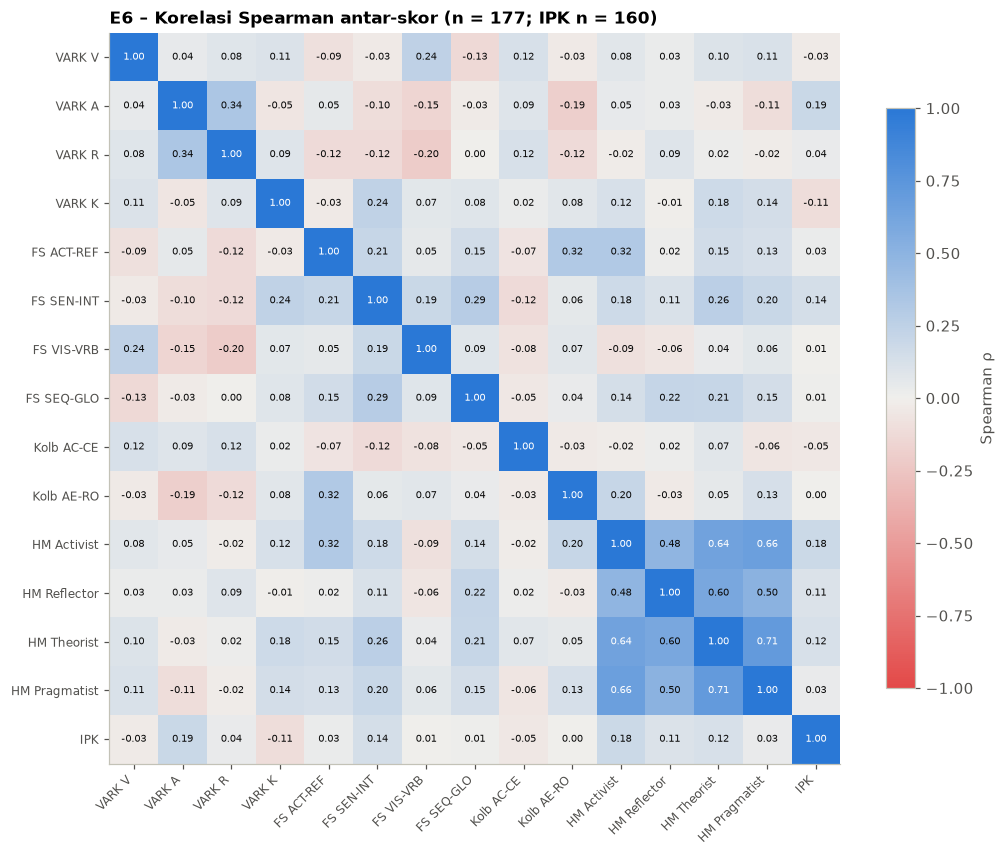

,Pasangan,rho,p
0,HM Activist ~ Kolb AE-RO,0.20,0.0063
1,HM Reflector ~ Kolb AE-RO,-0.03,0.6463
2,HM Theorist ~ Kolb AC-CE,0.07,0.3445
3,HM Activist ~ FS ACT-REF,0.32,0.0000
4,VARK V ~ FS VIS-VRB,0.24,0.0011
5,VARK K ~ HM Activist,0.12,0.1052


Korelasi dengan IPK (n = 160): |rho| maks 0.19; p < 0.05: 2 dari 14; signifikan setelah FDR: 0


,Skor,rho,p,q (FDR)
1,VARK A,0.189,0.017,0.155
10,HM Activist,0.181,0.022,0.155
5,FS SEN-INT,0.136,0.087,0.405
12,HM Theorist,0.124,0.118,0.413
11,HM Reflector,0.109,0.170,0.413


In [49]:
# Variabel numerik/ordinal -> Spearman (tidak mengasumsikan sebaran normal; IPK juga miring)
VAR_NUM = {"VARK_V": "VARK V", "VARK_A": "VARK A", "VARK_R": "VARK R", "VARK_K": "VARK K",
           "FS_ACT_REF_score": "FS ACT-REF", "FS_SEN_INT_score": "FS SEN-INT",
           "FS_VIS_VRB_score": "FS VIS-VRB", "FS_SEQ_GLO_score": "FS SEQ-GLO",
           "KOLB_ACCE": "Kolb AC-CE", "KOLB_AERO": "Kolb AE-RO",
           "HM_ACT_sum": "HM Activist", "HM_REF_sum": "HM Reflector",
           "HM_THE_sum": "HM Theorist", "HM_PRA_sum": "HM Pragmatist", "IPK": "IPK"}
data_kor = eda.loc[ok, list(VAR_NUM)].astype(float).rename(columns=VAR_NUM)     # n = 177 (IPK: 160)
rho = data_kor.corr(method="spearman")

# 1) Heatmap korelasi Spearman
cmap = LinearSegmentedColormap.from_list("biru_merah", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(rho, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(rho)), rho.index, fontsize=8)
for i in range(len(rho)):
    for j in range(len(rho)):
        ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(rho.iloc[i, j]) > 0.6 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title(f"E6 – Korelasi Spearman antar-skor (n = {int(ok.sum())}; IPK n = {int(data_kor['IPK'].notna().sum())})")
simpan(fig, "E6_korelasi_spearman")

# 2) Pasangan yang secara teori berhubungan (lintas framework)
pasangan = [("HM Activist", "Kolb AE-RO"), ("HM Reflector", "Kolb AE-RO"), ("HM Theorist", "Kolb AC-CE"),
            ("HM Activist", "FS ACT-REF"), ("VARK V", "FS VIS-VRB"), ("VARK K", "HM Activist")]
tabel_pasangan = pd.DataFrame([{"Pasangan": f"{a} ~ {b}", "rho": round(rho.loc[a, b], 2),
                                "p": stats.spearmanr(data_kor[a], data_kor[b]).pvalue} for a, b in pasangan])
display(tabel_pasangan.round({"p": 4}))

# 3) Hubungan dengan IPK + koreksi uji berganda (Benjamini-Hochberg / FDR)
d_ipk = data_kor.dropna(subset=["IPK"])
uji = pd.DataFrame([{"Skor": c, "rho": stats.spearmanr(d_ipk[c], d_ipk["IPK"]).statistic,
                     "p": stats.spearmanr(d_ipk[c], d_ipk["IPK"]).pvalue} for c in rho.columns if c != "IPK"])
uji["q (FDR)"] = stats.false_discovery_control(uji["p"])
print(f"Korelasi dengan IPK (n = {len(d_ipk)}): |rho| maks {uji['rho'].abs().max():.2f}; "
      f"p < 0.05: {int((uji['p'] < .05).sum())} dari {len(uji)}; signifikan setelah FDR: {int((uji['q (FDR)'] < .05).sum())}")
display(uji.sort_values("rho", key=abs, ascending=False).round(3).head(5))

**Interpretasi:**
- Keempat skor **Honey-Mumford saling berkorelasi positif kuat (ρ 0,48–0,71)**. Orang yang tinggi di satu gaya cenderung tinggi di semua gaya: efek *acquiescence* dari E3.
- Hubungan lintas framework yang konsisten dengan teori ada, tetapi lemah sampai sedang: HM Activist ~ FS ACT-REF ρ = 0,32; HM Activist ~ Kolb AE-RO ρ = 0,20; VARK V ~ FS VIS-VRB ρ = 0,24.
- Sebagian pasangan yang secara teori seharusnya berhubungan justru hampir nol, misalnya HM Theorist ~ Kolb AC-CE (ρ = 0,07). Framework yang namanya mirip **tidak otomatis mengukur hal yang sama**.
- **Gaya belajar vs IPK:** semua |ρ| ≤ 0,19; 2 dari 14 uji p < 0,05, tetapi **tidak ada yang signifikan setelah koreksi FDR**.

**Yang tidak bisa disimpulkan:** korelasi bukan sebab-akibat. Tidak ada bukti gaya belajar tertentu menghasilkan IPK lebih tinggi di sampel ini.

### E6 lanjutan – Label gaya belajar vs IPK
**Metode:** label kategorikal vs IPK (numerik) diuji dengan **Kruskal-Wallis** dan ukuran efek **ε²** (0,01 kecil, 0,08 sedang, 0,26 besar), bukan korelasi. Label yang signifikan diuji lanjut berpasangan (Mann-Whitney + Bonferroni).

,n,Jumlah kelompok,H,p,epsilon²
Label,,,,,
VARK_label,173,5,18.206,0.001,0.085
FS_ACT_REF_label,160,3,1.191,0.551,0.000
HM_label,160,5,5.514,0.239,0.010
KOLB_label,160,5,1.774,0.777,0.000


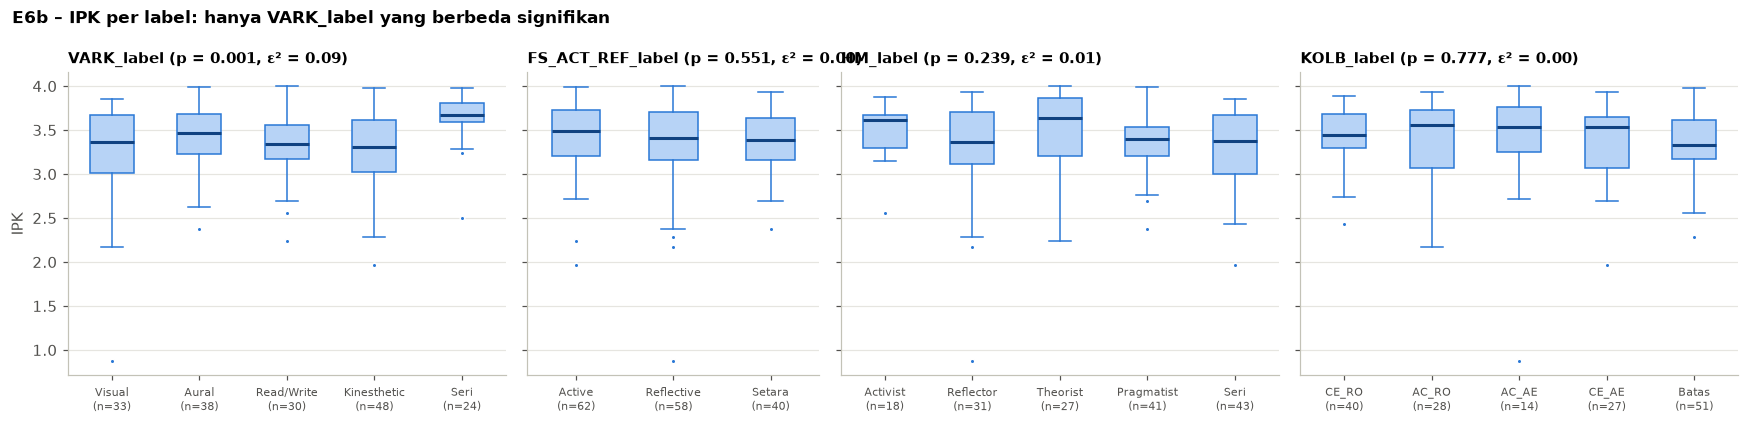

Post-hoc VARK_label:


,Pasangan,Median a,Median b,p (Bonferroni)
9,Kinesthetic vs Seri,3.305,3.675,0.001
8,Read/Write vs Seri,3.345,3.675,0.014
3,Visual vs Seri,3.370,3.675,0.029
6,Aural vs Seri,3.470,3.675,0.224
5,Aural vs Kinesthetic,3.470,3.305,0.499


In [50]:
# E6 lanjutan: label (kategorikal) vs IPK (numerik) -> Kruskal-Wallis + effect size epsilon^2
def kruskal_eps(df_, label, nilai="IPK"):
    d = df_[[label, nilai]].dropna()
    grup = [g[nilai].values for _, g in d.groupby(label)]
    H, p = stats.kruskal(*grup)
    k, n = len(grup), len(d)
    return n, k, H, p, max((H - k + 1) / (n - k), 0)

# VARK memakai semua responden; label dari skala 1-5 tanpa straightliner (jawabannya tidak informatif)
LABEL_IPK = {"VARK_label": eda, "FS_ACT_REF_label": eda.loc[ok], "HM_label": eda.loc[ok], "KOLB_label": eda.loc[ok]}
hasil_kw = pd.DataFrame([dict(zip(["Label", "n", "Jumlah kelompok", "H", "p", "epsilon²"], (lb, *kruskal_eps(d, lb))))
                         for lb, d in LABEL_IPK.items()]).set_index("Label").round(3)
display(hasil_kw)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True, gridspec_kw={"width_ratios": [1.2, 0.8, 1.2, 1.2]})
for ax, (lb, d) in zip(axes, LABEL_IPK.items()):
    urut_lb = [k for k in URUT_LABEL[lb] if k in d[lb].dropna().unique()]
    data_lb = [d.loc[d[lb] == k, "IPK"].dropna() for k in urut_lb]
    ax.boxplot(data_lb, tick_labels=[f"{k}\n(n={len(v)})" for k, v in zip(urut_lb, data_lb)], widths=0.5,
               patch_artist=True, showfliers=True,
               boxprops=dict(facecolor="#b7d3f6", edgecolor=BIRU), medianprops=dict(color="#104281", linewidth=2),
               whiskerprops=dict(color=BIRU), capprops=dict(color=BIRU),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=BIRU, markeredgecolor="white"))
    ax.tick_params(axis="x", labelsize=7.5)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{lb} (p = {hasil_kw.loc[lb, 'p']:.3f}, ε² = {hasil_kw.loc[lb, 'epsilon²']:.2f})", fontsize=10)
axes[0].set_ylabel("IPK")
sig = list(hasil_kw.index[hasil_kw["p"] < 0.05])
fig.suptitle("E6b – IPK per label: " + (f"hanya {', '.join(sig)} yang berbeda signifikan" if sig else "tidak ada label yang berbeda signifikan"),
             x=0.01, ha="left", fontweight="bold", fontsize=11)
simpan(fig, "E6b_ipk_per_label")

# Uji lanjutan (post-hoc) untuk label yang p < 0.05: Mann-Whitney berpasangan + koreksi Bonferroni
from itertools import combinations
for lb in sig:
    d = LABEL_IPK[lb]; kel = [k for k in URUT_LABEL[lb] if k in d[lb].dropna().unique()]
    pas = list(combinations(kel, 2))
    posthoc = pd.DataFrame([{"Pasangan": f"{a} vs {b}",
                             "Median a": d.loc[d[lb] == a, "IPK"].median(), "Median b": d.loc[d[lb] == b, "IPK"].median(),
                             "p (Bonferroni)": min(stats.mannwhitneyu(d.loc[d[lb] == a, "IPK"].dropna(),
                                                                       d.loc[d[lb] == b, "IPK"].dropna()).pvalue * len(pas), 1)}
                            for a, b in pas]).round(3)
    print(f"Post-hoc {lb}:"); display(posthoc.sort_values("p (Bonferroni)").head(5))


**Interpretasi:**
- Label Felder (Active–Reflective), Honey-Mumford, dan Kolb **tidak berhubungan** dengan IPK (p = 0,55; 0,24; 0,78; ε² ≈ 0).
- `VARK_label` berbeda signifikan (p = 0,001) dengan efek **sedang-kecil** (ε² = 0,09). Uji lanjut menunjukkan bedanya berasal dari kelompok **Seri**: median IPK Seri 3,68 (n = 24) lebih tinggi dari Kinesthetic 3,30, Read/Write 3,34, dan Visual 3,37 (p Bonferroni 0,001–0,03). Antar-modalitas tunggal tidak berbeda.
- Ini bukan karena memilih lebih banyak opsi: total pilihan VARK tidak berkorelasi dengan IPK (ρ = 0,05). Responden Seri adalah yang dua atau lebih modalitasnya sama kuat.

**Yang tidak bisa disimpulkan:** temuan ini bukan bukti bahwa preferensi seimbang membuat IPK lebih tinggi. Kelompok Seri kecil (24 orang dengan IPK), ada banyak uji sekaligus, dan urutan waktu survei vs IPK tidak diketahui.


### E6 lanjutan – Kesiapan regresi: target IPK dan fitur item
**Pertanyaan:** bagaimana statistik IPK setelah cleaning, dan seberapa kuat hubungan **setiap item** (calon fitur X regresi) dengan IPK?
**Metode:** Spearman tiap item vs IPK, dengan koreksi FDR per framework. Item Likert memakai responden tanpa straightliner; indikator VARK memakai semua responden ber-IPK.


,IPK (setelah cleaning)
n terisi,173.00
rata-rata,3.36
simpangan baku,0.45
min,0.87
Q1,3.19
median,3.42
Q3,3.67
max,4.00
kemiringan (skew),-1.63


,Jumlah
IPK 0 tanpa IPS -> NaN (C6),4
IPK kosong setelah cleaning (tidak dipakai sebagai target),19
IPK di luar 0-4,0
"IPK ekstrem bawah (< Q1 - 1,5 IQR), dipertahankan",8
IPK dipakai sebagai target regresi,173


,n,Jumlah fitur,|rho| maks,Item terkuat,p < 0.05,Signifikan setelah FDR
Framework,,,,,,
VARK (64 indikator),173,64,0.20,VARK_Q01_A (+0.20),5,0
Felder (32 item),160,32,0.22,FS_SEN_01 (+0.22),5,0
Honey-Mumford (32 item),160,32,0.23,HM_ACT_07 (+0.23),6,0
Kolb (24 item),160,24,0.22,KOLB_AC_05 (+0.22),3,0


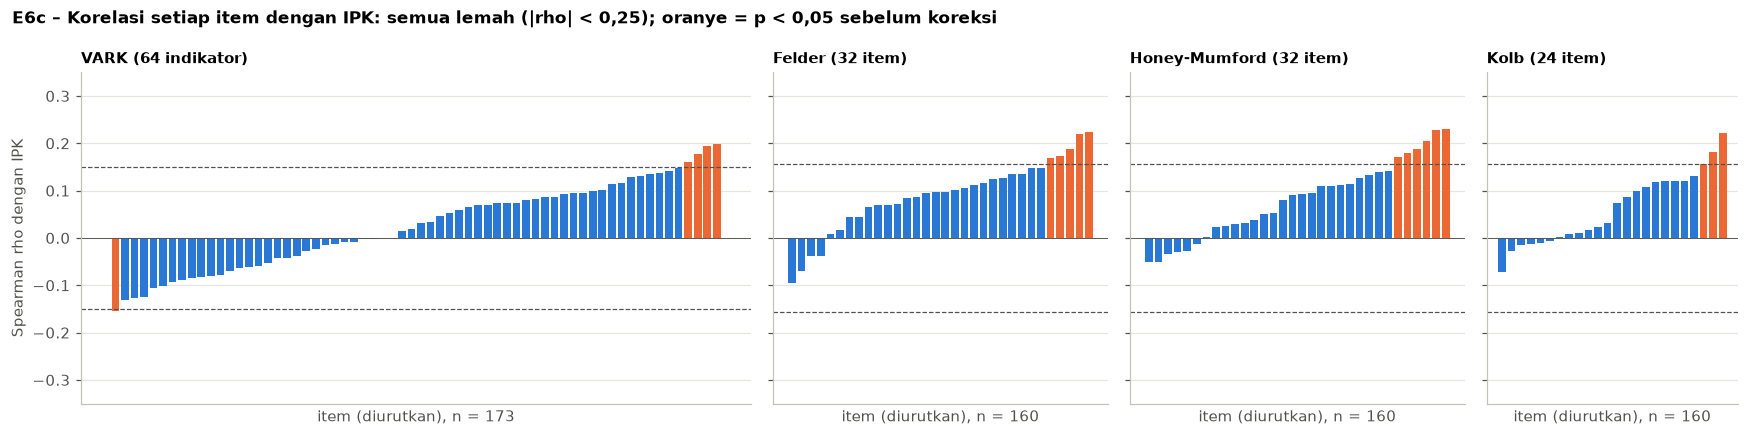

In [51]:
# 1) Target regresi: statistik IPK setelah cleaning + kondisi bermasalah
ipk = eda["IPK"].dropna()
q1, q3 = ipk.quantile([0.25, 0.75])
stat_ipk = pd.DataFrame({"IPK (setelah cleaning)": {
    "n terisi": len(ipk), "rata-rata": ipk.mean(), "simpangan baku": ipk.std(), "min": ipk.min(), "Q1": q1,
    "median": ipk.median(), "Q3": q3, "max": ipk.max(), "kemiringan (skew)": stats.skew(ipk)}}).round(2)
kondisi_ipk = pd.DataFrame({"Jumlah": {
    "IPK 0 tanpa IPS -> NaN (C6)": int((raw[IPK_COL] == 0).sum()),
    "IPK kosong setelah cleaning (tidak dipakai sebagai target)": int(eda["IPK"].isna().sum()),
    "IPK di luar 0-4": int(((ipk < 0) | (ipk > 4)).sum()),
    "IPK ekstrem bawah (< Q1 - 1,5 IQR), dipertahankan": int((ipk < q1 - 1.5 * (q3 - q1)).sum()),
    "IPK dipakai sebagai target regresi": len(ipk)}})
display(stat_ipk, kondisi_ipk)

# 2) Hubungan setiap item (calon fitur X) dengan IPK
FITUR = {"VARK (64 indikator)": (VARK_BIN_COLS, eda["IPK"].notna()),
         "Felder (32 item)": ([c for c in LIKERT_COLS if c.startswith("FS_")], ok & eda["IPK"].notna()),
         "Honey-Mumford (32 item)": ([c for c in LIKERT_COLS if c.startswith("HM_")], ok & eda["IPK"].notna()),
         "Kolb (24 item)": ([c for c in LIKERT_COLS if c.startswith("KOLB_")], ok & eda["IPK"].notna())}
korelasi_item, ringkas_item = {}, []
for fw, (kolom, baris) in FITUR.items():
    d = eda.loc[baris]
    hasil = pd.DataFrame([(c, *stats.spearmanr(d[c].astype(float), d["IPK"])) for c in kolom
                          if d[c].nunique() > 1], columns=["item", "rho", "p"]).set_index("item")
    hasil["q (FDR)"] = stats.false_discovery_control(hasil["p"])
    korelasi_item[fw] = hasil.sort_values("rho")
    terkuat = hasil["rho"].abs().idxmax()
    ringkas_item.append({"Framework": fw, "n": len(d), "Jumlah fitur": len(kolom),
                         "|rho| maks": round(hasil["rho"].abs().max(), 2), "Item terkuat": f"{terkuat} ({hasil.loc[terkuat, 'rho']:+.2f})",
                         "p < 0.05": int((hasil["p"] < 0.05).sum()), "Signifikan setelah FDR": int((hasil["q (FDR)"] < 0.05).sum())})
display(pd.DataFrame(ringkas_item).set_index("Framework"))

# 3) Grafik: korelasi setiap item dengan IPK, diurutkan; garis putus = batas p < 0.05
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True, gridspec_kw={"width_ratios": [64, 32, 32, 24]})
for ax, (fw, hasil) in zip(axes, korelasi_item.items()):
    n = FITUR[fw][1].sum()
    batas = 1.96 / np.sqrt(n - 1)                       # perkiraan |rho| untuk p = 0.05
    ax.bar(range(len(hasil)), hasil["rho"], color=[ORANYE if p < 0.05 else BIRU for p in hasil["p"]], width=0.8)
    for y in (batas, -batas):
        ax.axhline(y, color=TEKS, linestyle="--", linewidth=0.8)
    ax.axhline(0, color=TEKS, linewidth=0.6)
    ax.set_xticks([])
    ax.set_xlabel(f"item (diurutkan), n = {n}")
    ax.grid(axis="x", visible=False)
    ax.set_title(fw, fontsize=10)
axes[0].set_ylabel("Spearman rho dengan IPK")
axes[0].set_ylim(-0.35, 0.35)
fig.suptitle("E6c – Korelasi setiap item dengan IPK: semua lemah (|rho| < 0,25); oranye = p < 0,05 sebelum koreksi",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
simpan(fig, "E6c_item_vs_ipk")


**Interpretasi:**
- **Target IPK** (n = 173): median 3,42, rentang 0,87–4,00, dan **miring ke kiri** (skew −1,63). Kebanyakan IPK tinggi, dengan 8 nilai rendah yang dipertahankan karena valid. Saat regresi, error pada IPK rendah kemungkinan besar, dan MAE/RMSE perlu dibaca relatif terhadap simpangan baku 0,45.
- **Hubungan item dengan IPK lemah di semua framework** (|rho| maks 0,20–0,23). Jumlah item dengan p < 0,05 (3–6 per framework) hanya sedikit di atas yang diharapkan secara kebetulan, dan **tidak ada yang bertahan setelah koreksi FDR**.
- Item Likert hampir semuanya berkorelasi **positif** dengan IPK, apa pun dimensinya. Ini lebih cocok dijelaskan oleh kecenderungan menjawab "setuju" (E3) daripada oleh gaya belajar tertentu.

**Dampak untuk modelling (UAS):** R² regresi kemungkinan kecil dan bisa negatif; itu temuan yang sah dan perlu dibandingkan dengan baseline rerata. Model yang fleksibel seperti Random Forest juga perlu diwaspadai karena mudah *overfit* pada sinyal yang lemah.
**Yang tidak bisa disimpulkan:** korelasi bukan sebab-akibat, dan urutan waktu survei vs IPK tidak diketahui.


## E7 – Kesesuaian antar-framework (label kategorikal)
**Pertanyaan:** apakah label dari framework berbeda saling sejalan?
**Metode:** label bersifat nominal, jadi asosiasinya diukur dengan **Cramér's V** dari tabel kontingensi (chi-square), bukan korelasi numerik. Memakai responden tanpa straightliner; tabel silang HM vs Kolb hanya memakai kategori gaya (tanpa Seri dan Batas).


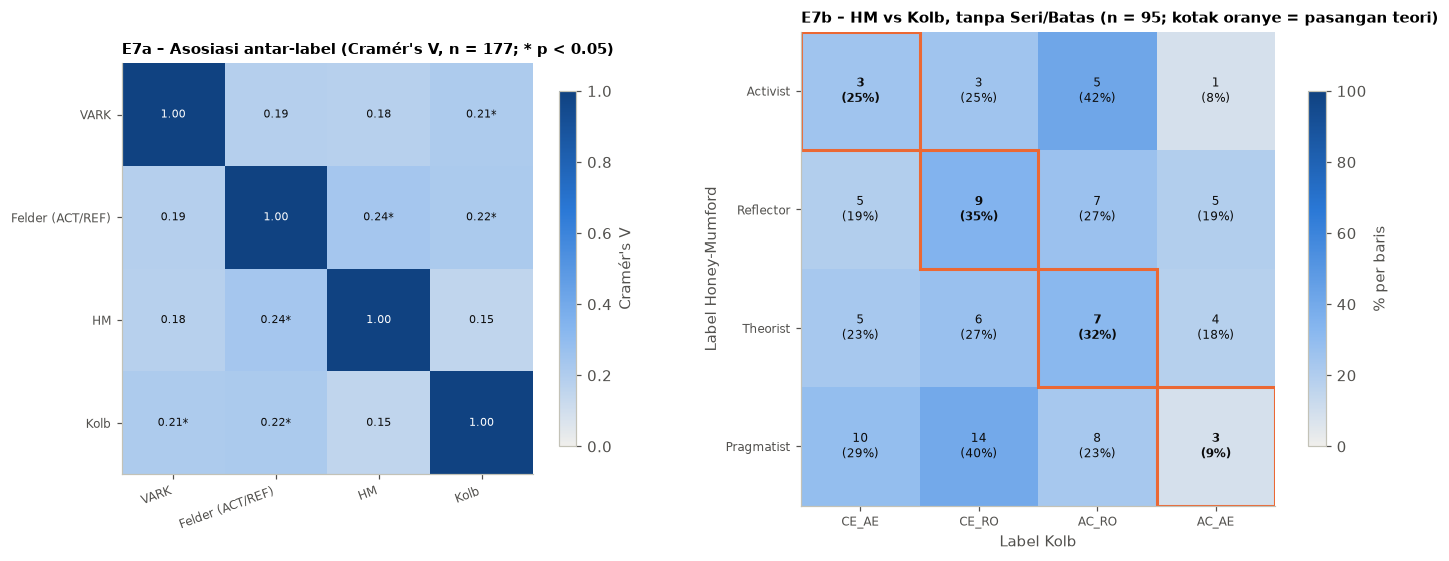

HM cocok dengan pasangan teorinya di Kolb: 22 dari 95 (23.2%) | kecocokan yang diharapkan kalau tidak berhubungan: 23.9% | Cramér's V = 0.13, p = 0.869
Sel tabel silang dengan frekuensi harapan < 5: 7 dari 16 -> p-value chi-square hanya indikatif


Cramér's V      p
Felder (ACT/REF) HM                     0.237  0.011
                 Kolb                   0.218  0.033
VARK             Kolb                   0.211  0.012
                 Felder (ACT/REF)       0.186  0.139
                 HM                     0.179  0.119
HM               Kolb                   0.149  0.476

In [52]:
def cramers_v(x, y):
    """Asosiasi dua variabel kategorikal (0 = tidak berhubungan, 1 = identik)."""
    tabel = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(tabel, correction=False)
    return np.sqrt(chi2 / (tabel.values.sum() * (min(tabel.shape) - 1))), p

# 1) Cramér's V antar-label (n = 177, tanpa straightliner); kategori Seri/Setara/Batas ikut sebagai kategori
nama_lab = {"VARK_label": "VARK", "FS_ACT_REF_label": "Felder (ACT/REF)", "HM_label": "HM", "KOLB_label": "Kolb"}
lab = eda.loc[ok, list(nama_lab)].rename(columns=nama_lab)
V = pd.DataFrame(index=lab.columns, columns=lab.columns, dtype=float)
P = V.copy()
for a in lab.columns:
    for b in lab.columns:
        V.loc[a, b], P.loc[a, b] = (1.0, 0.0) if a == b else cramers_v(lab[a], lab[b])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [0.85, 1.1]})
biru = LinearSegmentedColormap.from_list("biru", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
im = ax1.imshow(V.astype(float), cmap=biru, vmin=0, vmax=1)
ax1.set_xticks(range(len(V)), V.columns, rotation=20, ha="right", fontsize=8)
ax1.set_yticks(range(len(V)), V.index, fontsize=8)
for i in range(len(V)):
    for j in range(len(V)):
        bintang = "*" if (i != j and P.iloc[i, j] < 0.05) else ""
        ax1.text(j, i, f"{V.iloc[i, j]:.2f}{bintang}", ha="center", va="center", fontsize=7.5,
                 color="white" if V.iloc[i, j] > 0.6 else "#0b0b0b")
ax1.grid(False)
fig.colorbar(im, ax=ax1, shrink=0.75, label="Cramér's V")
ax1.set_title(f"E7a – Asosiasi antar-label (Cramér's V, n = {len(lab)}; * p < 0.05)", fontsize=10)

# 2) HM vs Kolb. Pasangan menurut teori: Activist~CE_AE, Reflector~CE_RO, Theorist~AC_RO, Pragmatist~AC_AE
URUT_HM = ["Activist", "Reflector", "Theorist", "Pragmatist"]
URUT_KOLB = ["CE_AE", "CE_RO", "AC_RO", "AC_AE"]
gaya = lab[lab["HM"].isin(URUT_HM) & lab["Kolb"].isin(URUT_KOLB)]
silang = pd.crosstab(gaya["HM"], gaya["Kolb"]).reindex(index=URUT_HM, columns=URUT_KOLB).fillna(0).astype(int)
persen_baris = silang.div(silang.sum(axis=1), axis=0) * 100
im2 = ax2.imshow(persen_baris, cmap=biru, vmin=0, vmax=100)
ax2.set_xticks(range(4), URUT_KOLB, fontsize=8)
ax2.set_yticks(range(4), URUT_HM, fontsize=8)
for i in range(4):
    for j in range(4):
        ax2.text(j, i, f"{silang.iloc[i, j]}\n({persen_baris.iloc[i, j]:.0f}%)", ha="center", va="center", fontsize=8,
                 fontweight="bold" if i == j else "normal", color="white" if persen_baris.iloc[i, j] > 60 else "#0b0b0b")
        if i == j:
            ax2.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=ORANYE, linewidth=2))
ax2.grid(False)
ax2.set_xlabel("Label Kolb")
ax2.set_ylabel("Label Honey-Mumford")
fig.colorbar(im2, ax=ax2, shrink=0.75, label="% per baris")
ax2.set_title(f"E7b – HM vs Kolb, tanpa Seri/Batas (n = {len(gaya)}; kotak oranye = pasangan teori)", fontsize=10)
simpan(fig, "E7_kesesuaian_antar_framework")

n_silang = silang.values.sum()
cocok = int(np.trace(silang.values))
cocok_acak = (silang.sum(axis=1).values * silang.sum(axis=0).values).sum() / n_silang ** 2 * 100
v_hk, p_hk = cramers_v(gaya["HM"], gaya["Kolb"])
print(f"HM cocok dengan pasangan teorinya di Kolb: {cocok} dari {n_silang} ({cocok / n_silang * 100:.1f}%) "
      f"| kecocokan yang diharapkan kalau tidak berhubungan: {cocok_acak:.1f}% | Cramér's V = {v_hk:.2f}, p = {p_hk:.3f}")
print("Sel tabel silang dengan frekuensi harapan < 5:",
      int((stats.chi2_contingency(silang)[3] < 5).sum()), "dari 16 -> p-value chi-square hanya indikatif")
atas = np.triu(np.ones(V.shape), k=1).astype(bool)
tabel_v = pd.DataFrame({"Cramér's V": V.where(atas).stack(), "p": P.where(atas).stack()}).dropna()
display(tabel_v.sort_values("Cramér's V", ascending=False).round(3))


**Interpretasi:**
- Asosiasi antar-label **lemah** (Cramér's V 0,15–0,24). Yang signifikan: Felder vs HM (0,24), Felder vs Kolb (0,22), dan VARK vs Kolb (0,21). Sebagian karena responden yang **seimbang** cenderung seimbang di beberapa framework sekaligus (Setara di Felder, Seri di HM, Batas di Kolb).
- **HM vs Kolb** (pasangan teori: Activist↔CE_AE, Reflector↔CE_RO, Theorist↔AC_RO, Pragmatist↔AC_AE): hanya **22 dari 95 (23,2%)** yang cocok, sama dengan kecocokan kalau keduanya tidak berhubungan (23,9%); Cramér's V = 0,15 (semua kategori) dan 0,13 (tanpa Seri/Batas), tidak signifikan.
- Kesimpulannya, **keempat framework tidak mengukur konstruk yang identik**, sehingga label satu framework tidak bisa dipakai menggantikan framework lain.

**Yang tidak bisa disimpulkan:** 7 dari 16 sel tabel silang HM vs Kolb punya frekuensi harapan < 5, jadi p-value chi-square hanya indikatif.


## E8 – Ringkasan temuan EDA

| # | Temuan | Dampak untuk tahap berikutnya |
|---|---|---|
| 1 | 192 dari 194 respons dipakai; 15 straightliner diberi flag | Analisis skor skala 1–5 memakai n = 177; keputusan straightliner saat modelling dijelaskan di UAS |
| 2 | Responden didominasi angkatan 2024 (56%); tanpa data prodi | Generalisasi terbatas |
| 3 | Data kosong hanya struktural (IPS, IPK); skor & label lengkap | Tidak perlu imputasi; IPK kosong tidak dipakai sebagai target regresi |
| 4 | Kecenderungan menjawab "setuju" kuat (68,9% jawaban 4/5) | Skor mentah antar-tipe sulit dibedakan; pakai skor selisih/perbandingan di dalam responden |
| 5 | Item tiap subskala konsisten (alpha 0,70–0,86) | Pengelompokan item per dimensi layak |
| 6 | Label (aturan panduan dosen) VARK dan Felder Active–Reflective seimbang; HM didominasi Seri (33%), Kolb didominasi Batas (36%); 31% responden Kolb tepat di garis 0 | Untuk klasifikasi, VARK atau Felder lebih siap; stratifikasi + macro-F1; HM/Kolb perlu perhatian pada kelas operasional dan kelas kecil (9%) |
| 7 | Hubungan antar-label lemah (Cramér's V ≤ 0,24); HM vs Kolb hanya 23% cocok (sama dengan acak) | Framework tidak saling menggantikan |
| 8 | IPK (n = 173) miring ke kiri (median 3,42); skor dan semua item tidak berkorelasi dengan IPK setelah koreksi FDR (|rho| ≤ 0,23); dari label, hanya VARK yang berbeda (kelompok Seri ber-IPK lebih tinggi, ε² = 0,09) | IPK sulit diprediksi dari fitur gaya belajar; bandingkan model regresi dengan baseline rerata dan interpretasi hati-hati |

**Keterbatasan:** sampel non-probabilitas dan didominasi satu angkatan; instrumen kelas bukan versi resmi sehingga cut-off/norma resmi tidak dipakai dan label mengikuti aturan operasional panduan dosen; angkatan hanya perkiraan; ada efek *acquiescence* karena semua item berarah positif.
